# The effective permittivity as a Stieltjes function: spectral measures, corners, plasmons, and what a spectrum determines

For a two-phase periodic cell the effective permittivity, as a function of the contrast, is a Stieltjes function: $F(s)=1-\varepsilon^*/\varepsilon_2=\int_0^1 d\mu(z)/(s-z)$ with $s=1/(1-h)$, $h=\varepsilon_1/\varepsilon_2$, and a positive measure $\mu$ on $[0,1]$ whose total mass is the area fraction $f$ of phase 1. The measure is the spectral measure of a self-adjoint operator on the inclusion at one vector, so everything that holds at all contrasts is a statement about $\mu$: the sum rules fix its first two moments, the Herglotz (Bergman-Milton) bounds at complex contrast are bounds on what a positive measure with those moments can do, plasmonic absorption is its density seen through Lorentzians, and the corners of the inclusion decide whether it is atomic or carries a band. This notebook asks what $\mu$ looks like for smooth inclusions, for corners, and for corners that touch; how each of three discretizations distorts it; what it implies for absorption and for bounds at complex contrast; and how many numbers of $\mu$ a measured spectrum can pin down, which is the imaging question: a spectrum is data, $\mu$ the unknown, the map between them linear and, as it turns out, severely ill-posed.

Three exact references make the questions answerable rather than merely plausible. The square array of disks has an exact measure, the eigenpairs of the real symmetric Rayleigh matrix. The checkerboard has an exact density, $d\mu=\pi^{-1}\sqrt{(1-z)/z}\,dz$, from $\varepsilon^*=\sqrt{\varepsilon_1\varepsilon_2}$. The square of side $1/2$ in the unit cell ($f=1/4$) has an exact density on exactly $[1/4,3/4]$ (the case $f=1/4$ of the Mortola-Steffe formula, Section 2(d)), which is the checkerboard's under an affine map; the notebook certifies it against bracketing solvers instead of taking it on trust. Every distortion below is measured against one of them, and the identities that tie a discrete measure to its solver hold to rounding, so a mismatch between a measure and its solver would be a bug (these identities are unit tests of the code path, not findings), while a distortion of the measure is the discretization.

## What this notebook shows

- Each of the three discretizations (conforming bilinear Q1, Fourier-Galerkin (FG) with exact Fourier coefficients, and the sampled Moulinec-Suquet scheme run through Lanczos) yields a finite measure whose Stieltjes transform equals its own solver to rounding (unit tests of the code path): the largest relative difference over $h=0.1,10,100$ is 4.2e-14 (Q1), 7.5e-15 (FG) and 5.6e-16 (Lanczos). The sum rule $m_0=f$ holds in all three; $m_1\le f(1-f)/2$ for the two conforming schemes, and the sampled scheme has $m_1=f(1-f)/2$ minus half the Nyquist energy, exactly.
- The disk array at $f=\pi\,0.3^2$ has one dominant atom at $z=0.3552494$ carrying 0.977158 of $f$ (Maxwell Garnett: 0.3586283), and the first lattice correction to the atom is the dipole-octupole coupling: its shift and weight loss follow $-3S_4^2f^3/(2\pi^4)$ and $3S_4^2f^2/\pi^4$ (to 4.7e-12 and 9e-5 relative), so the dilute-limit targets one might expect (shift below 1e-7, weight deficit below 1e-6; these were the expectation recorded before the computation) are wrong, because the dipole-octupole coupling enters at exactly those orders. An independent solver agrees with the Rayleigh matrix: at $h=10$ the certified FG brackets of the true disk, [1.599818, 1.634491] ($K=16$) and [1.601391, 1.618680] ($K=32$), contain the Rayleigh value 1.602942.
- FG and Q1 measures are Rayleigh-Ritz compressions: no FG atom carries more than 0.59 of $f$ where the exact measure has one carrying 0.977, and the Wasserstein-1 distance to the exact measure is not monotone in $K$ (0.0184, 0.0114, 0.0087, 0.0110 at $K=8,12,16,20$), whereas the sampled scheme converges (0.00564, 0.00283, 0.00223 at $N=64,128,256$). The weight FG puts at $z=0$ for a smooth disk falls like about $e^{-2.6K}$ over $K=4,6,8$ (5.85e-5, 3.25e-7, 1.71e-9), not like $1/K$, and then sits at a round-off floor of order $10^{-11}$ (1.59e-11, 1.24e-11, 2.44e-12 at $K=10,12,14$); Q1 has none.
- The square of side $1/2$ ($f=1/4$) has the exact solution $\varepsilon^*/\varepsilon_2=\sqrt{(1+3h)/(3+h)}$, that is $F(s)=1-\sqrt{(s-3/4)/(s-1/4)}$ (the case $f=1/4$ of the Mortola-Steffe formula for the four-phase checkerboard) and the density $\pi^{-1}\sqrt{(3/4-z)/(z-1/4)}$ on exactly $[1/4,3/4]$ (the checkerboard density under $z=1/4+z'/2$; mass 1/4, mean 3/8, variance of $\mu/f$ exactly 1/64). It lies inside all 9 certified Q1 brackets ($N=32,64,128$) and all 6 FG brackets ($K=16,64$); the Q1 solver obeys $L_hU_h=(1+3h)/(3+h)$ and $U_h[\square](1,h)=U_h[\mathrm{cb}](1,(1+3h)/(3+h))$ to 1.2e-13, and the Q1 square measure is the affine image of the Q1 checkerboard measure (W1 below 7e-16).
- The Q1 checkerboard carries an atom at $z=0$, because diagonal tiles share a node: its weight is 0.197755, 0.179361, 0.168280, 0.154816, 0.146503, 0.129727, 0.116399 at $N=16,24,32,48,64,128,256$, equals the percolation limit to 1.4e-7 at $N\le48$, and $1/\mu_0=c+(4/\pi)\ln N+d/N^2$ with $c=1.5308$ and $d=-1.08$ (a free-slope fit returns 1.273231 against $4/\pi=1.273240$; the local slopes fall from 1.27905 over $N=16$ to 24 to 1.27328 over $N=192$ to 256, the excess halving at each step). The slope is derived below by a spreading-resistance argument; $c$ is not. The sampled checkerboard has $m_0$, $m_1$, $m_2$, $\alpha_0$, $\beta_1$ exact; $\alpha_1,\dots,\alpha_4$ and $\beta_2,\dots,\beta_5$ converge with $N$, while $\alpha_k$ for $k\ge5$ (printed up to $k=19$) does not converge over $N=64$ to $256$ and sits at order 0.1 from about $k=8$ on.
- Corners. For this cell the measure is absolutely continuous with support exactly $[1/4,3/4]$, so the whole Perfekt-Putinar band of a 90-degree corner is charged (both edges; this is one cell, not a test of the polygon theorem). The natural FG counting statistics (atoms carrying 99%, weight outside $[0.23,0.77]$; the expectation recorded before the computation was that they would separate the two) do not separate the square from the equal-area disk, because FG compresses any measure into a cluster of atoms. The variance does separate them (0.01766 against 0.00353 at $K=24$) and has exact references: 1/64 for the square (the FG variance decreases 0.02291, 0.02131, 0.01956, 0.01863, 0.01805, 0.01766 over $K=6$ to 24 and the FG measure approaches the exact one in $W_1$: 0.0154 to 0.0060) and 0.00030 for the disk (still 11.8 times higher at $K=24$). The FG weight below $z=1/4$ (0.0865 at $K=24$; the exact measure has none) is Ritz leakage. The Q1 square has no weight below $1/4$ and 0.3955, 0.3366, 0.3096 of its weight exactly at $1/4$ ($N=16,32,48$): that is the checkerboard's percolation atom relabeled ($w/f=2\mu_0$), vanishing like $1/((2/\pi)\ln N)$ (0.2328 at $N=256$), a Q1 stand-in for the $(z-1/4)^{-1/2}$ edge singularity and no independent evidence about the corner. A side scan shows that this behavior is specific to the cell $f=1/4$: the lowest Q1 atom falls with the side (0.2999, 0.2757, 0.2634, 0.2500, 0.2285, 0.1859, 0.1094 for sides 2 to 14 at $N=16$), squares with $f>1/4$ put 0.56, 0.79, 0.997 of their weight below $1/4$, and an $8\times4$ rectangle puts 0.75 there. The four-tile exponents at negative contrast are $\pm(4i/\pi)\,\mathrm{artanh}\sqrt{\min(|\kappa|,1/|\kappa|)}$, with the other pair at $2\pm iy$ (smallest singular value of the matching matrix at most 3.5e-16 at all of them).
- Plasmonics. For every microstructure $\int_0^\infty\omega\,\mathrm{Im}\,\varepsilon^*\,d\omega=(\pi/2)f\omega_p^2$ (verified to 1.5e-14 for five curves, including the exact square). A Lorentzian peak sits at $\omega_0-\gamma^2/(8\omega_0)$; the lossless checkerboard absorbs, with $\mathrm{Im}\,\varepsilon^*\to\sqrt{|\varepsilon_1|}$, computed through the density's Stieltjes transform. The exact square absorbs without loss in a continuous band $0.5<\omega/\omega_p<0.866$, $\mathrm{Im}\,\varepsilon^*\to\sqrt{(3/4-\omega^2)/(\omega^2-1/4)}$ (checked through its density to 9.1e-12 and zero outside to 1.4e-6); the FG square's cluster of peaks below $\omega=0.5$ is a discretization artifact.
- The order of limits. At fixed resolution, $\mathrm{Im}\,\varepsilon^*_h$ at $\varepsilon_1=-2+i\delta$ is linear in $\delta$ (ratio 1.0000 to 1.0003 between $\delta=10^{-4}$ and $10^{-3}$; a Taylor identity of a finite sum), so it vanishes with the loss, while the continuum value tends to $\sqrt2$. At $\delta=0.1$ the error does not decrease monotonically with resolution for either scheme, although $W_1$ of the measure to the exact one does (Q1 0.0265 to 0.0205, FG 0.0251 to 0.0146).
- Bounds. The exact values lie inside the Bergman-Milton regions (a theorem for any positive measure with the right moments, so this tests the support solver). The extremal measures of the isotropic problem are Maxwell Garnett (a corner, attained on one contiguous arc of 224, 53, 43 of 720 directions at the three contrasts), the $\{0,1\}$ measure (the same counts, also one arc), and $\{0,z\}$ and $\{z,1\}$ arcs. The $\{0,1\}$ measure is a second corner of the lens (not a microstructure); the Hashin-Shtrikman point with phase 1 as host is a smooth boundary point (gap ratios 3.63 to 4.56 on doubling the offset). The lens is valid but is not claimed to be the sharp isotropic region, which needs the phase-swapped measure (Milton 1981) and was not intersected.
- A spectrum is a nearly rank-deficient linear functional of $\mu$. Counts are relative to each design's own largest singular value. Real contrasts of one sign ($h>1$) carry 3 to 6 numbers (30 dB power to $10^{-3}$), real contrasts of both signs ($h$ and $1/h$) carry 6 to 11, Drude spectra with $\gamma=0.20$ carry 12 to 22 and with $\gamma=0.05$ carry 38 to 75; row-normalizing the data changes the counts by at most 3 (7 to 12 for both signs). More contrasts within the same range do not help; moving the probe along the support does.

## Conventions

Time dependence $e^{-i\omega t}$, so loss is $\mathrm{Im}\,\varepsilon>0$ and $\varepsilon_1=1-\omega_p^2/(\omega(\omega+i\gamma))$ for a Drude inclusion in vacuum, which gives $s=\omega(\omega+i\gamma)/\omega_p^2$. The problem is static: "TM" plays no role here. Lengths are in units of the period. Phase 1 is the inclusion (indicator $\chi$, area fraction $f$), phase 2 the host; $h=\varepsilon_1/\varepsilon_2$; "$\sigma$" and "$\varepsilon$" are interchangeable. $\mu$ has atoms $(z_k,w_k)$; $m_k=\sum_k w_kz_k^k$. The area fraction of the disk of radius $0.3$ is $f=\pi\,0.3^2=0.282743$ throughout (never the rounded 0.2827, which moves the dominant atom by the amount printed in Section 2). "Q1" is the conforming bilinear scheme on pixels, "FG" is Fourier-Galerkin with the exact Fourier coefficients of the true geometry, "sampled" is the Moulinec-Suquet scheme on pixel-center samples. $W_1$ is the Wasserstein-1 distance, $\int|\mathrm{CDF}_1-\mathrm{CDF}_2|\,dz$. Atoms of discrete measures that agree within $10^{-9}$ are merged before any per-atom statistic (cells with $C_4$ symmetry have exactly degenerate pairs, and the eigensolver splits their weight arbitrarily). Checks print PASS or FAIL and assert.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported
os.environ.setdefault("NPROC", "4")  # size of the XLA CPU thread pool (never 2: see scripts/batch_run.py)
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=" + ("false" if os.environ["NPROC"] == "1" else "true"))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/homogenization (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name


def check_in(name, value, lo, hi):
    """Print PASS or FAIL for lo <= value <= hi (a bound, an interval, a sign) and assert it."""
    ok = lo <= value <= hi
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, required in [{lo:.6g}, {hi:.6g}]")
    assert ok, name

In [2]:
import sys, pathlib, time
T_START = time.perf_counter()                       # run time is measured from this cell
sys.path.insert(0, str(pathlib.Path.cwd()))         # the modules sit next to this notebook
import scipy.integrate as si
import scipy.optimize as so
import warnings
warnings.filterwarnings("ignore", category=si.IntegrationWarning)   # quad near a pole 1e-6 from the path warns about round-off; accuracy is checked against closed forms
import cellsolver as cs
import spectral as sp
import rayleigh as ry
import bounds as bd

F_ROD = np.pi * 0.3 ** 2                            # area fraction of the disk of radius 0.3: used everywhere, never the rounded 0.2827


def merge(z, w, tol=1e-9):
    """Merge atoms closer than tol (exactly degenerate pairs of C4 cells come out of eigh with arbitrary weight split)."""
    o = np.argsort(z)
    z, w = np.asarray(z)[o], np.asarray(w)[o]
    g = np.concatenate([[0], np.cumsum(np.diff(z) > tol)])
    wm = np.bincount(g, w)
    zm = np.bincount(g, w * z) / np.where(wm > 0, wm, 1.0)
    first = np.array([z[np.argmax(g == k)] for k in range(g[-1] + 1)])
    return np.where(wm > 0, zm, first), wm


def quantile(z, w, p):
    """Smallest atom position at which the CDF reaches the fraction p of the total weight."""
    o = np.argsort(z)
    c = np.cumsum(np.asarray(w)[o]) / np.sum(w)
    return np.asarray(z)[o][np.searchsorted(c, p - 1e-12)]


def spread(z, w):
    """Variance of the normalized measure mu/f."""
    f = np.sum(w)
    m = np.sum(w * z) / f
    return np.sum(w * z ** 2) / f - m ** 2


def window(z, w, lo, hi):
    """Weight fraction and weighted centroid of the atoms in [lo, hi]."""
    k = (z >= lo) & (z <= hi)
    return np.sum(w[k]) / np.sum(w), (np.sum(w[k] * z[k]) / np.sum(w[k]) if np.any(k) else np.nan)


def lost_nyquist_energy(chi):
    """Sum of |chihat(k)|^2 over the modes k != 0 whose Nyquist-zeroed wavevector vanishes: (N/2,0), (0,N/2), (N/2,N/2)."""
    n = chi.shape[0]
    c = np.fft.fft2(chi) / n ** 2
    return float(abs(c[n // 2, 0]) ** 2 + abs(c[0, n // 2]) ** 2 + abs(c[n // 2, n // 2]) ** 2) if n % 2 == 0 else 0.0

## 1. One Stieltjes function, three discretizations

Let $\Gamma$ be the orthogonal projector of $L^2(\text{cell};\mathbb R^2)$ onto zero-mean gradients, $\hat\Gamma(k)=kk^{\mathsf T}/|k|^2$, and write $\varepsilon=\varepsilon_2(1-\chi/s)$. For $E=e+\nabla\phi$ the equation $\nabla\cdot(\varepsilon E)=0$ says that $(1-\chi/s)E$ is orthogonal to all gradients, $\Gamma[(1-\chi/s)E]=0$, that is $E-e=\Gamma[\chi E]/s$. With $T=\chi\Gamma\chi$ on $L^2(\chi)$ (self-adjoint, $0\le T\le1$), $u=\chi e$ and $v=\chi E$ this reads $(s-T)v=su$, and $\varepsilon^*e=\varepsilon_2(e-\langle v\rangle/s)$ gives

$$F(s)=1-\frac{\varepsilon^*}{\varepsilon_2}=\langle u,(s-T)^{-1}u\rangle=\int_0^1\frac{d\mu(z)}{s-z}\quad(|e|=1).$$

So $\mu$ is the spectral measure of $T$ at $u$ (the Bergman-Milton representation; Bergman 1978, Milton 2002), with moments $m_k=\langle u,T^ku\rangle$. The first two are $m_0=\|u\|^2=f$ and $m_1=\langle u,\Gamma u\rangle=\sum_{k\ne0}|\hat\chi(k)|^2(k\cdot e)^2/|k|^2$, which for a cell with $C_4$ symmetry averages to $\tfrac12\sum_{k\ne0}|\hat\chi(k)|^2=\tfrac12f(1-f)$ by Parseval. In terms of the contrast, $\varepsilon^*/\varepsilon_2=1-\sum_kw_k(1-h)/(1-z_k(1-h))$, which is also valid at $h=1$.

Three finite approximations of $\mu$ are compared.

- **Q1.** On the pinned periodic bilinear space, with $K$ the unit-coefficient stiffness, $K_1$ that of the phase-1 pixels and $b$ the phase-1 load, the pencil $K_1v=tKv$ (with $V^{\mathsf T}KV=I$) gives $F_h(s)=f/s+s^{-1}\sum_kw_k/(s-t_k)$, $w_k=(v_k^{\mathsf T}b)^2$. Partial fractions put the weight $w_k/t_k$ at $t_k$ and the remainder $f-\sum w_k/t_k$ at $z=0$. This atom at zero equals $\lim U_h/\sigma_1$ as $\sigma_1\to\infty$, so it is nonzero exactly when phase 1 percolates in the discrete space, and pixels that touch only at a corner are connected in Q1.
- **FG.** The Fourier-Galerkin method (Vondrejc, Zeman and Marek 2015, whose bounds the bracket of `cellsolver` follows; Vondrejc 2016 for exact coefficients): trigonometric polynomials of degree $K$ and the exact coefficients of the indicator of the true geometry: the same structure with a Hermitian matrix $H[l,k]=(k\cdot l)\hat\chi(l-k)/(|k||l|)$ and load $(l_e/|l|)\hat\chi(l)$. It is the compression of $T$ to a finite trial space, hence a Rayleigh-Ritz object.
- **Sampled.** The Moulinec-Suquet operator $T=\chi\Gamma\chi$ on pixel-center samples with the Nyquist-zeroed symbol (the scheme of Moulinec and Suquet 1998); Lanczos from $u/\|u\|$ with full reorthogonalization gives the $m$-step Gauss rule: atoms are Ritz values, weights $f$ times the squared first components. It reproduces the first $2m$ moments of the sampled measure and converges geometrically in $m$ for $s$ outside $[0,1]$.

*Prediction to test.* No trigonometric polynomial is affine on a disk, so the FG measure of an isolated disk carries a positive atom at $z=0$; a natural guess is $O(1/K)$, which turns out to be wrong. A Q1 measure of an isolated pixel disk carries none, since Q1 can be affine on any non-percolating pixel set. The sampled scheme's first moment is $f(1-f)/2$ minus half the Nyquist energy $\sum|\hat\chi(k)|^2$ over the modes $k\ne0$ whose Nyquist-zeroed wavevector vanishes, namely $(N/2,0)$, $(0,N/2)$, $(N/2,N/2)$, for $x\leftrightarrow y$ symmetric cells.

In [3]:
# 1. three discretizations of the same disk
print(f"disk R = 0.3, f = pi R^2 = {F_ROD:.6f}")
t0 = time.perf_counter()
d32 = cs.disk_pixels(32, 0.3, 1.0, 0.0)
f32 = d32.mean()
zq, wq = sp.q1_measure(d32)
zf, wf = sp.fg_measure("disk", 16, R=0.3)
d128 = cs.disk_pixels(128, 0.3, 1.0, 0.0)
f128 = d128.mean()
zl1, wl1 = sp.lanczos_measure(d128, steps=150)
zl3, wl3 = sp.lanczos_measure(d128, steps=300)
print(f"built three measures in {time.perf_counter() - t0:.1f} s: Q1 N=32 ({len(zq)} atoms, pixel fraction {f32:.6f}), "
      f"FG K=16 ({len(zf)} atoms), Lanczos N=128 ({len(zl1)} and {len(zl3)} atoms, pixel fraction {f128:.6f})")
print(f"\n{'h':>6s} {'Q1 direct':>12s} {'Q1 measure':>12s} {'rel diff':>9s} | {'FG upper':>12s} {'FG measure':>12s} {'rel diff':>9s} | "
      f"{'sampled':>12s} {'Lanczos 300':>12s} {'rel diff':>9s} {'|300-150|':>9s}")
for h in (0.1, 10.0, 100.0):
    dq = cs.q1_effective(np.where(d32 > 0, h, 1.0))[0, 0]
    mq = sp.eps_ratio_from_measure(zq, wq, h)
    _, df, info = cs.fg_bracket("disk", 16, s_in=h, s_out=1.0, R=0.3)
    assert info["converged"]
    mf = sp.eps_ratio_from_measure(zf, wf, h)
    ds = cs.spectral_sampled(np.where(d128 > 0, h, 1.0), tol=1e-11, directions=(0,))[0][0, 0]
    m3 = sp.eps_ratio_from_measure(zl3, wl3, h)
    m1_ = sp.eps_ratio_from_measure(zl1, wl1, h)
    print(f"{h:6g} {dq:12.8f} {mq:12.8f} {abs(mq / dq - 1):9.1e} | {df:12.8f} {mf:12.8f} {abs(mf / df - 1):9.1e} | "
          f"{ds:12.8f} {m3:12.8f} {abs(m3 / ds - 1):9.1e} {abs(m3 - m1_):9.1e}")
    check(f"unit test (algebraic identity): Q1 measure reproduces q1_effective, h = {h:g}", abs(mq / dq - 1), 1e-10)
    check(f"unit test (algebraic identity): FG measure reproduces the fg_bracket upper bound, h = {h:g}", abs(mf / df - 1), 1e-10)
    check(f"unit test (algebraic identity up to PCG error): Lanczos measure (300 steps) reproduces spectral_sampled, h = {h:g}", abs(m3 / ds - 1), 1e-10)

disk R = 0.3, f = pi R^2 = 0.282743


built three measures in 0.8 s: Q1 N=32 (325 atoms, pixel fraction 0.277344), FG K=16 (686 atoms), Lanczos N=128 (150 and 300 atoms, pixel fraction 0.282471)

     h    Q1 direct   Q1 measure  rel diff |     FG upper   FG measure  rel diff |      sampled  Lanczos 300  rel diff |300-150|
   0.1   0.62595630   0.62595630   4.4e-16 |   0.62507123   0.62507123   2.2e-16 |   0.62307324   0.62307324   3.3e-16   0.0e+00
PASS  unit test (algebraic identity): Q1 measure reproduces q1_effective, h = 0.1: got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-10
PASS  unit test (algebraic identity): FG measure reproduces the fg_bracket upper bound, h = 0.1: got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-10
PASS  unit test (algebraic identity up to PCG error): Lanczos measure (300 steps) reproduces spectral_sampled, h = 0.1: got 3.33067e-16, target 0, |diff| 3.33e-16 <= 1e-10
    10   1.61366412   1.61366412   3.0e-15 |   1.63449134   1.63449134   6.7e-16 |   1.60494909   1.60494909   1.1e-16   6.7e-16

   100   1.79958514   1.79958514   4.2e-14 |   1.86475534   1.86475534   7.5e-15 |   1.77594390   1.77594390   5.6e-16   1.3e-15
PASS  unit test (algebraic identity): Q1 measure reproduces q1_effective, h = 100: got 4.19664e-14, target 0, |diff| 4.20e-14 <= 1e-10
PASS  unit test (algebraic identity): FG measure reproduces the fg_bracket upper bound, h = 100: got 7.54952e-15, target 0, |diff| 7.55e-15 <= 1e-10
PASS  unit test (algebraic identity up to PCG error): Lanczos measure (300 steps) reproduces spectral_sampled, h = 100: got 5.55112e-16, target 0, |diff| 5.55e-16 <= 1e-10


The three columns of "rel diff" show that each measure reproduces its own solver to at most 4.2e-14 relative (tolerance $10^{-10}$, a priori). The expectation recorded before the computation was that the Lanczos comparison at $h=100$ ($s=-0.0101$, the slowest case) would need 300 or 600 steps; the printed $|300-150|$ column shows 150 steps are already converged to 1.3e-15, since the Gauss error decays geometrically with the Chebyshev-ellipse parameter of $s$ for $[0,1]$. The agreement with `spectral_sampled` is at machine precision (3.3e-16 to 5.6e-16): the solver's PCG residual tolerance is $10^{-11}$ and its energy is quadratic in the PCG error, which is why the two values agree far better than the residual; the tolerance was tightened from $10^{-8}$, set beforehand, to $10^{-10}$ after seeing this. The three agreements are unit tests of the code path (each measure is the solver's own algebra), not findings. The three schemes give different $\sigma^*$ for the same nominal disk because they discretize different geometries (the pixel fractions printed are 0.277344 at $N=32$ and 0.282471 at $N=128$, against $\pi\,0.3^2$ for FG).

In [4]:
# sum rules of the three measures and the atom at 0
m_q, m_f, m_l = sp.moments(zq, wq, 2), sp.moments(zf, wf, 2), sp.moments(zl3, wl3, 2)
nyq = lost_nyquist_energy(d128)
print(f"{'scheme':16s} {'f':>10s} {'m0 - f':>10s} {'m1':>12s} {'f(1-f)/2':>12s} {'m1 - f(1-f)/2':>14s}")
print(f"{'Q1 N=32':16s} {f32:10.6f} {m_q[0] - f32:10.1e} {m_q[1]:12.8f} {f32 * (1 - f32) / 2:12.8f} {m_q[1] - f32 * (1 - f32) / 2:14.3e}")
print(f"{'FG K=16':16s} {F_ROD:10.6f} {m_f[0] - F_ROD:10.1e} {m_f[1]:12.8f} {F_ROD * (1 - F_ROD) / 2:12.8f} {m_f[1] - F_ROD * (1 - F_ROD) / 2:14.3e}")
print(f"{'Lanczos N=128':16s} {f128:10.6f} {m_l[0] - f128:10.1e} {m_l[1]:12.8f} {f128 * (1 - f128) / 2:12.8f} {m_l[1] - f128 * (1 - f128) / 2:14.3e}")
check("unit test (by construction): Q1 sum of weights equals the pixel fraction", m_q[0] - f32, 1e-12)
check("unit test (by construction): FG sum of weights equals pi R^2", m_f[0] - F_ROD, 1e-12)
check("unit test (by construction): Lanczos sum of weights equals the pixel fraction", m_l[0] - f128, 1e-12)
check_in("Q1 first moment is at most f(1-f)/2", m_q[1] - f32 * (1 - f32) / 2, -1.0, 0.0)
check_in("FG first moment is at most f(1-f)/2", m_f[1] - F_ROD * (1 - F_ROD) / 2, -1.0, 0.0)
check("Lanczos first moment equals f(1-f)/2 minus half the Nyquist energy (disk centered on a pixel edge)", m_l[1], 1e-12, f128 * (1 - f128) / 2 - 0.5 * nyq)
print(f"Nyquist energy lost by the sampled scheme for the centered N=128 disk: {nyq:.3e} (zero: the cell is mirror symmetric about a pixel edge)")
# a cell that does lose energy: the same disk centered on a pixel (x <-> y symmetric, Nyquist modes nonzero)
for Nn in (62, 64):
    c_ = (0.5 + 0.5 / Nn, 0.5 + 0.5 / Nn)
    dsh = cs.disk_pixels(Nn, 0.3, 1.0, 0.0, center=c_)
    fsh = dsh.mean()
    zs_, ws_ = sp.lanczos_measure(dsh, steps=120)
    e_ = lost_nyquist_energy(dsh)
    check(f"first moment identity, disk centered on a pixel, N = {Nn} (Nyquist energy {e_:.2e})", sp.moments(zs_, ws_, 1)[1], 1e-12, fsh * (1 - fsh) / 2 - 0.5 * e_)

# the atom at 0
print("\natom at 0 (weight at z <= 1e-10) and weight in (0, 0.05]:")
print(f"{'Q1 isolated disk, N=32':28s} {abs(wq[0]) if zq[0] <= 1e-10 else 0.0:10.2e}")
mu0 = {}
Ks = [4, 6, 8, 10, 12, 14]
for K in Ks:
    z_, w_ = sp.fg_measure("disk", K, R=0.3)
    mu0[K] = w_[0] if z_[0] <= 1e-10 else 0.0
    low = np.sum(w_[(z_ > 1e-10) & (z_ <= 0.05)])
    print(f"{'FG disk K = %d' % K:28s} {mu0[K]:10.2e}   weight in (0, 0.05]: {low:9.2e}")
fitK = [4, 6, 8]                                   # K >= 10 sits at the round-off floor of the eigenvalue solver (about 1e-11)
lw = np.log([mu0[K] for K in fitK])
slope, icpt = np.polyfit(fitK, lw, 1)
resid = np.max(np.abs(lw - (slope * np.array(fitK) + icpt)))
steps = [mu0[K] / mu0[K + 2] for K in (4, 6, 8)]
steps = [mu0[K] / mu0[K + 2] for K in (4, 6, 8, 10, 12)]
print(f"log-linear fit over K = 4, 6, 8: ln mu0 = {icpt:.2f} {slope:+.3f} K, largest residual {resid:.3f}; successive ratios mu0(K)/mu0(K+2) for K = 4, 6, 8, 10, 12: "
      + ", ".join(f"{r:.0f}" for r in steps) + " (from K = 8 on the values sit at a round-off floor of about 1e-11 and the ratios are not geometric)")
print("(a direct sigma1 -> infinity solve with fg_bracket does not bypass this: its CG does not converge in 3000 iterations at sigma1 = 1e8 for K >= 8, so it was not used)")
print(f"a 1/K law would give mu0(10)/mu0(4) = 0.4; found {mu0[10] / mu0[4]:.1e}")
check_in("Q1 isolated disk: atom at 0", abs(wq[0]) if zq[0] <= 1e-10 else 0.0, 0.0, 1e-12)
check_in("FG disk atom at 0 is positive at K = 4 to 14", min(mu0.values()), 1e-15, 1.0)
check_in("FG disk atom at 0 decreases at every step in K = 4, 6, 8, 10, 12, 14 (largest step)", float(np.max(np.diff([mu0[K] for K in Ks]))), -1.0, 0.0)
check_in("ln mu0 is linear in K over K = 4, 6, 8 (largest residual of the fit)", resid, 0.0, 0.1)
check_in("each step of 2 in K from 4 to 8 lowers mu0 by a factor of at least 50", min(steps[:2]), 50.0, 1e6)
print(f"extrapolating the K = 4, 6, 8 fit to K = 10 predicts {np.exp(icpt + slope * 10):.2e}; found {mu0[10]:.2e}, a factor {mu0[10] / np.exp(icpt + slope * 10):.1f} above")

scheme                    f     m0 - f           m1     f(1-f)/2  m1 - f(1-f)/2
Q1 N=32            0.277344    5.6e-17   0.09857070   0.10021210     -1.641e-03
FG K=16            0.282743   -5.6e-17   0.09881345   0.10139977     -2.586e-03
Lanczos N=128      0.282471   -5.6e-17   0.10134050   0.10134050      8.327e-17
PASS  unit test (by construction): Q1 sum of weights equals the pixel fraction: got 5.55112e-17, target 0, |diff| 5.55e-17 <= 1e-12
PASS  unit test (by construction): FG sum of weights equals pi R^2: got -5.55112e-17, target 0, |diff| 5.55e-17 <= 1e-12
PASS  unit test (by construction): Lanczos sum of weights equals the pixel fraction: got -5.55112e-17, target 0, |diff| 5.55e-17 <= 1e-12
PASS  Q1 first moment is at most f(1-f)/2: got -0.0016414, required in [-1, 0]
PASS  FG first moment is at most f(1-f)/2: got -0.00258632, required in [-1, 0]
PASS  Lanczos first moment equals f(1-f)/2 minus half the Nyquist energy (disk centered on a pixel edge): got 0.101341, target 0.1

FG disk K = 12                 1.24e-11   weight in (0, 0.05]:  3.25e-03


FG disk K = 14                 2.44e-12   weight in (0, 0.05]:  1.55e-03
log-linear fit over K = 4, 6, 8: ln mu0 = 0.71 -2.611 K, largest residual 0.019; successive ratios mu0(K)/mu0(K+2) for K = 4, 6, 8, 10, 12: 180, 190, 108, 1, 5 (from K = 8 on the values sit at a round-off floor of about 1e-11 and the ratios are not geometric)
(a direct sigma1 -> infinity solve with fg_bracket does not bypass this: its CG does not converge in 3000 iterations at sigma1 = 1e8 for K >= 8, so it was not used)
a 1/K law would give mu0(10)/mu0(4) = 0.4; found 2.7e-07
PASS  Q1 isolated disk: atom at 0: got 9.99201e-16, required in [0, 1e-12]
PASS  FG disk atom at 0 is positive at K = 4 to 14: got 2.43883e-12, required in [1e-15, 1]
PASS  FG disk atom at 0 decreases at every step in K = 4, 6, 8, 10, 12, 14 (largest step): got -3.49898e-12, required in [-1, 0]
PASS  ln mu0 is linear in K over K = 4, 6, 8 (largest residual of the fit): got 0.0185696, required in [0, 0.1]
PASS  each step of 2 in K from 4 to 8

All three sum rules $m_0=f$ hold to rounding. The two conforming schemes lie strictly below the isotropic value $m_1=f(1-f)/2$ (by 1.641e-3 for Q1 at $N=32$, and 2.586e-3 for FG at $K=16$), as the variational argument says. The sampled scheme meets $m_1=f(1-f)/2-\frac12\mathcal E_{\rm Nyq}$ to rounding; for the centered disk $\mathcal E_{\rm Nyq}$ is zero (the cell is mirror symmetric about a pixel edge, which kills the Nyquist modes), so the same identity is also checked for disks centered on a pixel, where $\mathcal E_{\rm Nyq}$ is nonzero (1.27e-05 at $N=62$, 9.72e-06 at $N=64$). That refines the natural statement that only $(N/2,N/2)$ is lost: the lost modes are the three listed above.

The atom at zero separates the prediction from what was found. For Q1 the isolated pixel disk has none (at most $10^{-15}$). For FG it is positive but it falls geometrically at first, by a factor of 180 and 190 per step of 2 in $K$ and then 108: $\ln\mu_0=0.71-2.611K$ over $K=4,6,8$ with largest residual 0.019, against 0.4 for $\mu_0(10)/\mu_0(4)$ under a $1/K$ law (found 2.7e-07). The rate is stated for $K=4$ to 8 only (three points with successive ratios 180 and 190, so the constant $-2.6$ is approximate; "super-algebraic" is what the data support). From $K=10$ on the values 1.59e-11, 1.24e-11, 2.44e-12 sit at a round-off floor of the eigensolver and are not geometric (successive ratios 1 and 5; the fit predicts 9.3e-12 at $K=10$, found a factor 1.7 higher; the $K=10$ value depends on the thread count). A direct $\sigma_1\to\infty$ solve with `fg_bracket` does not bypass the floor: its CG does not converge in 3000 iterations at $\sigma_1=10^8$ for $K\ge8$. The affine function $-x_e$ on the disk has a smooth periodic extension to the cell, so its trigonometric approximation converges spectrally, which is consistent with the printed rate. What remains at low $z$ is not an atom at zero: the weight in $(0,0.05]$ is 1.59e-02, 4.82e-03, 3.03e-03, 2.58e-03 for $K=4,6,8,10$, slowly decreasing small positive atoms. The guess of a spurious atom of order $1/K$ is therefore wrong; the tolerances on the log-linear fit (residual at most 0.1) and on the step factor (at least 50) were set after seeing the run.

## 2. Exact measures

(a) *Maxwell Garnett* is a single atom of weight $f$ at $z=(1-f)/2$; for the isolated disk, as $f\to0$, $z=1/2$. Indeed $1-f/(s-(1-f)/2)$ equals $(1+\beta f)/(1-\beta f)$ with $\beta=(h-1)/(h+1)$.

(b) *Checkerboard.* From $\varepsilon^*=\sqrt{\varepsilon_1\varepsilon_2}$ (Keller-Dykhne; notebook 01) one has $F(s)=1-\sqrt{1-1/s}$, whose density is $d\mu=\pi^{-1}\sqrt{(1-z)/z}\,dz$ on $(0,1)$ with CDF $M(z)=\pi^{-1}[\arcsin\sqrt z+\sqrt{z(1-z)}]$. There are no atoms. Since $\sum_kC_ky^k=(1-\sqrt{1-4y})/(2y)$ with $y=1/(4s)$ gives $1-\sqrt{1-1/s}=\sum_kC_k4^{-k}s^{-k-1}/2$, the moments are $m_k=C_k/(2\cdot4^k)$ with $C_k$ the Catalan numbers: $1/2,1/8,1/16,5/128,\dots$. The orthogonal polynomials are Chebyshev polynomials of the fourth kind mapped to $[0,1]$ (from memory), so the Jacobi (Lanczos) matrix of $\mu/f$ has $\alpha_0=1/4$, $\alpha_k=1/2$ for $k\ge1$ and every off-diagonal entry $1/4$. Section 3 tests the sampled operator against all of this.

(c) *Square array of disks.* Rayleigh's multipole method gives, over odd $l,m=1,3,\dots,2L-1$,

$$W_{lm}=\sqrt{l/m}\,R^{l+m}\Big[\pi\,\delta_{l1}\delta_{m1}+\tbinom{l+m-1}{l}S_{l+m}\,\mathbf 1_{l+m\ge4}\Big],\qquad \frac{\varepsilon^*}{\varepsilon_2}=1+2f\Big[\big(I/\beta-W\big)^{-1}\Big]_{11},$$

with $S_n$ the square-lattice Eisenstein sums (the $\pi$ is the periodic-field $S_2$ term) and $\beta=(h-1)/(h+1)$. Since $1/\beta=1-2s$, $I/\beta-W=-2(s-Z)$ with $Z=(I-W)/2$, and therefore $F(s)=f[(s-Z)^{-1}]_{11}$: $\mu$ is $f$ times the spectral measure of $Z$ at $e_1$, with atoms $z_k=(1-\mu_k)/2$ and weights $f(v_k)_1^2$ for $W=V\,\mathrm{diag}(\mu)V^{\mathsf T}$. $W$ is real symmetric, $W_{11}=f$ makes $m_0=f$ and $m_1=fZ_{11}=f(1-f)/2$ exact at every truncation, and $W_L$ is a principal submatrix of the infinite $W$, so by interlacing the spectrum of $W_L$ lies inside the spectral range of the infinite $W$; that this range is inside $(-1,1)$ is not shown here (it needs the equivalence with the positive-measure problem), so "every atom inside $(0,1)$" is checked for the truncations used, not proved. The exactness of $m_0$ and $m_1$ at every truncation follows by construction from $W_{11}=\pi R^2=f$ and says nothing about the lattice sums. At $L=1$ it is Maxwell Garnett. Perturbation theory in the dipole-octupole coupling $W_{13}=\sqrt3R^4S_4$, with $W_{11}-W_{33}\approx f$, shifts the dominant atom by $-W_{13}^2/(2(W_{11}-W_{33}))=-3S_4^2f^3/(2\pi^4)$ and removes the weight fraction $(W_{13}/(W_{11}-W_{33}))^2=3S_4^2f^2/\pi^4$, with $S_4=\Gamma(1/4)^8/(960\pi^2)$.

*Computations and checks.* The Rayleigh measure at $f\in\{0.01,0.1,\pi\,0.3^2,0.5,0.7\}$ at the orders $L$ the checks name. The checkerboard moments by quadrature with the algebraic endpoint weight. Tolerances: $10^{-14}$ for the sum rules, $10^{-12}$ relative for reproducing `sigma_eff`, $10^{-9}$ for the truncation at $f\le0.5$ and $10^{-7}$ at $f=0.7$ (with $L=60$ against 100 and weights above $10^{-6}$), strictly inside $(0,1)$ for atoms, and for the dominant atom a determination independent of the eigensolver: the Schur-complement fixed point $\mu=W_{11}+b^{\mathsf T}(\mu-W')^{-1}b$ (it uses the same $W$). The Rayleigh $\sigma_{\rm eff}$ at $h=10$ is compared with an independent solver, the certified FG bracket of the true disk at $K=16$ and 32.

In [5]:
# 2. exact measures: the Rayleigh matrix of the disk array
fs = [0.01, 0.1, F_ROD, 0.5, 0.7]
print(f"{'f':>9s} {'atoms > 1e-8':>13s} {'z_dominant':>11s} {'w_dom/f':>9s} {'(1-f)/2 (MG)':>13s} {'min eig W':>10s} {'max eig W':>10s}")
sumrule_err, inside = 0.0, True
for f in fs:
    z, w = ry.rayleigh_measure(f, 40)
    W = ry.rayleigh_matrix(f, 40)
    ev = np.linalg.eigvalsh(W)
    k = np.argmax(w)
    print(f"{f:9.6f} {np.sum(w > 1e-8):13d} {z[k]:11.7f} {w[k] / f:9.6f} {(1 - f) / 2:13.7f} {ev[0]:10.4f} {ev[-1]:10.4f}")
    inside &= bool(np.all(np.abs(ev) < 1) and np.all((z > 0) & (z < 1)))
    for L in (1, 2, 5, 20):
        zz, ww = ry.rayleigh_measure(f, L)
        m = sp.moments(zz, ww, 1)
        sumrule_err = max(sumrule_err, abs(m[0] - f), abs(m[1] - f * (1 - f) / 2))
check("sum rules m0 = f, m1 = f(1-f)/2 at L = 1, 2, 5, 20, all five f (largest error)", sumrule_err, 1e-14)
assert inside
print("PASS  every eigenvalue of W lies strictly inside (-1, 1), every atom strictly inside (0, 1), for all five f (a test of the truncations used, not a proof for the infinite matrix)")
zz, ww = ry.rayleigh_measure(F_ROD, 1)
check("L = 1 is Maxwell Garnett: one atom at (1-f)/2", float(zz[0]) - (1 - F_ROD) / 2, 1e-15)
check("L = 1: its weight is f", float(ww[0]) - F_ROD, 1e-15)

# the measure reproduces sigma_eff
z20, w20 = ry.rayleigh_measure(F_ROD, 20)
worst = 0.0
for kap in (0.1, 10.0, 100.0, -2 + 0.5j):
    a_ = sp.eps_ratio_from_measure(z20, w20, kap)
    b_ = ry.sigma_eff(F_ROD, kap, 20)
    worst = max(worst, abs(a_ / b_ - 1))
    print(f"kappa = {kap!s:>12s}: sigma*/sigma_host from the measure {a_:.10f}, from rayleigh.sigma_eff {b_:.10f}")
check("unit test (same linear algebra): measure reproduces sigma_eff at kappa = 0.1, 10, 100, -2+0.5i (largest relative error)", worst, 1e-12)
# an independent solver: the certified Fourier-Galerkin bracket of the true disk of radius 0.3 (same geometry as the Rayleigh lattice) at h = 10
sig_ry = ry.sigma_eff(F_ROD, 10.0, 20)
for K_ in (16, 32):
    Lb, Ub, inf_ = cs.fg_bracket("disk", K_, s_in=10.0, s_out=1.0, R=0.3)
    assert inf_["converged"]
    print(f"independent solver, h = 10: FG bracket K = {K_}: [{Lb:.6f}, {Ub:.6f}] contains the Rayleigh value {sig_ry:.6f}: {Lb <= sig_ry <= Ub}")
    check_in(f"Rayleigh sigma*/sigma_2 at h = 10 lies inside the certified FG bracket of the true disk, K = {K_} (distance to the nearer end)", min(sig_ry - Lb, Ub - sig_ry), 0.0, 1.0)

# truncation
print("\ntruncation: atoms above the weight threshold at two truncation orders")
print(f"{'f':>6s} {'L':>9s} {'threshold':>10s} {'atoms':>11s} {'max |dz|':>10s}")
for f, (La, Lb), thr, tol in [(0.01, (20, 40), 1e-8, 1e-9), (0.1, (20, 40), 1e-8, 1e-9), (F_ROD, (20, 40), 1e-8, 1e-9), (0.5, (20, 40), 1e-8, 1e-9), (0.7, (60, 100), 1e-6, 1e-7)]:
    za, wa = ry.rayleigh_measure(f, La)
    zb, wb = ry.rayleigh_measure(f, Lb)
    za, zb = za[wa > thr], zb[wb > thr]
    dz = max(np.min(np.abs(za - x)) for x in zb)
    print(f"{f:6.3f} {La:>4d}/{Lb:<4d} {thr:10.0e} {len(za):5d}/{len(zb):<5d} {dz:10.2e}")
    assert len(za) == len(zb), (f, len(za), len(zb))
    check(f"atoms identical at L = {La} and {Lb} (f = {f:g}, weights > {thr:g})", dz, tol)

za, wa = ry.rayleigh_measure(0.7, 20)
zb, wb = ry.rayleigh_measure(0.7, 40)
print(f"f = 0.7 at the weight threshold 1e-8: {np.sum(wa > 1e-8)} atoms at L = 20 against {np.sum(wb > 1e-8)} at L = 40 (near touching, f_max = pi/4 = {np.pi / 4:.3f}: the lattice sums need more multipoles)")
check_in("f = 0.7: the count of atoms above 1e-8 differs between L = 20 and 40", float(np.sum(wb > 1e-8) - np.sum(wa > 1e-8)), 1, 100)

# the dominant atom at f = pi 0.3^2, with an independent determination (Schur complement, no eigensolver)
W = ry.rayleigh_matrix(F_ROD, 20)
k = np.argmax(w20)
b_ = W[1:, 0]
mu_ = W[0, 0]
for _ in range(60):                                  # Brillouin-Wigner fixed point: mu = W11 + b^T (mu - W')^-1 b
    mu_ = W[0, 0] + b_ @ np.linalg.solve(mu_ * np.eye(19) - W[1:, 1:], b_)
g_ = np.linalg.solve(mu_ * np.eye(19) - W[1:, 1:], b_)
z_bw, frac_bw = (1 - mu_) / 2, 1 / (1 + g_ @ g_)
srt = np.argsort(w20)[::-1]
print(f"\ndominant atom at f = {F_ROD:.6f}: z = {z20[k]:.7f}, weight fraction {w20[k] / F_ROD:.6f}; Schur-complement iteration: z = {z_bw:.7f}, fraction {frac_bw:.6f}; MG: {(1 - F_ROD) / 2:.7f}")
print(f"next atoms: z = {z20[srt[1]]:.6f} (w = {w20[srt[1]]:.4e}), z = {z20[srt[2]]:.6f} (w = {w20[srt[2]]:.4e})")
zr2, wr2 = ry.rayleigh_measure(0.2827, 40)
print(f"atoms carrying 99.9% of f: {sp.n_atoms_for(z20, w20, 0.999)}; at the rounded f = 0.2827 the dominant atom would be at {zr2[np.argmax(wr2)]:.7f}, a shift of {zr2[np.argmax(wr2)] - z20[k]:+.1e}")
check("dominant atom position against the Schur-complement iteration", z20[k] - z_bw, 1e-12)
check("dominant atom weight fraction against the Schur-complement iteration", w20[k] / F_ROD - frac_bw, 1e-12)
check("dominant atom position at f = pi 0.3^2 (reference value 0.3552495)", z20[k], 1e-6, 0.3552495)
check("dominant atom weight fraction (reference 0.977158)", w20[k] / F_ROD, 1e-6, 0.977158)
check("second atom position (0.505807)", z20[srt[1]], 1e-6, 0.505807)
check("second atom weight (4.389e-3)", w20[srt[1]], 2e-6, 4.389e-3)
check("third atom position (0.497544)", z20[srt[2]], 1e-6, 0.497544)
check("third atom weight (2.013e-3)", w20[srt[2]], 2e-6, 2.013e-3)

# dilute limit: the first correction to the atom is the dipole-octupole coupling
S4 = ry.square_lattice_sums(4)[4]
f = 0.01
zd, wd = ry.rayleigh_measure(f, 20)
k = np.argmax(wd)
dz_pred, dw_pred = -3 * S4 ** 2 / (2 * np.pi ** 4) * f ** 3, 3 * S4 ** 2 / np.pi ** 4 * f ** 2
print(f"\ndilute f = 0.01: z_dom - (1-f)/2 = {zd[k] - (1 - f) / 2:.4e} (prediction -3 S4^2 f^3/(2 pi^4) = {dz_pred:.4e});  1 - w_dom/f = {1 - wd[k] / f:.4e} (prediction 3 S4^2 f^2/pi^4 = {dw_pred:.4e})")
check("dilute shift of the dominant atom against -3 S4^2 f^3/(2 pi^4)", zd[k] - (1 - f) / 2, 1e-10, dz_pred)
check("dilute weight deficit against 3 S4^2 f^2/pi^4 (relative)", (1 - wd[k] / f) / dw_pred, 0.01, 1.0)
print(f"sigma_eff itself follows Maxwell Garnett to O(f^4): |sigma_eff - MG| = {abs(ry.sigma_eff(f, 10.0) - (1 + 2 * f * (9 / 11) / (1 - f * 9 / 11))):.2e} at f = 0.01, kappa = 10")

# the checkerboard density
print("\ncheckerboard dmu = (1/pi) sqrt((1-z)/z) dz: moments by quadrature with the algebraic endpoint weight, against C_k/(2 4^k)")
mk_ex = sp.checkerboard_moments(6)
mk_q = [si.quad(lambda z, k=k: z ** k / np.pi, 0, 1, weight="alg", wvar=(-0.5, 0.5), epsabs=1e-14, epsrel=1e-13)[0] for k in range(7)]
print("  k       quadrature       C_k/(2 4^k)")
for k in range(7):
    print(f"  {k}   {mk_q[k]:16.12f}   {mk_ex[k]:16.12f}")
check("mass 1/2", mk_q[0], 1e-10, 0.5)
check("first moment 1/8", mk_q[1], 1e-10, 0.125)
check("CDF at 1 equals 1/2", float(sp.checkerboard_cdf(1.0)), 1e-10, 0.5)
check("moments k = 0..6 against Catalan numbers over 2 4^k (largest error)", float(np.max(np.abs(np.array(mk_q) - mk_ex))), 1e-10)

        f  atoms > 1e-8  z_dominant   w_dom/f  (1-f)/2 (MG)  min eig W  max eig W
 0.010000             2   0.4949998  0.999969     0.4950000    -0.0000     0.0100
 0.100000             4   0.4498476  0.996969     0.4500000    -0.0003     0.1003
 0.282743             7   0.3552494  0.977158     0.3586283    -0.0116     0.2895
 0.500000            13   0.2317740  0.933962     0.2500000    -0.0954     0.5365
 0.700000            31   0.0957003  0.842548     0.1500000    -0.3991     0.8086
PASS  sum rules m0 = f, m1 = f(1-f)/2 at L = 1, 2, 5, 20, all five f (largest error): got 5.55112e-16, target 0, |diff| 5.55e-16 <= 1e-14
PASS  every eigenvalue of W lies strictly inside (-1, 1), every atom strictly inside (0, 1), for all five f (a test of the truncations used, not a proof for the infinite matrix)
PASS  L = 1 is Maxwell Garnett: one atom at (1-f)/2: got 0, target 0, |diff| 0.00e+00 <= 1e-15
PASS  L = 1: its weight is f: got 0, target 0, |diff| 0.00e+00 <= 1e-15
kappa =          0.1: sig

The table shows the structure of the measure. As a check that does not share the Rayleigh algebra, the certified FG brackets of the true disk at $h=10$, [1.599818, 1.634491] at $K=16$ and [1.601391, 1.618680] at $K=32$, contain the Rayleigh value 1.602942 (nearest ends 3.1e-3 and 1.6e-3 away). At $f=0.282743$ it has one dominant atom at $z=0.3552494$ carrying 0.977158 of $f$, below the Maxwell Garnett value $0.3586283$; the Schur-complement iteration reproduces both to $10^{-12}$, so they are not eigensolver artifacts. The next two atoms, 0.505807 (weight 4.3886e-3) and 0.497544 (weight 2.0135e-3), come from the higher odd multipoles, which couple weakly to the dipole; three atoms carry 99.9% of $f$ (printed). The rounded $f=0.2827$ would have moved the dominant atom by the +2.3e-05 printed. As $f$ grows toward touching the dominant atom moves down and its weight falls (0.933962 at $f=0.5$, 0.842548 at $f=0.7$) and many more atoms appear (13 and 31 above $10^{-8}$), while the spectrum of $W$ stays inside $(-1,1)$ (smallest $-0.3991$, largest $0.8086$ at $f=0.7$). The references 0.3552495 and 0.977158 are the values at $f=\pi\,0.3^2$; the values 0.355273 and 0.97717 recorded before the computation belong to the rounded $f=0.2827$, and the notebook uses $f$ unrounded.

The truncation check passes at all five fractions with thresholds that had to be changed from those first set: at $f=0.7$ the count of atoms above $10^{-8}$ is 20 at $L=20$ and 31 at $L=40$, so near touching ($f_{\max}=\pi/4$) the lattice sums need more multipoles, and $L=60$ against 100 on atoms above $10^{-6}$ agrees to 2.3e-11 (23 atoms each). At $f=0.5$ the margin is 5.8e-11 against $10^{-9}$.

The dilute check at $f=0.01$ confirms the perturbative formulas to 4.7e-12 (shift) and 9e-5 (relative weight deficit). The targets recorded before the computation for the dilute limit, shift below $10^{-7}$ and weight deficit below $10^{-6}$, are wrong (the printed values are $-1.5291\times10^{-7}$ and $3.0580\times10^{-5}$): the statement that the first lattice correction is $O(f^4)$ holds for $\sigma_{\rm eff}$ (printed: it follows Maxwell Garnett to 3.41e-11 at $f=0.01$, $\kappa=10$), not for the measure.

The quadrature moments of the checkerboard density agree with $C_k/(2\cdot4^k)$ to 1.1e-16, with mass $1/2$ and $m_1=1/8$.

(d) *The square of side 1/2 ($f=1/4$): an exact solution.* For the square array with one pixel-aligned square of side $1/2$ per unit cell, the effective permittivity is known in closed form,

$$\frac{\varepsilon^*}{\varepsilon_2}=\sqrt{\frac{1+3h}{3+h}}\qquad\Longleftrightarrow\qquad F(s)=1-\sqrt{\frac{s-3/4}{s-1/4}},$$

which is the case $f=1/4$ of the Mortola-Steffe formula for the four-phase checkerboard: the square array at area fraction $1/4$ is a four-phase checkerboard with three equal tiles (the three quarter-cell squares of the host). The formula was conjectured by S. Mortola and S. Steffe (1985) and proved in 2001 by R. V. Craster and Yu. V. Obnosov and, independently, by G. W. Milton (the bibliographic records were checked; the proofs were not read here). The notebook does not take it on trust but certifies it numerically below. It is the checkerboard function composed with an affine map of $s$: $1-1/s'=(s-3/4)/(s-1/4)$ for $s'=2s-1/2$, so $F_\square(s)=F_{\rm cb}(2s-\tfrac12)$, and therefore

$$d\mu_\square(z)=\frac1\pi\sqrt{\frac{3/4-z}{z-1/4}}\,dz\ \text{ on }(1/4,3/4),\qquad z=\tfrac14+\tfrac12z',\quad w=\tfrac12w'$$

maps the checkerboard measure onto it. The measure has no atoms, its support is exactly $[1/4,3/4]$, its mass is $1/4=f$, its mean is $\tfrac14+\tfrac12\cdot\tfrac14=3/8$ (so $m_1=f\cdot3/8=f(1-f)/2$, the isotropic sum rule) and its variance of $\mu/f$ is $\tfrac14\cdot\tfrac1{16}=1/64$. The behavior at the lower edge is the checkerboard's at $z=0$: the density diverges like $(z-1/4)^{-1/2}$.

*Computations and checks.* (i) The formula must lie inside every certified bracket: Q1 (`q1_bracket`) at $N=32,64,128$ and FG (`fg_bracket` of the true square) at $K=16,64$, for $h=0.1,10,100$. A bracket cannot certify a formula, it can only fail to refute it; the widths printed show how much room is left. (ii) The Q1 solver obeys the discrete identities $L_hU_h=(1+3h)/(3+h)$ (the product of the dual and primal bounds, the discrete form of the duality that gives the exact value) and $U_h[\square](1,h)=U_h[\mathrm{cb}](1,(1+3h)/(3+h))$, and the Q1 square measure is the affine image of the Q1 checkerboard measure. These are statements about the discrete problem, valid for each $N$, and tested to rounding (tolerance $10^{-11}$, set after seeing $1.2\times10^{-13}$ at the worst case). (iii) The exact measure's moments, and its Stieltjes transform against the closed form.

In [6]:
# 2(d). the square of side 1/2: exact solution, certified against brackets, and its discrete identities
eps_sq = lambda h: np.sqrt((1 + 3 * h) / (3 + h))
zg_cb, wg_cb = sp.checkerboard_gauss(1000)                # Gauss rule of the checkerboard measure (mass 1/2), exact for 2000 moments
zg_sq, wg_sq = 0.25 + 0.5 * zg_cb, 0.5 * wg_cb            # its affine image: the exact square measure (mass 1/4)
sq_cdf = lambda z: 0.5 * sp.checkerboard_cdf(2 * (np.asarray(z, float) - 0.25))   # exact CDF of the square measure
mq = sp.moments(zg_sq, wg_sq, 2)
var_sq = mq[2] / mq[0] - (mq[1] / mq[0]) ** 2
print(f"exact square measure: mass {mq[0]:.12f}, mean of mu/f {mq[1] / mq[0]:.12f}, variance of mu/f {var_sq:.12f} (1/64 = {1 / 64:.12f}), m1 = {mq[1]:.12f} (f(1-f)/2 = {0.25 * 0.75 / 2:.12f})")
check("exact square measure: mass 1/4", mq[0], 1e-13, 0.25)
check("exact square measure: mean of mu/f is 3/8", mq[1] / mq[0], 1e-13, 3 / 8)
check("exact square measure: m1 = f(1-f)/2 (isotropic sum rule)", mq[1], 1e-13, 0.25 * 0.75 / 2)
check("exact square measure: variance of mu/f is 1/64", var_sq, 1e-13, 1 / 64)
worst = 0.0
for hh in (0.1, 10.0, 100.0, -2 + 1j, 0.3 - 0.2j):
    s_ = 1 / (1 - hh)
    from_meas = 1 - sp.stieltjes(zg_sq, wg_sq, s_)
    worst = max(worst, abs(from_meas / np.sqrt((1 + 3 * hh) / (3 + hh)) - 1))
check("exact density: 1 - F(s) from the Gauss rule equals sqrt((1+3h)/(3+h)) at h = 0.1, 10, 100, -2+i, 0.3-0.2i (largest relative error)", worst, 1e-10)

print(f"\ncertified brackets of the true value sqrt((1+3h)/(3+h)) (Q1: pixel-aligned square, exact in Q1; FG: exact coefficients of the true square)")
print(f"{'':10s} {'h':>6s} {'lower L':>12s} {'exact':>12s} {'upper U':>12s} {'(U-L)/2':>9s} {'margin':>10s}")
for N in (32, 64, 128):
    for hh in (0.1, 10.0, 100.0):
        L_, U_ = cs.q1_bracket(cs.square_pixels(N, N // 2, hh, 1.0))
        ex_ = eps_sq(hh)
        print(f"{'Q1 N=%d' % N:10s} {hh:6g} {L_[0, 0]:12.8f} {ex_:12.8f} {U_[0, 0]:12.8f} {(U_[0, 0] - L_[0, 0]) / 2:9.1e} {min(ex_ - L_[0, 0], U_[0, 0] - ex_):10.2e}")
        check_in(f"Q1 bracket N = {N}, h = {hh:g} contains the exact value (distance to the nearer end)", min(ex_ - L_[0, 0], U_[0, 0] - ex_), 0.0, 1.0)
for K_ in (16, 64):
    for hh in (0.1, 10.0, 100.0):
        L_, U_, inf_ = cs.fg_bracket("square", K_, s_in=hh, s_out=1.0, w=0.5)
        assert inf_["converged"]
        ex_ = eps_sq(hh)
        print(f"{'FG K=%d' % K_:10s} {hh:6g} {L_:12.8f} {ex_:12.8f} {U_:12.8f} {(U_ - L_) / 2:9.1e} {min(ex_ - L_, U_ - ex_):10.2e}")
        check_in(f"FG bracket K = {K_}, h = {hh:g} contains the exact value (distance to the nearer end)", min(ex_ - L_, U_ - ex_), 0.0, 1.0)

print("\ndiscrete identities of the Q1 solver (largest deviation over h = 0.1, 10, 100):")
print(f"{'N':>5s} {'|L_h U_h/((1+3h)/(3+h)) - 1|':>30s} {'|U_h[sq](1,h)/U_h[cb](1,(1+3h)/(3+h)) - 1|':>46s}")
for N in (16, 32, 64, 128):
    e1 = e2 = 0.0
    chk_ = cs.checkerboard(N, 1.0, 0.0)
    for hh in (0.1, 10.0, 100.0):
        L_, U_ = cs.q1_bracket(cs.square_pixels(N, N // 2, hh, 1.0))
        hc = (1 + 3 * hh) / (3 + hh)
        Ucb = cs.q1_effective(np.where(chk_ > 0, hc, 1.0))[0, 0]
        e1, e2 = max(e1, abs(L_[0, 0] * U_[0, 0] / hc - 1)), max(e2, abs(U_[0, 0] / Ucb - 1))
    print(f"{N:5d} {e1:30.1e} {e2:46.1e}")
    check(f"discrete identity L_h U_h = (1+3h)/(3+h), N = {N} (largest relative deviation over h)", e1, 1e-11)
    check(f"discrete identity U_h[square](1, h) = U_h[checkerboard](1, (1+3h)/(3+h)), N = {N}", e2, 1e-11)
q1sq_meas, q1cb_meas = {}, {}
for N in (16, 32, 48):
    q1sq_meas[N] = sp.q1_measure(cs.square_pixels(N, N // 2, 1.0, 0.0))
    q1cb_meas[N] = sp.q1_measure(cs.checkerboard(N, 1.0, 0.0))
    zc_, wc_ = q1cb_meas[N]
    dW = sp.wasserstein1(*q1sq_meas[N], 0.25 + 0.5 * zc_, 0.5 * wc_)
    print(f"N = {N}: W1 between the Q1 square measure and the affine image of the Q1 checkerboard measure: {dW:.1e}")
    check(f"Q1 square measure is the affine image (z -> 1/4 + z/2, w -> w/2) of the Q1 checkerboard measure, N = {N} (W1)", dW, 1e-12)

exact square measure: mass 0.250000000000, mean of mu/f 0.375000000000, variance of mu/f 0.015625000000 (1/64 = 0.015625000000), m1 = 0.093750000000 (f(1-f)/2 = 0.093750000000)
PASS  exact square measure: mass 1/4: got 0.25, target 0.25, |diff| 0.00e+00 <= 1e-13
PASS  exact square measure: mean of mu/f is 3/8: got 0.375, target 0.375, |diff| 5.55e-17 <= 1e-13
PASS  exact square measure: m1 = f(1-f)/2 (isotropic sum rule): got 0.09375, target 0.09375, |diff| 1.39e-17 <= 1e-13
PASS  exact square measure: variance of mu/f is 1/64: got 0.015625, target 0.015625, |diff| 2.78e-17 <= 1e-13
PASS  exact density: 1 - F(s) from the Gauss rule equals sqrt((1+3h)/(3+h)) at h = 0.1, 10, 100, -2+i, 0.3-0.2i (largest relative error): got 2.23162e-16, target 0, |diff| 2.23e-16 <= 1e-10

certified brackets of the true value sqrt((1+3h)/(3+h)) (Q1: pixel-aligned square, exact in Q1; FG: exact coefficients of the true square)
                h      lower L        exact      upper U   (U-L)/2     margin


Q1 N=32       0.1   0.64672736   0.64757613   0.64842601   8.5e-04   8.49e-04
PASS  Q1 bracket N = 32, h = 0.1 contains the exact value (distance to the nearer end): got 0.000848767, required in [0, 1]
Q1 N=32        10   1.54219601   1.54421999   1.54624663   2.0e-03   2.02e-03
PASS  Q1 bracket N = 32, h = 10 contains the exact value (distance to the nearer end): got 0.00202398, required in [0, 1]


Q1 N=32       100   1.70506717   1.70948241   1.71390907   4.4e-03   4.42e-03
PASS  Q1 bracket N = 32, h = 100 contains the exact value (distance to the nearer end): got 0.00441523, required in [0, 1]
Q1 N=64       0.1   0.64726680   0.64757613   0.64788559   3.1e-04   3.09e-04
PASS  Q1 bracket N = 64, h = 0.1 contains the exact value (distance to the nearer end): got 0.000309321, required in [0, 1]
Q1 N=64        10   1.54348238   1.54421999   1.54495796   7.4e-04   7.38e-04
PASS  Q1 bracket N = 64, h = 10 contains the exact value (distance to the nearer end): got 0.000737612, required in [0, 1]
Q1 N=64       100   1.70774371   1.70948241   1.71122288   1.7e-03   1.74e-03
PASS  Q1 bracket N = 64, h = 100 contains the exact value (distance to the nearer end): got 0.0017387, required in [0, 1]


Q1 N=128      0.1   0.64746368   0.64757613   0.64768859   1.1e-04   1.12e-04
PASS  Q1 bracket N = 128, h = 0.1 contains the exact value (distance to the nearer end): got 0.000112441, required in [0, 1]
Q1 N=128       10   1.54395186   1.54421999   1.54448817   2.7e-04   2.68e-04
PASS  Q1 bracket N = 128, h = 10 contains the exact value (distance to the nearer end): got 0.000268129, required in [0, 1]


Q1 N=128      100   1.70879862   1.70948241   1.71016647   6.8e-04   6.84e-04
PASS  Q1 bracket N = 128, h = 100 contains the exact value (distance to the nearer end): got 0.000683787, required in [0, 1]
FG K=16       0.1   0.63556654   0.64757613   0.65090929   7.7e-03   3.33e-03
PASS  FG bracket K = 16, h = 0.1 contains the exact value (distance to the nearer end): got 0.00333317, required in [0, 1]
FG K=16        10   1.53631237   1.54421999   1.57339938   1.9e-02   7.91e-03
PASS  FG bracket K = 16, h = 10 contains the exact value (distance to the nearer end): got 0.00790762, required in [0, 1]
FG K=16       100   1.70194711   1.70948241   1.80850365   5.3e-02   7.54e-03
PASS  FG bracket K = 16, h = 100 contains the exact value (distance to the nearer end): got 0.00753529, required in [0, 1]


FG K=64       0.1   0.64436448   0.64757613   0.64840928   2.0e-03   8.33e-04
PASS  FG bracket K = 64, h = 0.1 contains the exact value (distance to the nearer end): got 0.000833157, required in [0, 1]
FG K=64        10   1.54223579   1.54421999   1.55191671   4.8e-03   1.98e-03
PASS  FG bracket K = 64, h = 10 contains the exact value (distance to the nearer end): got 0.00198421, required in [0, 1]


FG K=64       100   1.70799395   1.70948241   1.73419390   1.3e-02   1.49e-03
PASS  FG bracket K = 64, h = 100 contains the exact value (distance to the nearer end): got 0.00148846, required in [0, 1]

discrete identities of the Q1 solver (largest deviation over h = 0.1, 10, 100):
    N   |L_h U_h/((1+3h)/(3+h)) - 1|     |U_h[sq](1,h)/U_h[cb](1,(1+3h)/(3+h)) - 1|
   16                        1.7e-14                                        1.7e-14
PASS  discrete identity L_h U_h = (1+3h)/(3+h), N = 16 (largest relative deviation over h): got 1.67644e-14, target 0, |diff| 1.68e-14 <= 1e-11
PASS  discrete identity U_h[square](1, h) = U_h[checkerboard](1, (1+3h)/(3+h)), N = 16: got 1.69864e-14, target 0, |diff| 1.70e-14 <= 1e-11
   32                        2.9e-14                                        2.9e-14
PASS  discrete identity L_h U_h = (1+3h)/(3+h), N = 32 (largest relative deviation over h): got 2.89768e-14, target 0, |diff| 2.90e-14 <= 1e-11
PASS  discrete identity U_h[square](1,

  128                        1.2e-13                                        1.2e-13
PASS  discrete identity L_h U_h = (1+3h)/(3+h), N = 128 (largest relative deviation over h): got 1.23013e-13, target 0, |diff| 1.23e-13 <= 1e-11
PASS  discrete identity U_h[square](1, h) = U_h[checkerboard](1, (1+3h)/(3+h)), N = 128: got 1.1724e-13, target 0, |diff| 1.17e-13 <= 1e-11
N = 16: W1 between the Q1 square measure and the affine image of the Q1 checkerboard measure: 1.9e-16
PASS  Q1 square measure is the affine image (z -> 1/4 + z/2, w -> w/2) of the Q1 checkerboard measure, N = 16 (W1): got 1.89519e-16, target 0, |diff| 1.90e-16 <= 1e-12
N = 32: W1 between the Q1 square measure and the affine image of the Q1 checkerboard measure: 6.3e-16
PASS  Q1 square measure is the affine image (z -> 1/4 + z/2, w -> w/2) of the Q1 checkerboard measure, N = 32 (W1): got 6.32122e-16, target 0, |diff| 6.32e-16 <= 1e-12


N = 48: W1 between the Q1 square measure and the affine image of the Q1 checkerboard measure: 4.7e-16
PASS  Q1 square measure is the affine image (z -> 1/4 + z/2, w -> w/2) of the Q1 checkerboard measure, N = 48 (W1): got 4.67792e-16, target 0, |diff| 4.68e-16 <= 1e-12


The exact moments come out as stated: mass 1/4, mean 3/8, $m_1=3/32=f(1-f)/2$ and variance 1/64, each to $10^{-13}$, and $1-F$ from the Gauss rule equals $\sqrt{(1+3h)/(3+h)}$ at $h=0.1,10,100,-2+i,0.3-0.2i$ (checked at the closed-form level only: the Gauss rule is the affine image of the checkerboard rule, so this tests the algebra of the map).

The formula lies inside all 15 certified brackets. The Q1 brackets are tight (half-widths 8.5e-4, 2.0e-3, 4.4e-3 at $N=32$ down to 1.1e-4, 2.7e-4, 6.8e-4 at $N=128$ for $h=0.1,10,100$) and the exact value sits close to their center (the smallest margin is 1.12e-4 at $N=128$, $h=0.1$); the FG brackets at $K=64$ have half-widths 2.0e-3, 4.8e-3, 1.3e-2 with smallest margin 8.3e-4. This is consistent with the formula and would refute a wrong one only if it differed from the truth by more than these widths; the Q1 brackets alone exclude a relative error larger than about $2\times10^{-4}$ at $h=0.1$. The identities of the discrete problem hold to 1.7e-14, 2.9e-14, 2.7e-14 and 1.2e-13 ($N=16,32,64,128$, largest over $h$, first identity; the second is within 1.2e-13 as well), and the Q1 square measure equals the affine image of the Q1 checkerboard measure to $W_1=1.9\times10^{-16}$, $6.3\times10^{-16}$, $4.7\times10^{-16}$ at $N=16,32,48$. The tolerance $10^{-11}$ of the identities was set after seeing these. So the Q1 square at $f=1/4$ is the Q1 checkerboard in disguise: its atom at $z=1/4$ is the checkerboard's percolation atom at $z=0$ (weight fraction $w/f=2\mu_0$, Section 3), and everything the Q1 pencil does for the one it does for the other.

What this settles for the rest of the notebook: for this cell the measure is absolutely continuous, its support is exactly $[1/4,3/4]$ (the branch points of $\sqrt{(s-3/4)/(s-1/4)}$; this is read off the closed form, which the brackets confirm to the widths above), and the moments are exact.

## 3. What discretization does to a measure

(a) *The disk.* Each scheme is measured against the Rayleigh measure at the area fraction it actually represents (the pixel fraction for Q1 and the sampled scheme, $\pi\,0.3^2$ for FG), using $W_1$ between the discrete and the exact measure. Because FG and Q1 are Rayleigh-Ritz compressions, atoms do not converge individually even when $\sigma^*$ is accurate, so beyond $W_1$ the table gives cluster statistics: the weight fraction in the window $[0.3,0.4]$ and its weighted centroid, and the weight of the largest merged atom.

(b) *The checkerboard, with corner contacts.* In Q1 the diagonal tiles share a node, so phase 1 percolates in the discrete space and the measure carries an atom at $z=0$ although the continuum measure has none. The check compares it with the percolation limit $U_h(\sigma_1=10^8,\sigma_2=1)/10^8$ of the same solver, with the next term $O(\sigma_2/\sigma_1)$ (tolerance $10^{-6}$, a priori). The same solve extends the atom to $N=64,96,128,192,256$ (a sparse factorization; the dense eigenproblem of the full measure is not needed), and $1/\mu_0$ is fitted by $c+a\ln N+d/N^2$ to test the slope $a=4/\pi$ derived below. The sampled scheme (Lanczos, 300 steps) is compared with the exact measure through its moments, its Jacobi coefficients against $\alpha_0=1/4$, $\alpha_{k\ge1}=1/2$, $\beta_k=1/4$, the weight below $z=0.01$, and $W_1$ to the 1000-point Gauss rule of the exact density (which reproduces the first 2000 moments). The Kolmogorov distance on $[0.05,1]$ is not used: it is dominated by a few large atoms, as the table shows.

In [7]:
# 3(a). the disk through three schemes, measured against the Rayleigh measure at the same area fraction
rows = []                                            # (label, z, w, f, reference measure)
t0 = time.perf_counter()
for N in (16, 24, 32, 40):
    d = cs.disk_pixels(N, 0.3, 1.0, 0.0)
    z, w = sp.q1_measure(d)
    rows.append((f"Q1 N={N}", z, w, d.mean()))
for K in (8, 12, 16, 20):
    z, w = sp.fg_measure("disk", K, R=0.3)
    rows.append((f"FG K={K}", z, w, F_ROD))
for N in (64, 128, 256):
    d = cs.disk_pixels(N, 0.3, 1.0, 0.0)
    z, w = sp.lanczos_measure(d, steps=150)
    rows.append((f"Lanczos N={N}", z, w, d.mean()))
print(f"measures built in {time.perf_counter() - t0:.1f} s")
print(f"\n{'scheme':14s} {'f used':>8s} {'atoms':>6s} {'W1 to Rayleigh':>14s} {'z_dom (Rayleigh)':>17s} {'weight in [.3,.4]':>18s} {'centroid there':>15s} {'largest atom':>13s}")
W1 = {}
for lab, z, w, f in rows:
    zr, wr = ry.rayleigh_measure(f, 40)
    zm, wm = merge(z, w)
    W1[lab] = sp.wasserstein1(z, w, zr, wr)
    frac, cen = window(zm, wm, 0.3, 0.4)
    print(f"{lab:14s} {f:8.5f} {len(zm):6d} {W1[lab]:14.5f} {zr[np.argmax(wr)]:17.5f} {frac:18.3f} {cen:15.5f} {np.max(wm) / f:13.3f}")
fg = [W1[f"FG K={K}"] for K in (8, 12, 16, 20)]
lz = [W1[f"Lanczos N={N}"] for N in (64, 128, 256)]
print("FG W1 over K = 8, 12, 16, 20:", ", ".join(f"{x:.4f}" for x in fg), "  (not monotone: no trend is claimed)")
check_in("FG: W1 at K = 20 is below W1 at K = 8", fg[3] - fg[0], -1.0, 0.0)
check_in("Lanczos: W1 decreases over N = 64, 128, 256", max(lz[1] - lz[0], lz[2] - lz[1]), -1.0, 0.0)

measures built in 2.7 s

scheme           f used  atoms W1 to Rayleigh  z_dom (Rayleigh)  weight in [.3,.4]  centroid there  largest atom
Q1 N=16         0.29688     31        0.01869           0.34766              0.456         0.34697         0.456
Q1 N=24         0.28472     43        0.01647           0.35419              0.447         0.31693         0.447
Q1 N=32         0.27734     61        0.01590           0.35814              0.449         0.34313         0.449
Q1 N=40         0.28000     73        0.01064           0.35672              0.754         0.34945         0.562
FG K=8          0.28274    171        0.01837           0.35525              0.587         0.37097         0.586
FG K=12         0.28274    280        0.01143           0.35525              0.740         0.34516         0.494
FG K=16         0.28274    392        0.00873           0.35525              0.863         0.35645         0.564
FG K=20         0.28274    516        0.01103           0.35525        

For the disk, the table gives the following. The Lanczos measure converges in $W_1$ (0.00564, 0.00283, 0.00223 at $N=64,128,256$; checked as a strict decrease) and moves the dominant atom close to the exact one (the window centroids are 0.35639, 0.35480, 0.35538 against the exact dominant atoms 0.35500, 0.35540, 0.35513). FG does not converge monotonically: $W_1$ is 0.01837, 0.01143, 0.00873, 0.01103 at $K=8,12,16,20$, and the weight fraction in $[0.3,0.4]$ is 0.587, 0.740, 0.863, 0.688, against 0.977 for the single exact atom; no merged FG atom carries more than 0.586 of $f$. This is the Rayleigh-Ritz smearing, not an error of the solver: Section 1 shows the measure reproduces the FG bound to $10^{-14}$. The expectation recorded before the computation, that the dominant-atom error and $W_1$ decrease monotonically over $K=8,12,16,20$, therefore fails, and only $W_1(K=20)<W_1(K=8)$ is asserted. Q1 shows $W_1$ falling from 0.01869 to 0.01064 over $N=16$ to 40 against a reference that moves with the pixel fraction (0.29688 to 0.28000), so no rate is claimed.

In [8]:
# 3(b). the checkerboard: Q1 percolation atom, sampled scheme against the exact measure
print("Q1 checkerboard: the atom at z = 0 against the percolation limit U_h(sigma1 = 1e8, sigma2 = 1)/1e8")
print(f"{'N':>4s} {'atoms':>6s} {'mu_0':>10s} {'U(1e8)/1e8':>11s} {'rel diff':>9s} {'1/mu_0':>8s} {'d(1/mu_0)/d ln N':>17s} {'m1':>9s}")
q1c, q1chk = {}, {}
prev = None
for N in (16, 24, 32, 48):
    chk = cs.checkerboard(N, 1.0, 0.0)
    z, w = sp.q1_measure(chk)
    q1chk[N] = (z, w)
    mu0_ = w[0] if z[0] <= 1e-10 else 0.0
    U8 = cs.q1_effective(np.where(chk > 0, 1e8, 1.0))[0, 0] / 1e8
    m1_ = sp.moments(z, w, 1)[1]
    slope_ = (1 / mu0_ - prev[1]) / (np.log(N) - np.log(prev[0])) if prev else np.nan
    prev = (N, 1 / mu0_)
    q1c[N] = (mu0_, m1_, slope_)
    print(f"{N:4d} {len(z):6d} {mu0_:10.6f} {U8:11.6f} {abs(mu0_ / U8 - 1):9.1e} {1 / mu0_:8.4f} {slope_:17.4f} {m1_:9.6f}")
    if N <= 32:
        check(f"Q1 checkerboard N = {N}: atom at 0 equals the percolation limit (relative)", abs(mu0_ / U8 - 1), 1e-6)
print(f"4/pi = {4 / np.pi:.4f}.  The atom is far from negligible and shrinks only like 1/ln N.")

# extension to larger N: only the atom at 0, from the sigma1 = 1e8 solve (the same Q1 space; a sparse solve, seconds)
mu_all = {N: q1c[N][0] for N in (16, 24, 32, 48)}
t0 = time.perf_counter()
for N in (64, 96, 128, 192, 256):
    mu_all[N] = cs.q1_effective(np.where(cs.checkerboard(N, 1.0, 0.0) > 0, 1e8, 1.0))[0, 0] / 1e8
print(f"\nextension to N = 64..256 by the sigma1 = 1e8 solve ({time.perf_counter() - t0:.1f} s); 1/mu_0 - (4/pi) ln N should approach the constant c")
Nall = np.array(sorted(mu_all))
inv0 = np.array([1 / mu_all[N] for N in Nall])
loc = np.diff(inv0) / np.diff(np.log(Nall))
print(f"{'N':>5s} {'mu_0':>10s} {'1/mu_0':>9s} {'local slope to next N':>22s} {'1/mu_0 - (4/pi) ln N':>21s}")
for i, N in enumerate(Nall):
    print(f"{N:5d} {mu_all[N]:10.6f} {inv0[i]:9.5f} {(loc[i] if i < len(loc) else np.nan):22.5f} {inv0[i] - 4 / np.pi * np.log(N):21.6f}")


def fit_c(sel, free_slope):
    """Least squares for 1/mu_0 = c + a ln N + d/N^2 (a = 4/pi fixed unless free_slope); returns (c, a, d)."""
    sel = np.asarray(sel)
    y_ = np.array([1 / mu_all[N] for N in sel])
    if free_slope:
        co = np.linalg.lstsq(np.stack([np.ones(len(sel)), np.log(sel), 1.0 / sel ** 2], 1), y_, rcond=None)[0]
        return co[0], co[1], co[2]
    co = np.linalg.lstsq(np.stack([np.ones(len(sel)), 1.0 / sel ** 2], 1), y_ - 4 / np.pi * np.log(sel), rcond=None)[0]
    return co[0], 4 / np.pi, co[1]


windows = {"N = 32..192": [32, 48, 64, 96, 128, 192], "N = 16..256": list(Nall), "N = 48..256": [48, 64, 96, 128, 192, 256]}
c_fixed, a_free = {}, {}
for lab, sel in windows.items():
    c_fixed[lab] = fit_c(sel, False)
    a_free[lab] = fit_c(sel, True)
    print(f"fit over {lab}: slope fixed at 4/pi: c = {c_fixed[lab][0]:.5f}, d = {c_fixed[lab][2]:+.3f};  slope free: c = {a_free[lab][0]:.5f}, slope = {a_free[lab][1]:.6f} (4/pi = {4 / np.pi:.6f}), d = {a_free[lab][2]:+.3f}")
c_best = c_fixed["N = 16..256"][0]
print(f"c = {c_best:.4f}: the atom is mu_0(N) = 1/(c + (4/pi) ln N + d/N^2)")
big = loc[Nall[:-1] >= 64]
check_in("Q1 checkerboard, N >= 64: every local slope of 1/mu_0 in ln N is within 2e-3 of 4/pi (a bound set from the derivation below, not fitted to these data)", float(np.max(np.abs(big - 4 / np.pi))), 0.0, 2e-3)
check_in("Q1 checkerboard: the free-slope fit over N = 16..256 returns the slope 4/pi to 1e-4 (tolerance set after the run)", abs(a_free["N = 16..256"][1] - 4 / np.pi), 0.0, 1e-4)
check_in("Q1 checkerboard: c is the same to 1e-4 in the three fit windows, slope fixed at 4/pi (tolerance set after the run)", max(v[0] for v in c_fixed.values()) - min(v[0] for v in c_fixed.values()), 0.0, 1e-4)
check_in("Q1 checkerboard: the excess slope over 4/pi decreases with N (largest step of the local slopes for N >= 32)", float(np.max(np.diff(loc[Nall[:-1] >= 32]))), -1.0, 0.0)
check_in("Q1 checkerboard: m1(16) <= m1(32) < 1/8", q1c[32][1] - 0.125, -1.0, -1e-9)
assert q1c[16][1] <= q1c[32][1]
print("PASS  m1(16) <= m1(32)   (m1 = {:.5f}, {:.5f}, {:.5f}, {:.5f} at N = 16, 24, 32, 48)".format(*[q1c[N][1] for N in (16, 24, 32, 48)]))

# sampled scheme against the exact measure and the exact Jacobi coefficients
zg, wg = sp.checkerboard_gauss(1000)
mk_ex = sp.checkerboard_moments(7)
al_ex, be_ex = sp.checkerboard_jacobi(20)
samp = {}
t0 = time.perf_counter()
for N in (64, 128, 256):
    chk = cs.checkerboard(N, 1.0, 0.0)
    z, w, al, be = sp.lanczos_measure(chk, steps=300, return_jacobi=True)
    samp[N] = (z, w, al, be)
print(f"\nLanczos on the sampled checkerboard, 300 steps: {time.perf_counter() - t0:.1f} s")
print(f"{'N':>4s} {'m0':>9s} {'m1 - 1/8':>10s} {'m2 - 1/16':>10s} {'alpha_0 - 1/4':>14s} {'beta_1 - 1/4':>13s} {'m3 rel err':>11s} {'m4 rel err':>11s} {'W1 to exact':>12s} {'w(z<0.01)':>10s} {'sup CDF diff on [.05,1]':>24s}")
for N, (z, w, al, be) in samp.items():
    m = sp.moments(z, w, 4)
    grid = np.linspace(0.05, 1, 4001)
    sup = np.max(np.abs((sp.cdf(z, w, grid) - sp.cdf(z, w, [0.05])) - (sp.checkerboard_cdf(grid) - sp.checkerboard_cdf(0.05))))
    print(f"{N:4d} {m[0]:9.6f} {m[1] - 0.125:10.1e} {m[2] - 1 / 16:10.1e} {al[0] - 0.25:14.1e} {be[0] - 0.25:13.1e} {m[3] / mk_ex[3] - 1:11.2e} {m[4] / mk_ex[4] - 1:11.2e} "
          f"{sp.wasserstein1(z, w, zg, wg):12.5f} {float(sp.cdf(z, w, [0.01])[0]):10.4f} {sup:24.3f}")
    check(f"sampled checkerboard N = {N}: m1 = 1/8", m[1], 1e-12, 0.125)
    check(f"sampled checkerboard N = {N}: m2 = 1/16", m[2], 1e-12, 1 / 16)
    check(f"sampled checkerboard N = {N}: alpha_0 = 1/4", al[0], 1e-12, 0.25)
    check(f"sampled checkerboard N = {N}: beta_1 = 1/4", be[0], 1e-12, 0.25)
print(f"exact: weight below z = 0.01 is M(0.01) = {float(sp.checkerboard_cdf(0.01)):.4f}")
print("\nJacobi coefficients of the sampled operator minus the exact values (alpha_k - 1/2 for k >= 1, beta_k - 1/4):")
print(f"{'k':>3s} | {'alpha_k - exact':^38s} | {'beta_k - 1/4':^38s}")
print(f"{'':>3s} | {'N=64':>12s} {'N=128':>12s} {'N=256':>12s}   | {'N=64':>12s} {'N=128':>12s} {'N=256':>12s}")
for k in range(20):
    a_ = [samp[N][2][k] - al_ex[k] for N in (64, 128, 256)]
    b_ = [samp[N][3][k - 1] - be_ex[k - 1] if k >= 1 else np.nan for N in (64, 128, 256)]
    print(f"{k:3d} | " + " ".join(f"{x:12.2e}" for x in a_) + "   | " + " ".join(f"{x:12.2e}" for x in b_))
dev_a = {N: np.abs(samp[N][2][1:5] - 0.5) for N in samp}
dev_b = {N: np.abs(samp[N][3][1:5] - 0.25) for N in samp}               # beta_2..beta_5
print("ratios of the deviations, dev(N)/dev(2N) for N = 64 and 128, k = 1..4:")
print("  alpha_k:", "  ".join(f"k={k + 1}: {dev_a[64][k] / dev_a[128][k]:.1f}, {dev_a[128][k] / dev_a[256][k]:.1f}" for k in range(4)))
print("  beta_k (k = 2..5):", "  ".join(f"k={k + 2}: {dev_b[64][k] / dev_b[128][k]:.1f}, {dev_b[128][k] / dev_b[256][k]:.1f}" for k in range(4)))
check_in("alpha_1..alpha_4 deviations shrink with N (largest ratio dev(128)/dev(64), dev(256)/dev(128))",
         float(max(np.max(dev_a[128] / dev_a[64]), np.max(dev_a[256] / dev_a[128]))), 0.0, 0.999)
check_in("beta_2..beta_5 deviations shrink with N (largest ratio)",
         float(max(np.max(dev_b[128] / dev_b[64]), np.max(dev_b[256] / dev_b[128]))), 0.0, 0.999)
w1s = [sp.wasserstein1(samp[N][0], samp[N][1], zg, wg) for N in (64, 128, 256)]
check_in("W1 to the exact measure decreases over N = 64, 128, 256", max(w1s[1] - w1s[0], w1s[2] - w1s[1]), -1.0, 0.0)

Q1 checkerboard: the atom at z = 0 against the percolation limit U_h(sigma1 = 1e8, sigma2 = 1)/1e8
   N  atoms       mu_0  U(1e8)/1e8  rel diff   1/mu_0  d(1/mu_0)/d ln N        m1
  16    158   0.197755    0.197755   8.7e-08   5.0568               nan  0.121987
PASS  Q1 checkerboard N = 16: atom at 0 equals the percolation limit (relative): got 8.67663e-08, target 0, |diff| 8.68e-08 <= 1e-06
  24    334   0.179361    0.179361   1.1e-07   5.5754            1.2790  0.123513
PASS  Q1 checkerboard N = 24: atom at 0 equals the percolation limit (relative): got 1.05321e-07, target 0, |diff| 1.05e-07 <= 1e-06
  32    574   0.168280    0.168280   1.2e-07   5.9425            1.2761  0.124104
PASS  Q1 checkerboard N = 32: atom at 0 equals the percolation limit (relative): got 1.19518e-07, target 0, |diff| 1.20e-07 <= 1e-06


  48   1246   0.154816    0.154816   1.4e-07   6.4593            1.2747  0.124565
4/pi = 1.2732.  The atom is far from negligible and shrinks only like 1/ln N.



extension to N = 64..256 by the sigma1 = 1e8 solve (1.2 s); 1/mu_0 - (4/pi) ln N should approach the constant c
    N       mu_0    1/mu_0  local slope to next N  1/mu_0 - (4/pi) ln N
   16   0.197755   5.05675                1.27905              1.526581
   24   0.179361   5.57536                1.27608              1.528936
   32   0.168280   5.94246                1.27467              1.529752
   48   0.154816   6.45930                1.27394              1.530332
   64   0.146503   6.82579                1.27360              1.530533
   96   0.136199   7.34219                1.27341              1.530678
  128   0.129727   7.70852                1.27333              1.530728
  192   0.121583   8.22481                1.27328              1.530764
  256   0.116399   8.59112                    nan              1.530776
fit over N = 32..192: slope fixed at 4/pi: c = 1.53079, d = -1.066;  slope free: c = 1.53080, slope = 1.273238 (4/pi = 1.273240), d = -1.069
fit over N = 16..256: slop


Lanczos on the sampled checkerboard, 300 steps: 2.1 s
   N        m0   m1 - 1/8  m2 - 1/16  alpha_0 - 1/4  beta_1 - 1/4  m3 rel err  m4 rel err  W1 to exact  w(z<0.01)  sup CDF diff on [.05,1]
  64  0.500000   -1.1e-16   -5.6e-17       -5.6e-17      -1.1e-16   -4.94e-05   -1.06e-04      0.00688     0.0958                    0.110
PASS  sampled checkerboard N = 64: m1 = 1/8: got 0.125, target 0.125, |diff| 1.11e-16 <= 1e-12
PASS  sampled checkerboard N = 64: m2 = 1/16: got 0.0625, target 0.0625, |diff| 5.55e-17 <= 1e-12
PASS  sampled checkerboard N = 64: alpha_0 = 1/4: got 0.25, target 0.25, |diff| 5.55e-17 <= 1e-12
PASS  sampled checkerboard N = 64: beta_1 = 1/4: got 0.25, target 0.25, |diff| 1.11e-16 <= 1e-12
 128  0.500000    0.0e+00   -4.2e-17       -5.6e-17      -2.8e-17   -4.83e-06   -1.03e-05      0.00645     0.0813                    0.115
PASS  sampled checkerboard N = 128: m1 = 1/8: got 0.125, target 0.125, |diff| 0.00e+00 <= 1e-12
PASS  sampled checkerboard N = 128: m2 = 1/1

The checkerboard shows three separate things.

*Percolation atom.* At every $N\le48$ the Q1 atom at zero equals the solver's percolation limit to at most 1.4e-7 (relative), so it is the discrete percolation weight, the zero-contrast-ratio limit of the solver itself; for $N\ge64$ it is taken from that same $\sigma_1=10^8$ solve, which is a sparse factorization (seconds) and is exact to the relative $O(\sigma_2/\sigma_1)=10^{-8}$. Its size is far from negligible: 0.197755, 0.179361, 0.168280, 0.154816 at $N=16,24,32,48$ and 0.146503, 0.136199, 0.129727, 0.121583, 0.116399 at $N=64,96,128,192,256$. The first moment $m_1=0.121987,0.123513,0.124104,0.124565$ (for $N\le48$) is below $1/8$ and increasing. The continuum measure has no atom, so in Q1 this atom is the price of corner contact; a Kolmogorov-distance comparison would measure little but this atom.

*Why $1/\mu_0$ grows like $(4/\pi)\ln N$.* Let $\sigma_1\to\infty$ with $\sigma_2=1$; then $\mu_0=\lim\sigma^*/\sigma_1$. The phase-1 tiles (side $a=1/2$) are equipotentials that touch their four diagonal neighbors only at corner nodes. Near a contact a tile is a quarter plane, a wedge of opening $\theta=\pi/2$ and conductivity $\sigma_1$, and the resistance of a wedge between the radii $r_1<r_2$ is $\ln(r_2/r_1)/(\sigma_1\theta)$, so one tile contributes $(2/(\pi\sigma_1))\ln(a/r_1)$ and the contact between two tiles, two wedges in series, costs $(4/(\pi\sigma_1))\ln(a/r_1)$. The inner radius is the pixel, $r_1\sim1/N$, so $\ln(a/r_1)=\ln N+O(1)$. The tile centers form a square lattice (turned by 45 degrees) whose links are these contacts, all of conductance $g=\pi\sigma_1/(4\ln N+O(1))$, and a periodic square network of equal links has effective conductivity $g$ in two dimensions (a scale-free statement, from the self-duality of the square lattice). Hence $\mu_0=g/\sigma_1$ and $1/\mu_0=(4/\pi)\ln N+c$, with $c$ collecting everything that is not logarithmic (the inner cutoff, the tile interiors, the lattice constant). This is a leading-logarithm argument: it fixes the slope $4/\pi$, not $c$, and it says nothing about the $d/N^2$ correction, which is read from the data.

The data agree with the slope. The local slopes of $1/\mu_0$ in $\ln N$ are 1.27905, 1.27608, 1.27467, 1.27394, 1.27360, 1.27341, 1.27333, 1.27328 (between consecutive $N=16,24,32,48,64,96,128,192,256$), against $4/\pi=1.273240$; the excess over $4/\pi$ falls from 5.8e-3 to 4e-5, roughly halving at each step, and for $N\ge64$ no local slope is more than 3.6e-4 from $4/\pi$ (asserted against a bound of 2e-3 set from the derivation; a 1% tolerance would also have accepted a slope of 1.286 and is too loose). Least squares for $1/\mu_0=c+a\ln N+d/N^2$ with the slope free returns $a=1.273231$ over $N=16$ to 256, 1.273238 over 32 to 192 and 1.273239 over 48 to 256. With $a=4/\pi$ fixed, $c=1.5308$ (1.53079 to 1.53080 in the three windows) and $d=-1.08$ (range $-1.06$ to $-1.08$); the residual $1/\mu_0-(4/\pi)\ln N$ tends to $c=1.5308$ from below (Figure 1b). The tolerances on the free slope (1e-4) and the stability of $c$ (1e-4) were set after the run. The atom therefore vanishes, but only like $1/((4/\pi)\ln N)$: 0.12 at $N=256$.

*Sampled scheme: exact low moments.* $m_0,m_1,m_2,\alpha_0,\beta_1$ are exact to rounding at each $N$ divisible by 4 (the half-period translation swaps the two phases, so $m_2=m_1/2$ and $\beta_1=1/4$). The first moment that is not exact is $m_3$, with relative errors $-4.94\times10^{-5},-4.83\times10^{-6},-4.48\times10^{-7}$ at $N=64,128,256$, a factor of about ten per doubling.

*Sampled scheme: how far the Jacobi coefficients converge.* In the table of coefficients the deviation of $\alpha_1$ falls by a factor of 10.2 and 10.8 per doubling of $N$, that of $\alpha_2$ by 6.3 and 7.1, $\alpha_3$ by 3.7 and 4.6, $\alpha_4$ by 2.0 and 2.9, and for $k\ge5$ there is no convergence in the printed range: from $k\approx8$ on the deviation is of order 0.1, so those coefficients carry no information about the exact measure at these $N$. The off-diagonal coefficients converge faster at the low end ($\beta_2,\dots,\beta_5$ fall by factors 105 and 116, 40 and 52, 15 and 23, 5.4 and 9.4 per doubling) and also lose it by $k\approx6$ to 8; the thresholds for the trend (a ratio below 0.999) were set after the run. The measure itself is a good approximation only in the weak sense: $W_1$ to the exact measure is 0.00688, 0.00645, 0.00597, decreasing slowly. The weight below $z=0.01$ is 0.0958, 0.0813, 0.0713 against the exact 0.0636, and the supremum distance of the CDF on $[0.05,1]$ is 0.110, 0.115, 0.112, not decreasing, because a few large atoms near $z=0.05$ to $0.08$ stand in for the $z^{-1/2}$ singularity at the edge and converge slowly in $N$. That is why $W_1$ and not the Kolmogorov statistic is used.

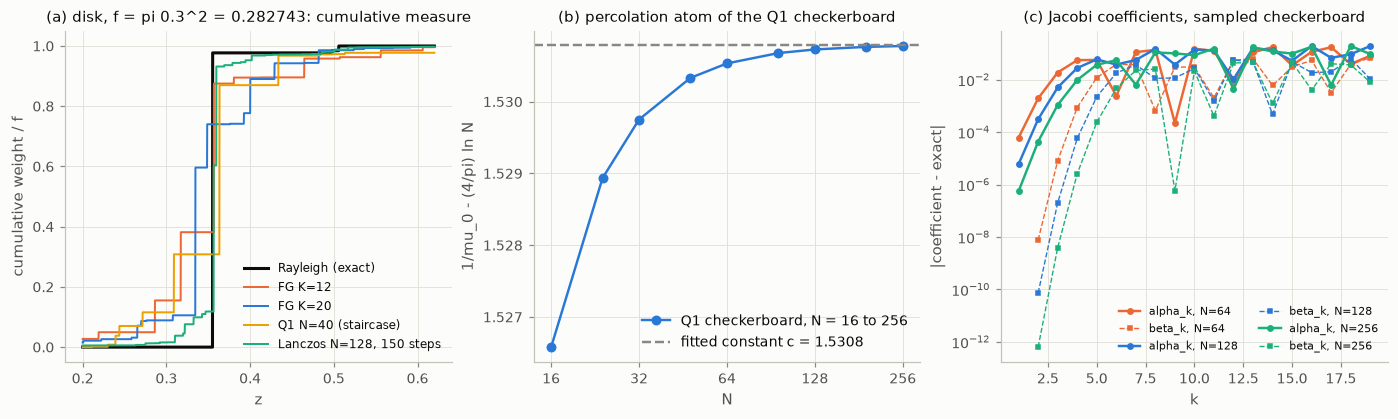

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(12.6, 3.7))
zr_, wr_ = ry.rayleigh_measure(F_ROD, 40)
curves = [("Rayleigh (exact)", zr_, wr_, F_ROD, "-", INK), ("FG K=12", *[r for r in rows if r[0] == "FG K=12"][0][1:3], F_ROD, "-", CAT[1]),
          ("FG K=20", *[r for r in rows if r[0] == "FG K=20"][0][1:3], F_ROD, "-", CAT[0]),
          ("Q1 N=40 (staircase)", *[r for r in rows if r[0] == "Q1 N=40"][0][1:3], F_ROD, "-", CAT[3]),
          ("Lanczos N=128, 150 steps", *[r for r in rows if r[0] == "Lanczos N=128"][0][1:3], rows[[r[0] for r in rows].index("Lanczos N=128")][3], "-", CAT[2])]
grid = np.linspace(0.2, 0.62, 2000)
for lab, z, w, f, ls, col in curves:
    ax[0].plot(grid, sp.cdf(z, w, grid) / np.sum(w), ls, color=col, label=lab, lw=1.3 if col != INK else 2.0)
ax[0].set_xlabel("z"); ax[0].set_ylabel("cumulative weight / f"); ax[0].legend(loc="lower right", fontsize=8); ax[0].set_title("(a) disk, f = pi 0.3^2 = 0.282743: cumulative measure")
ax[1].semilogx(Nall, inv0 - 4 / np.pi * np.log(Nall), "o-", color=CAT[0], label="Q1 checkerboard, N = 16 to 256")
ax[1].axhline(c_best, color=MUTED, ls="--", label=f"fitted constant c = {c_best:.4f}")
ax[1].set_xticks([16, 32, 64, 128, 256]); ax[1].set_xticklabels(["16", "32", "64", "128", "256"]); ax[1].minorticks_off()
ax[1].set_xlabel("N"); ax[1].set_ylabel("1/mu_0 - (4/pi) ln N"); ax[1].legend(); ax[1].set_title("(b) percolation atom of the Q1 checkerboard")
kk = np.arange(1, 20)
for N, col in zip((64, 128, 256), (CAT[1], CAT[0], CAT[2])):
    ax[2].semilogy(kk, np.abs(samp[N][2][1:20] - 0.5), "o-", color=col, ms=3.5, label=f"alpha_k, N={N}")
    ax[2].semilogy(kk[1:], np.maximum(np.abs(samp[N][3][1:19] - 0.25), 1e-17), "s--", color=col, ms=3, lw=0.9, label=f"beta_k, N={N}")
ax[2].set_xlabel("k"); ax[2].set_ylabel("|coefficient - exact|"); ax[2].set_title("(c) Jacobi coefficients, sampled checkerboard"); ax[2].legend(ncol=2, fontsize=7)
plt.show()

*Figure 1 caption.* (a) Cumulative disk measure, normalized by $f$: the exact measure is one jump at 0.355, FG smears it differently at each $K$, the staircase Q1 disk ($N=40$) is smeared and shifted by its pixel fraction, and the sampled scheme concentrates it. (b) The residual $1/\mu_0-(4/\pi)\ln N$ of the Q1 checkerboard's atom at zero against $N$ (log axis): it tends to a constant, the fitted $c=1.5308$ (dashed; fitted, not anchored to a data point), which is what slope $4/\pi$ means. (c) Deviation of the sampled scheme's Jacobi coefficients from the exact ones, on a log scale: the first few converge, the rest do not.

## 4. Corners: a band of spectrum

*From the literature.* For a curvilinear polygon whose corner has interior angle $\alpha$, the essential spectrum of the Neumann-Poincare operator is $[-\tfrac12|1-\alpha/\pi|,\tfrac12|1-\alpha/\pi|]$ (Perfekt and Putinar, Theorem 7; Bonnetier and Zhang by Weyl sequences; the formula was compared with the statements in these papers and not re-derived here). For $\alpha=\pi/2$ this is $\lambda\in[-1/4,1/4]$; with $z=1/2-\lambda$ (the isolated disk's dipole is at $\lambda=0$, $z=1/2$) it is the band $z\in[1/4,3/4]$, whereas a smooth inclusion has discrete spectrum accumulating only at $z=1/2$. The measure $\mu$ is the spectral measure at one vector $u$, so a band in the spectrum of $T$ shows in $\mu$ only if $u$ has weight there. For the pixel-aligned square of side $1/2$ ($f=1/4$) Section 2(d) gives the measure exactly: it has a density on exactly $[1/4,3/4]$, so here $u$ does charge the whole band, and the section below uses that exact measure as the reference for every discretization.

*A natural test, and why it fails.* One can count the atoms carrying 99% of $f$ and the weight outside $[0.23,0.77]$ for FG measures of a pixel-aligned square (side 1/2, $f=1/4$) against the equal-area disk; the expectation recorded before the computation was growth of the first and decay of the second for the square only. But FG compresses a single dominant atom into a cluster for any shape, so both statistics are expected to behave alike for the disk, and the table below includes that control. The distributional statistics are the variance of $\mu/f$ and the quantiles $q_{10},q_{90}$ of the merged measure, with the exact Rayleigh disk at $f=1/4$ as the atomic reference. Q1 represents the pixel-aligned square exactly (no staircase), but Section 2(d) shows that its measure at $f=1/4$ is the Q1 checkerboard measure in disguise, so it is a test of how Q1 discretizes the exact density and not an independent probe of the corner; the staircase disk, whose pixel corners are alternately $90^\circ$ and $270^\circ$, and the Lanczos rows are shown for comparison. A side scan over other pixel squares and a rectangle (Q1, only $90^\circ$ corners) tests whether the $f=1/4$ behavior belongs to the corners or to the cell.

In [10]:
# 4. corners: a square inclusion against the equal-area disk
R_EQ = np.sqrt(0.25 / np.pi)                         # equal-area disk, f = 1/4
zref, wref = ry.rayleigh_measure(0.25, 40)


def band_stats(z, w):
    zm, wm = merge(z, w)
    f = np.sum(wm)
    return dict(n99=sp.n_atoms_for(zm, wm, 0.99), out=np.sum(wm[(zm < 0.23) | (zm > 0.77)]) / f, var=spread(zm, wm),
                q10=quantile(zm, wm, 0.10), q90=quantile(zm, wm, 0.90), natoms=len(zm),
                below=np.sum(wm[zm < 0.25 - 1e-9]) / f, at=np.sum(wm[np.abs(zm - 0.25) <= 1e-9]) / f, above=np.sum(wm[zm > 0.75 + 1e-9]) / f)


def show(label, st, extra=""):
    print(f"{label:20s} {st['natoms']:6d} {st['n99']:4d} {st['out']:9.4f} {st['var']:9.5f} {st['q10']:7.4f} {st['q90']:7.4f} {st['below']:9.4f} {st['at']:8.4f} {st['above']:9.4f}  {extra}")


print(f"{'':20s} {'atoms':>6s} {'n99':>4s} {'w outside':>9s} {'variance':>9s} {'q10':>7s} {'q90':>7s} {'w(z<1/4)':>9s} {'w(z=1/4)':>8s} {'w(z>3/4)':>9s}")
show("Rayleigh disk", band_stats(zref, wref), "exact (f = 1/4)")
qex = lambda p: so.brentq(lambda z: 4 * sq_cdf(z) - p, 0.25, 0.75, xtol=1e-14)         # quantiles of the exact square measure (Section 2(d))
q10_ex, q90_ex = qex(0.10), qex(0.90)
print(f"{'exact square':20s} {'inf':>6s} {'inf':>4s} {0.0:9.4f} {var_sq:9.5f} {q10_ex:7.4f} {q90_ex:7.4f} {0.0:9.4f} {0.0:8.4f} {0.0:9.4f}  exact (Section 2(d)): density on [1/4, 3/4]")
W1sq = {}
stat = {"square": {}, "disk": {}}
t0 = time.perf_counter()
for K in (6, 8, 12, 16, 20, 24):
    zs, ws = sp.fg_measure("square", K, w=0.5)
    zd, wd = sp.fg_measure("disk", K, R=R_EQ)
    stat["square"][K], stat["disk"][K] = band_stats(zs, ws), band_stats(zd, wd)
    W1sq[K] = sp.wasserstein1(zs, ws, zg_sq, wg_sq)
    show(f"FG square K={K}", stat["square"][K], f"W1 to the exact square {W1sq[K]:.4f}")
    show(f"FG disk   K={K}", stat["disk"][K], f"W1 to Rayleigh {sp.wasserstein1(zd, wd, zref, wref):.4f}")
keep4 = dict(disk=(zd, wd), square=(zs, ws))
print(f"FG time {time.perf_counter() - t0:.1f} s")
print("\nstaircase schemes (the pixel-aligned square is exact in Q1; the disk is a staircase of alternating 90 and 270 degree corners):")
q1sq, q1dk = {}, {}
for N in (16, 32, 48):
    zq_, wq_ = sp.q1_measure(cs.square_pixels(N, N // 2, 1.0, 0.0))
    q1sq[N] = band_stats(zq_, wq_)
    keep4["q1sq"] = (zq_, wq_)
    q1dk[N] = band_stats(*sp.q1_measure(cs.disk_pixels(N, R_EQ, 1.0, 0.0)))
    show(f"Q1 square N={N}", q1sq[N])
    show(f"Q1 disk N={N}", q1dk[N], f"f = {cs.disk_pixels(N, R_EQ, 1.0, 0.0).mean():.4f}")
for N in (64, 128, 256):
    for nm, a in (("square", cs.square_pixels(N, N // 2, 1.0, 0.0)), ("disk", cs.disk_pixels(N, R_EQ, 1.0, 0.0))):
        show(f"Lanczos {nm} N={N}", band_stats(*sp.lanczos_measure(a, steps=150)), f"f = {a.mean():.4f}")

# the counting statistics (counts, weight outside the band) and the distributional ones, as found
Kl = sorted(stat["square"])
sq = lambda key: np.array([stat["square"][K][key] for K in Kl])
dk = lambda key: np.array([stat["disk"][K][key] for K in Kl])
print("\nFG, K = " + ", ".join(map(str, Kl)))
print("  atoms carrying 99%: square", sq("n99"), " disk", dk("n99"))
print("  weight outside [0.23, 0.77]: square", np.round(sq("out"), 4), " disk", np.round(dk("out"), 4))
print("  variance of mu/f: square", np.round(sq("var"), 5), " disk", np.round(dk("var"), 5))
check_in("counts do not separate: n99(square) - n99(disk) is never positive over K = 6..24", float(np.max(sq("n99") - dk("n99"))), -100, 0)
check_in("n99 grows with K for the square (smallest step)", float(np.min(np.diff(sq("n99")))), 0, 100)
check_in("n99 grows with K for the disk (smallest step)", float(np.min(np.diff(dk("n99")))), 0, 100)
check_in("weight outside [0.23, 0.77] is not monotone in K for the square (largest step; the expected monotone trend fails)", float(np.max(np.diff(sq("out")))), 1e-4, 1)
check_in("weight outside [0.23, 0.77] is not monotone in K for the disk (largest step)", float(np.max(np.diff(dk("out")))), 1e-4, 1)
check_in("variance: square above disk at every K (smallest ratio)", float(np.min(sq("var") / dk("var"))), 1.0, 1e3)
check_in("variance at K = 24: square over disk", float(sq("var")[-1] / dk("var")[-1]), 3.0, 1e3)
check_in("variance of the FG disk decreases at every step in K (largest step)", float(np.max(np.diff(dk("var")))), -1, 0)
check_in("variance of the FG square decreases at every step in K (largest step)", float(np.max(np.diff(sq("var")))), -1, 0)
check_in("W1 of the FG square to the exact square measure decreases at every step in K = 6..24 (largest step)", float(np.max(np.diff([W1sq[K] for K in Kl]))), -1, 0)
print(f"variance excess over the exact 1/64 at K = 6 and 24: {sq('var')[0] - 1 / 64:.5f}, {sq('var')[-1] - 1 / 64:.5f}; FG disk over its exact value 0.00030 at K = 24: factor {dk('var')[-1] / spread(zref, wref):.1f}")
print(f"quantiles of the exact square: q10 = {q10_ex:.4f}, q90 = {q90_ex:.4f}; of the FG square at K = 24: {sq('q10')[-1]:.4f}, {sq('q90')[-1]:.4f}")
check_in("q10 of the FG square at K = 24 is at most 0.27", float(sq("q10")[-1]), 0.0, 0.27)
check_in("q10 of the FG disk at K = 24 is at least 0.30", float(dk("q10")[-1]), 0.30, 1.0)

# the sharper test: Q1 represents the pixel-aligned square exactly
print("\nQ1, pixel-aligned square: lowest and highest atoms carrying weight, weight below 1/4, at 1/4, above 3/4")
for N in (16, 32, 48):
    z, w = merge(*sp.q1_measure(cs.square_pixels(N, N // 2, 1.0, 0.0)))
    k = w > 1e-10
    above = np.sum(w[z > 0.75]) / np.sum(w)
    print(f"  N = {N}: z from {z[k].min():.6f} to {z[k].max():.4f}; weight below 1/4: {q1sq[N]['below']:.1e}; at 1/4: {q1sq[N]['at']:.4f}; above 3/4: {above:.1e}")
    check(f"Q1 square N = {N}: lowest atom carrying weight sits at z = 1/4", z[k].min(), 1e-9, 0.25)
    check_in(f"Q1 square N = {N}: no weight above 3/4", above, -1e-12, 1e-12)
    check(f"Q1 square N = {N}: the weight fraction exactly at 1/4 equals 2 mu_0 of the Q1 checkerboard (the relabeled percolation atom of Section 2(d))", q1sq[N]["at"], 1e-9, 2 * q1c[N][0])
check_in("Q1 square: the weight at 1/4 decreases with N = 16, 32, 48 (largest step)", max(q1sq[32]["at"] - q1sq[16]["at"], q1sq[48]["at"] - q1sq[32]["at"]), -1, 0)
for N in (16, 32, 48):
    check_in(f"Q1 staircase disk N = {N}: weight below 1/4 (the square has none)", q1dk[N]["below"], 0.01, 1.0)
w1q = [sp.wasserstein1(*q1sq_meas[N], zg_sq, wg_sq) for N in (16, 32, 48)]
print(f"W1 of the Q1 square measure to the exact square measure: {w1q[0]:.5f}, {w1q[1]:.5f}, {w1q[2]:.5f} at N = 16, 32, 48 (for mu/f: x 4)")
check_in("W1 of the Q1 square measure to the exact square measure decreases over N = 16, 32, 48 (largest step)", max(w1q[1] - w1q[0], w1q[2] - w1q[1]), -1.0, 0.0)
print("weight fraction of the Q1 square at 1/4 for larger N, from the identity w/f = 2 mu_0(N) (verified above at N = 16, 32, 48 by the measures, and at N = 64, 128 for the solver): "
      + ", ".join(f"N = {N}: {2 * mu_all[N]:.4f}" for N in (64, 96, 128, 192, 256)) + f";  d(f/w)/d ln N = half the slope of 1/mu_0, i.e. {loc[-1] / 2:.4f} against 2/pi = {2 / np.pi:.4f}")

# the control the f = 1/4 cell needs: Q1 squares of other sides and one rectangle (all with 90-degree corners only)
def q1_low_stats(a):
    z_, w_ = sp.q1_measure(a)
    f_ = np.sum(w_)
    k_ = w_ > 1e-10 * f_
    return f_, z_[k_].min(), np.sum(w_[z_ < 0.25 - 1e-9]) / f_, np.sum(w_[np.abs(z_ - 0.25) <= 1e-9]) / f_


print("\nside scan, Q1, pixel-aligned centered squares (and one rectangle), field along x: f, lowest atom with weight, weight fraction below 1/4, at 1/4")
print(f"{'cell':22s} {'f':>8s} {'lowest atom':>12s} {'w(z<1/4)/f':>11s} {'w(z=1/4)/f':>11s}")
scan = {}
for N, sides in ((16, range(2, 15, 2)), (32, (8, 16, 24))):
    for side in sides:
        scan[(N, side)] = q1_low_stats(cs.square_pixels(N, side, 1.0, 0.0))
        print(f"{'square, N=%d, side %d' % (N, side):22s} {scan[(N, side)][0]:8.4f} {scan[(N, side)][1]:12.6f} {scan[(N, side)][2]:11.4f} {scan[(N, side)][3]:11.4f}")
rect = np.zeros((16, 16))
rect[4:12, 6:10] = 1.0                                # 8 x 4 pixels: x from 4 to 12, y from 6 to 10
scan["rect"] = q1_low_stats(rect)
print(f"{'rectangle 8x4, N=16':22s} {scan['rect'][0]:8.4f} {scan['rect'][1]:12.6f} {scan['rect'][2]:11.4f} {scan['rect'][3]:11.4f}")
lowest = [scan[(16, sd)][1] for sd in range(2, 15, 2)]
check_in("side scan N = 16: the lowest atom decreases with the side (largest step)", float(np.max(np.diff(lowest))), -1.0, 0.0)
check_in("side scan N = 16: squares of side 2, 4, 6 (f < 1/4) have no weight below 1/4 and no weight at 1/4 (largest of the three)", max(scan[(16, sd)][2] + scan[(16, sd)][3] for sd in (2, 4, 6)), -1e-9, 1e-9)
check_in("side scan N = 16: the lowest atom of the squares with f < 1/4 lies above 1/4 (smallest margin)", min(scan[(16, sd)][1] for sd in (2, 4, 6)) - 0.25, 1e-3, 1.0)
for sd in (10, 12, 14):
    check_in(f"side scan N = 16: the square of side {sd} (f > 1/4) puts more than half of its weight below 1/4", scan[(16, sd)][2], 0.5, 1.0)
check_in("side scan N = 16: only the f = 1/4 square has weight exactly at 1/4 (largest weight there among the other six)", max(scan[(16, sd)][3] for sd in (2, 4, 6, 10, 12, 14)), -1e-9, 1e-9)
check_in("N = 32 repeats it: side 8 (f = 1/16) has no weight at or below 1/4", scan[(32, 8)][2] + scan[(32, 8)][3], -1e-9, 1e-9)
check_in("N = 32 repeats it: side 24 (f = 9/16) puts more than half of its weight below 1/4", scan[(32, 24)][2], 0.5, 1.0)
check_in("the 8 x 4 rectangle puts more than half of its weight below 1/4", scan["rect"][2], 0.5, 1.0)

                      atoms  n99 w outside  variance     q10     q90  w(z<1/4) w(z=1/4)  w(z>3/4)
Rayleigh disk             8    2    0.0000   0.00030  0.3727  0.3727    0.0000   0.0000    0.0000  exact (f = 1/4)
exact square            inf  inf    0.0000   0.01563  0.2531  0.5743    0.0000   0.0000    0.0000  exact (Section 2(d)): density on [1/4, 3/4]
FG square K=6           116    9    0.1037   0.02291  0.2055  0.6684    0.1027   0.0000    0.0010  W1 to the exact square 0.0154
FG disk   K=6           110   10    0.0958   0.01088  0.3233  0.3968    0.0938   0.0000    0.0145  W1 to Rayleigh 0.0167
FG square K=8           169   11    0.0821   0.02131  0.2379  0.6514    0.1441   0.0000    0.0011  W1 to the exact square 0.0126
FG disk   K=8           162   11    0.0616   0.00894  0.2642  0.3788    0.0598   0.0000    0.0024  W1 to Rayleigh 0.0106


FG square K=12          270   13    0.0872   0.01956  0.2511  0.6284    0.0859   0.0000    0.0016  W1 to the exact square 0.0093
FG disk   K=12          265   14    0.1253   0.00669  0.2271  0.3885    0.1241   0.0000    0.0012  W1 to Rayleigh 0.0120


FG square K=16          384   15    0.0722   0.01863  0.2594  0.6134    0.0938   0.0000    0.0017  W1 to the exact square 0.0076
FG disk   K=16          372   18    0.0286   0.00515  0.3203  0.4282    0.0275   0.0000    0.0014  W1 to Rayleigh 0.0126


FG square K=20          496   19    0.0583   0.01805  0.2523  0.6028    0.0775   0.0000    0.0019  W1 to the exact square 0.0068
FG disk   K=20          484   20    0.0323   0.00412  0.3404  0.3988    0.0313   0.0000    0.0015  W1 to Rayleigh 0.0084


FG square K=24          609   22    0.0572   0.01766  0.2591  0.5948    0.0865   0.0000    0.0019  W1 to the exact square 0.0060
FG disk   K=24          600   23    0.0302   0.00353  0.3496  0.4139    0.0297   0.0000    0.0017  W1 to Rayleigh 0.0074
FG time 11.5 s

staircase schemes (the pixel-aligned square is exact in Q1; the disk is a staircase of alternating 90 and 270 degree corners):
Q1 square N=16           24    6    0.0000   0.01562  0.2500  0.6244    0.0000   0.3955    0.0000  
Q1 disk N=16             25    6    0.0200   0.00922  0.2993  0.5440    0.0200   0.0000    0.0040  f = 0.2344
Q1 square N=32           48    7   -0.0000   0.01562  0.2500  0.5453   -0.0000   0.3366    0.0000  
Q1 disk N=32             55    7    0.0000   0.00542  0.2844  0.4296    0.0424   0.0000    0.0039  f = 0.2500


Q1 square N=48           64    9    0.0000   0.01562  0.2500  0.5577    0.0000   0.3096    0.0000  
Q1 disk N=48             85   15    0.0297   0.00520  0.2777  0.4138    0.0458   0.0000    0.0045  f = 0.2500
Lanczos square N=64     149   48    0.0229   0.01563  0.2546  0.5731    0.0652   0.0000    0.0023  f = 0.2500
Lanczos disk N=64       150   24    0.0061   0.00253  0.3595  0.4035    0.0148   0.0000    0.0024  f = 0.2490
Lanczos square N=128    150   74    0.0084   0.01562  0.2572  0.5742    0.0535   0.0000    0.0009  f = 0.2500


Lanczos disk N=128      150   29    0.0063   0.00163  0.3421  0.3775    0.0060   0.0000    0.0012  f = 0.2505


Lanczos square N=256    150   72    0.0001   0.01562  0.2569  0.5746    0.0530   0.0000    0.0005  f = 0.2500


Lanczos disk N=256      150   23    0.0041   0.00093  0.3681  0.3802    0.0038   0.0000    0.0007  f = 0.2499

FG, K = 6, 8, 12, 16, 20, 24
  atoms carrying 99%: square [ 9 11 13 15 19 22]  disk [10 11 14 18 20 23]
  weight outside [0.23, 0.77]: square [0.1037 0.0821 0.0872 0.0722 0.0583 0.0572]  disk [0.0958 0.0616 0.1253 0.0286 0.0323 0.0302]
  variance of mu/f: square [0.02291 0.02131 0.01956 0.01863 0.01805 0.01766]  disk [0.01088 0.00894 0.00669 0.00515 0.00412 0.00353]
PASS  counts do not separate: n99(square) - n99(disk) is never positive over K = 6..24: got 0, required in [-100, 0]
PASS  n99 grows with K for the square (smallest step): got 2, required in [0, 100]
PASS  n99 grows with K for the disk (smallest step): got 1, required in [0, 100]
PASS  weight outside [0.23, 0.77] is not monotone in K for the square (largest step; the expected monotone trend fails): got 0.00514533, required in [0.0001, 1]
PASS  weight outside [0.23, 0.77] is not monotone in K for the disk (largest s

  N = 48: z from 0.250000 to 0.6617; weight below 1/4: 1.7e-15; at 1/4: 0.3096; above 3/4: 2.1e-29
PASS  Q1 square N = 48: lowest atom carrying weight sits at z = 1/4: got 0.25, target 0.25, |diff| 5.55e-16 <= 1e-09
PASS  Q1 square N = 48: no weight above 3/4: got 2.13357e-29, required in [-1e-12, 1e-12]
PASS  Q1 square N = 48: the weight fraction exactly at 1/4 equals 2 mu_0 of the Q1 checkerboard (the relabeled percolation atom of Section 2(d)): got 0.309631, target 0.309631, |diff| 8.88e-16 <= 1e-09
PASS  Q1 square: the weight at 1/4 decreases with N = 16, 32, 48 (largest step): got -0.0269296, required in [-1, 0]
PASS  Q1 staircase disk N = 16: weight below 1/4 (the square has none): got 0.0200341, required in [0.01, 1]
PASS  Q1 staircase disk N = 32: weight below 1/4 (the square has none): got 0.042426, required in [0.01, 1]
PASS  Q1 staircase disk N = 48: weight below 1/4 (the square has none): got 0.0457653, required in [0.01, 1]
W1 of the Q1 square measure to the exact square m

square, N=32, side 24    0.5625     0.188396      0.7934      0.0000
rectangle 8x4, N=16      0.1250     0.215354      0.7507      0.0000
PASS  side scan N = 16: the lowest atom decreases with the side (largest step): got -0.0122972, required in [-1, 0]
PASS  side scan N = 16: squares of side 2, 4, 6 (f < 1/4) have no weight below 1/4 and no weight at 1/4 (largest of the three): got 1.66533e-15, required in [-1e-09, 1e-09]
PASS  side scan N = 16: the lowest atom of the squares with f < 1/4 lies above 1/4 (smallest margin): got 0.0133566, required in [0.001, 1]
PASS  side scan N = 16: the square of side 10 (f > 1/4) puts more than half of its weight below 1/4: got 0.559116, required in [0.5, 1]
PASS  side scan N = 16: the square of side 12 (f > 1/4) puts more than half of its weight below 1/4: got 0.789216, required in [0.5, 1]
PASS  side scan N = 16: the square of side 14 (f > 1/4) puts more than half of its weight below 1/4: got 0.99684, required in [0.5, 1]
PASS  side scan N = 16: on

The table of Fourier-Galerkin statistics tests this expectation directly, and the outcome is negative. The number of atoms carrying 99% of $f$ grows with $K$ for both shapes (square 9, 11, 13, 15, 19, 22; disk 10, 11, 14, 18, 20, 23), and for the square it never exceeds the disk's, so the growth is the compression and not the band. The weight outside $[0.23,0.77]$ is not monotone in $K$ for either shape (square 0.1037, 0.0821, 0.0872, 0.0722, 0.0583, 0.0572; disk 0.0958, 0.0616, 0.1253, 0.0286, 0.0323, 0.0302), so the expected monotone trend for the square fails, and it would not distinguish the shapes if it did not. Since the exact measure of the square lies entirely in $[1/4,3/4]$, the exact weight outside $[0.23,0.77]$ is zero, and the FG values (0.0572 at $K=24$) measure Ritz leakage, not the band. **At $K\le24$ these FG counting statistics cannot test the Perfekt-Putinar band**, although the band is charged.

*The variance and the quantiles, with exact references.* The variance of $\mu/f$ does separate the shapes, by a factor of at least 2.1 at every $K$ and 5.0 at $K=24$ (0.01766 for the square against 0.00353 for the disk). The references are exact: 1/64 = 0.015625 for the square and 0.00030 for the Rayleigh disk. The FG square variance decreases at every step (0.02291, 0.02131, 0.01956, 0.01863, 0.01805, 0.01766 for $K=6$ to 24; the excess over 1/64 falls from 0.00728 to 0.00204) and its measure approaches the exact one in $W_1$ at every step (0.0154, 0.0126, 0.0093, 0.0076, 0.0068, 0.0060); the FG disk variance also decreases but is still 11.8 times its exact value at $K=24$, so "toward the exact value" is an extrapolation that these six values do not establish. The quantiles: the exact square has $q_{10}=0.2531$, $q_{90}=0.5743$ (the FG square at $K=24$: 0.2591, 0.5948), the exact disk 0.3727 for both (the FG disk: 0.3496, 0.4139). The separation is therefore a statement about the spread of the measure, which the band explains (it is the exact measure's own spread), and the sampled scheme reproduces it far better than FG: its variance is 0.01563, 0.01562, 0.01562 at $N=64,128,256$ and its $q_{90}$ is 0.5731, 0.5742, 0.5746 against 0.5743.

*Where the exact measure leaves the FG and Q1 results.* FG puts 0.1027, 0.1441, 0.0859, 0.0938, 0.0775, 0.0865 of the square's weight below $z=1/4$ at $K=6,8,12,16,20,24$ (and 0.0010 to 0.0019 above $3/4$), where the exact measure has none; this is Rayleigh-Ritz leakage, and over this range it does not shrink systematically (it is not monotone in $K$). Q1 represents the pixel-aligned square exactly and has no weight below $1/4$ at $N=16,32,48$ (to rounding), none above $3/4$ (its highest atoms with weight are at 0.6244, 0.6500, 0.6617: the upper part of the band is represented by few, slowly moving atoms), and 0.3955, 0.3366, 0.3096 of $f$ exactly at $z=1/4$. By Section 2(d) that atom is the checkerboard's percolation atom relabeled ($w/f=2\mu_0$, asserted at $N=16,32,48$), so by Section 3 it vanishes like $1/((2/\pi)\ln N+c/2)$: for $N=64$ to 256 the same identity gives 0.2930, 0.2724, 0.2595, 0.2432, 0.2328 and $d(f/w)/d\ln N=0.6366$ against $2/\pi=0.6366$. It is a Q1 artifact standing in for the $(z-1/4)^{-1/2}$ edge singularity of the exact density, so it is not independent evidence about the corner, and the weight there, which at moderate $N$ does not look convergent, converges to zero. The $W_1$ distance of the Q1 square measure to the exact one is 0.00662, 0.00559, 0.00513 at $N=16,32,48$ (for $\mu/f$ multiply by 4), decreasing. The staircase disk has no atom at $1/4$ and puts 0.0200, 0.0424, 0.0458 of its weight below $1/4$ (discrete eigenvalues outside the essential band are allowed). The pixel square's variance is 0.01562 in Q1 at every $N$, which is the exact 1/64 to four digits (why the Q1 value is so close is not derived here).

*The side scan.* The Q1 measure of other pixel-aligned squares at $N=16$ (sides 2, 4, ..., 14 pixels; $f=0.0156$ to 0.7656) has its lowest atom at 0.2999, 0.2757, 0.2634, 0.2500, 0.2285, 0.1859, 0.1094: it moves down smoothly with $f$ and crosses $1/4$ at the side 8. Squares with $f<1/4$ have no weight below or at $1/4$ (lowest atoms 0.2999, 0.2757, 0.2634, above 1/4), and squares with $f>1/4$ have 0.559, 0.789, 0.997 of their weight below $1/4$. At $N=32$ the sides 8, 16, 24 repeat it (0.2695 and no weight at or below $1/4$; 0.3366 exactly at $1/4$; 0.7934 below). An $8\times4$ rectangle ($f=1/8$, only $90^\circ$ corners, field along $x$) has lowest atom 0.2154 and 0.7507 of its weight below $1/4$. So the Q1 pattern of the $f=1/4$ square (nothing below $1/4$, a large atom at $1/4$) belongs to that cell, where the identity of Section 2(d) applies; it is not a property of the 90-degree corners as such. The weight below $1/4$ of the larger squares and of the rectangle is made of discrete eigenvalues outside the essential band, which the Perfekt-Putinar theorem allows.

*What is established.* For this cell the measure is absolutely continuous with support exactly $[1/4,3/4]$ (both edges), consistent with the Perfekt-Putinar band $z\in[1/4,3/4]$ of a 90-degree corner. That is one cell, and the exact solution is a published result certified here only to the bracket widths of Section 2(d); it does not test the polygon theorem for other shapes, and for other squares the weight distribution (the discrete eigenvalues outside the band, the periodic-array interaction, which puts the dominant atom of the disk array at 0.3552 rather than at the isolated disk's 1/2) is not given by an exact solution here.


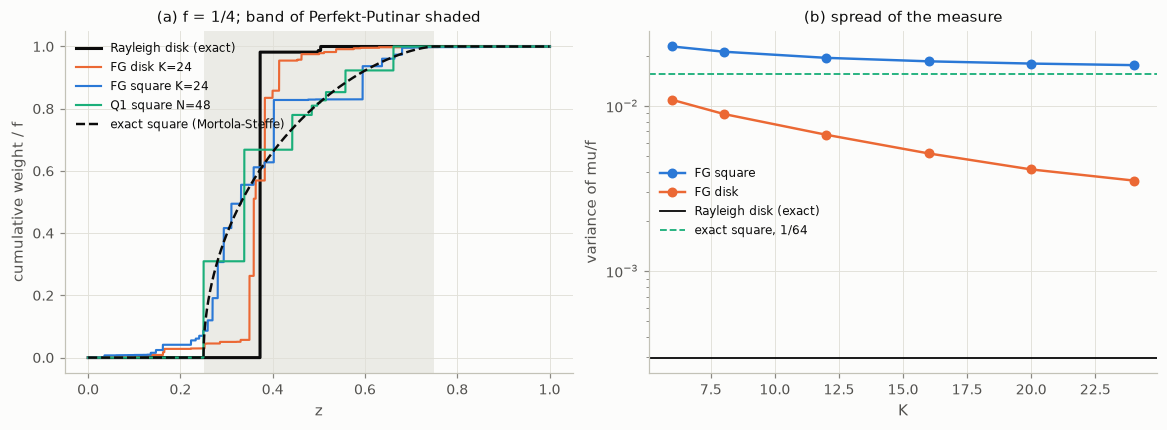

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
grid = np.linspace(0.0, 1.0, 4001)
ax[0].axvspan(0.25, 0.75, color=GRID, alpha=0.6, lw=0)
for lab, (z, w), col, ls in [("Rayleigh disk (exact)", (zref, wref), INK, "-"), ("FG disk K=24", keep4["disk"], CAT[1], "-"),
                              ("FG square K=24", keep4["square"], CAT[0], "-"), ("Q1 square N=48", keep4["q1sq"], CAT[2], "-")]:
    ax[0].plot(grid, sp.cdf(z, w, grid) / np.sum(w), ls, color=col, label=lab, lw=2.0 if col == INK else 1.4)
ax[0].plot(grid, 4 * sq_cdf(grid), "--", color=INK, lw=1.6, label="exact square (Mortola-Steffe)")
ax[0].set_xlabel("z"); ax[0].set_ylabel("cumulative weight / f"); ax[0].legend(loc="upper left", fontsize=8); ax[0].set_title("(a) f = 1/4; band of Perfekt-Putinar shaded")
Kl = sorted(stat["square"])
ax[1].semilogy(Kl, [stat["square"][K]["var"] for K in Kl], "o-", color=CAT[0], label="FG square")
ax[1].semilogy(Kl, [stat["disk"][K]["var"] for K in Kl], "o-", color=CAT[1], label="FG disk")
ax[1].axhline(spread(zref, wref), color=INK, lw=1.2, label="Rayleigh disk (exact)")
ax[1].axhline(1 / 64, color=CAT[2], ls="--", lw=1.2, label="exact square, 1/64")
ax[1].set_xlabel("K"); ax[1].set_ylabel("variance of mu/f"); ax[1].legend(fontsize=8); ax[1].set_title("(b) spread of the measure")
plt.show()

*Figure 2 caption.* (a) Cumulative measures at $f=1/4$ with the band shaded: the exact disk is one jump near 0.37, the exact square (dashed black, Mortola-Steffe) rises through the whole band $[1/4,3/4]$, FG smears both shapes, and the Q1 square has no weight below 1/4 and a jump of about a third at 1/4 (the relabeled percolation atom). (b) Variance of $\mu/f$ against $K$ (log scale): the FG square decreases toward the exact square value $1/64$ (dashed), and the FG disk decreases but is still 12 times the exact disk's value (black) at $K=24$.

*Four-tile exponents at negative contrast.* Near a cross point where four quadrants carry $\sigma=1,\kappa,1,\kappa$, separable solutions $r^\lambda\Phi(\theta)$ with $\Phi_j=A_j\cos\lambda\theta+B_j\sin\lambda\theta$ in each quadrant have to match $\Phi$ and $\sigma\Phi'$ across the four rays, an $8\times8$ system $D(\lambda)$ with row-normalized entries (the last ray joins $\theta=2\pi$ to $\theta=0$). Its roots are the exponents; the mirror classes reduce it to $\tan^2(\lambda\pi/4)=\kappa^{\pm1}$. For $\kappa>0$ the smallest root is $\lambda_1=(4/\pi)\arctan\kappa^{-1/2}$ and the second is $2-\lambda_1$ (this is the Q1 convergence exponent of notebook 01, used here only as a validation of the matrix). For $\kappa<0$ the roots are purely imaginary, $\lambda=\pm i y$ with $y=(4/\pi)\,\mathrm{artanh}\sqrt{\min(|\kappa|,1/|\kappa|)}$, symmetric under $\kappa\to1/\kappa$ and with no finite root at $\kappa=-1$ ($\mathrm{artanh}\,1=\infty$). The other pair of the mirror classes is $\lambda=2\pm iy$ with the same $y$, and it is tested against $D$ below. (This notebook re-implements $D$ instead of importing notebook 01's; the validation on positive contrast below is its test.) The singular fields $r^{iy}=\cos(y\ln r)+i\sin(y\ln r)$ oscillate in $\ln r$, consistent with a purely imaginary $\sqrt{\varepsilon_1\varepsilon_2}$ for the checkerboard; their energy density $|\nabla r^{iy}|^2\sim y^2/r^2$ is not integrable at the cross point, so there is no finite-energy singular solution of this form (that this makes the problem non-Fredholm in $H^1$ for every $\kappa<0$ except $-1$ is from memory of the transmission-problem literature and has not been checked).

In [12]:
# 4(b). the four-tile exponents at negative contrast
def D_corner(lam, kappa):
    """8x8 matching matrix of r^lam Phi(theta) at a cross point with values 1, kappa, 1, kappa in the four quadrants.
    Phi_j = A_j cos(lam theta) + B_j sin(lam theta) on [j pi/2, (j+1) pi/2]; unknowns (A_0, B_0, ..., A_3, B_3); rows: continuity of Phi
    and of sigma Phi' at the four rays (the last ray joins theta = 2 pi to theta = 0). Rows are normalized to unit length."""
    sig = [1.0, kappa, 1.0, kappa]
    D = np.zeros((8, 8), dtype=complex)
    for j in range(4):
        n, th = (j + 1) % 4, (j + 1) * np.pi / 2
        th_n = th if j < 3 else 0.0
        c, s_ = np.cos(lam * th), np.sin(lam * th)
        cn, sn = np.cos(lam * th_n), np.sin(lam * th_n)
        D[2 * j, 2 * j:2 * j + 2] = [c, s_]
        D[2 * j, 2 * n:2 * n + 2] -= [cn, sn]
        D[2 * j + 1, 2 * j:2 * j + 2] = sig[j] * lam * np.array([-s_, c])
        D[2 * j + 1, 2 * n:2 * n + 2] -= sig[n] * lam * np.array([-sn, cn])
    return D / np.linalg.norm(D, axis=1, keepdims=True)


def smin(lam, kappa):
    return np.linalg.svd(D_corner(lam, kappa), compute_uv=False)[-1]


# validation on positive contrast: the closed-form roots lam_1 = (4/pi) arctan(kappa^-1/2) and 2 - lam_1
for kap in (4.0, 100.0):
    l1 = 4 / np.pi * np.arctan(kap ** -0.5)
    print(f"kappa = {kap:g}: sigma_min(D) at lambda_1 = {l1:.6f}: {smin(l1, kap):.1e};  at 2 - lambda_1: {smin(2 - l1, kap):.1e};  at 1.1 lambda_1: {smin(1.1 * l1, kap):.1e}")
    check_in(f"validation of D: sigma_min at lambda_1, kappa = {kap:g}", smin(l1, kap), 0.0, 1e-12)
    check_in(f"validation of D: sigma_min at 2 - lambda_1, kappa = {kap:g}", smin(2 - l1, kap), 0.0, 1e-12)

print(f"\n{'kappa':>6s} {'predicted lambda':>22s} {'sigma_min(D) there':>19s} {'at 1.1 x lambda':>16s} {'located on i R':>16s} {'error':>9s}  {'Re lambda of the other pair':>28s}")
for kap in (-2.0, -0.5, -10.0):
    y = 4 / np.pi * np.arctanh(min(abs(kap), 1 / abs(kap)) ** 0.5)
    lam = 1j * y
    s0, s1 = smin(lam, kap), smin(1.1 * lam, kap)
    r = so.minimize_scalar(lambda t: smin(1j * t, kap), bounds=(0.8 * y, 1.2 * y), method="bounded", options=dict(xatol=1e-12))
    # the other branch: tan(lam pi/4)^2 = kappa or 1/kappa, the one with |tan| > 1, has Re lam = 2
    other = 4 / np.pi * np.arctan(1j * max(abs(kap), 1 / abs(kap)) ** 0.5)
    print(f"{kap:6.1f} {'+- %.6f i' % y:>22s} {s0:19.1e} {s1:16.1e} {r.x:16.8f} {abs(r.x - y):9.1e}  {other.real:28.4f}")
    check_in(f"imaginary exponent at kappa = {kap:g}: sigma_min(D(+i y)) at the closed form", s0, 0.0, 1e-10)
    check_in(f"imaginary exponent at kappa = {kap:g}: sigma_min(D(-i y))", smin(-lam, kap), 0.0, 1e-10)
    lam2 = 4 / np.pi * np.arctan(1j * max(abs(kap), 1 / abs(kap)) ** 0.5)
    print(f"      other pair from the closed form: lambda = {lam2.real:.4f} {lam2.imag:+.6f} i; sigma_min(D) there: {smin(lam2, kap):.1e}")
    check_in(f"the other pair of roots at kappa = {kap:g}, Re lambda = 2 and Im lambda = y: sigma_min(D) at the closed form (tested against D, not only read off the formula)", smin(lam2, kap), 0.0, 1e-10)
    check_in(f"control at kappa = {kap:g}: sigma_min(D) at 1.1 x the root is orders of magnitude above its value at the root", s1, 1e-9, 1.0)
    check(f"minimizer of sigma_min along the imaginary axis at kappa = {kap:g}", r.x, 1e-6, y)
print("kappa = -1 (y -> infinity): the formula has no finite root, since artanh(1) is infinite.")

kappa = 4: sigma_min(D) at lambda_1 = 0.590334: 1.3e-16;  at 2 - lambda_1: 2.1e-16;  at 1.1 lambda_1: 5.3e-02
PASS  validation of D: sigma_min at lambda_1, kappa = 4: got 1.27233e-16, required in [0, 1e-12]
PASS  validation of D: sigma_min at 2 - lambda_1, kappa = 4: got 2.05087e-16, required in [0, 1e-12]
kappa = 100: sigma_min(D) at lambda_1 = 0.126902: 1.5e-17;  at 2 - lambda_1: 5.2e-17;  at 1.1 lambda_1: 2.9e-03
PASS  validation of D: sigma_min at lambda_1, kappa = 100: got 1.4565e-17, required in [0, 1e-12]
PASS  validation of D: sigma_min at 2 - lambda_1, kappa = 100: got 5.19279e-17, required in [0, 1e-12]

 kappa       predicted lambda  sigma_min(D) there  at 1.1 x lambda   located on i R     error   Re lambda of the other pair
  -2.0          +- 1.122200 i             1.2e-17          4.0e-07       1.12219970   1.7e-10                        2.0000
PASS  imaginary exponent at kappa = -2: sigma_min(D(+i y)) at the closed form: got 1.22927e-17, required in [0, 1e-10]
PASS  imagi

The matrix $D$ is validated on positive contrast (smallest singular value at $\lambda_1$ and at $2-\lambda_1$ of order $10^{-16}$ for $\kappa=4,100$, against 5.3e-02 and 2.9e-03 at $1.1\lambda_1$). At negative contrast the smallest singular value at the predicted $\pm iy$ is at most 1.8e-16, the other pair $2\pm iy$ has $\sigma_{\min}\le3.5\times10^{-16}$ at all three contrasts, and a one-dimensional minimization of $\sigma_{\min}$ along the imaginary axis finds the root to 6.9e-9 at worst; the control (a $10\%$ displacement of the root) shows a singular value orders of magnitude larger.

## 5. Plasmonic composites

Drude inclusions in vacuum give $s=\omega(\omega+i\gamma)/\omega_p^2$, and a measure with atoms $(z_k,w_k)$ gives $\varepsilon^*(\omega)=1-\sum_kw_k\omega_p^2/(\omega^2+i\gamma\omega-\omega_k^2)$: each atom is a Lorentz oscillator at $\omega_k=\omega_p\sqrt{z_k}$ of strength $w_k\omega_p^2$. Since $\int_0^\infty\omega^2\,d\omega/[(\omega^2-\omega_k^2)^2+\gamma^2\omega^2]=\pi/(2\gamma)$ whatever $\omega_k$ is, every atom contributes $(\pi/2)w_k\omega_p^2$ to $\int_0^\infty\omega\,\mathrm{Im}\,\varepsilon^*\,d\omega$, so for every microstructure and every $\gamma$

$$\int_0^\infty\omega\,\mathrm{Im}\,\varepsilon^*(\omega)\,d\omega=\frac\pi2f\omega_p^2,$$

from $m_0=f$ alone. The peak of one Lorentzian is not at $\omega_k$: maximizing $\omega/[(\omega^2-\omega_k^2)^2+\gamma^2\omega^2]$ gives $\omega_k-\gamma^2/(8\omega_k)$ to leading order. The checkerboard, with a density on all of $(0,1)$, absorbs over the whole band $\omega<\omega_p$ even as $\gamma\to0$.

*Computations.* Five curves with $\omega_p=1$: the Rayleigh disk array ($f=\pi\,0.3^2$), the exact square inclusion of Section 2(d) ($f=1/4$, $1-F=\sqrt{(s-3/4)/(s-1/4)}$, whose sum rule is a nontrivial integral identity), the FG square at $K=20$ (kept as a discretization artifact; only its sum rule is asserted), the checkerboard (the exact $\varepsilon^*=\sqrt{\varepsilon_1}$, i.e. $F=1-\sqrt{1-1/s}$, for which the sum rule is a nontrivial integral identity) and Maxwell Garnett; $\gamma\in\{0.02,0.1\}$. The integral is taken from $\omega=0$ in the variable $u=\sqrt\omega$ (composite Gauss-Legendre on $[0,\sqrt3]$, which removes the $\omega^{-1/2}$ behavior of the checkerboard at small $\omega$) plus the tail on $[3,\infty)$ by adaptive quadrature. The absorption of the lossless checkerboard and of the exact square is computed from the density's Stieltjes transform (the square's by $F(s)=\pi^{-1}\int_0^{\pi/2}\cos^2\theta\,d\theta/(s-\tfrac14-\tfrac12\sin^2\theta)$, with $z=\tfrac14+\tfrac12\sin^2\theta$; its lossless limit is $\sqrt{(3/4-\omega^2)/(\omega^2-1/4)}$ for $1/2<\omega<\sqrt3/2$ and zero outside), $F(s)=(2/\pi)\int_0^{\pi/2}\cos^2\theta\,d\theta/(s-\sin^2\theta)$ at $\gamma=10^{-6}$, so $s$ is within $10^{-6}$ of the support (breakpoints are placed geometrically around the pole), and compared with the closed form $1-\sqrt{1-1/s}$ at the same complex $s$ and with the lossless limit $\sqrt{|\varepsilon_1|}=\sqrt{1/\omega^2-1}$. Comparing only the last two would be vacuous; the density route is the test.

In [13]:
# 5. plasmonic composites: Drude inclusions in vacuum, eps1 = 1 - 1/(w (w + i g)) with omega_p = 1
zD, wD = ry.rayleigh_measure(F_ROD, 40)
zSq, wSq = sp.fg_measure("square", 20, w=0.5)         # f = 1/4
meas = {"disk lattice (Rayleigh)": (F_ROD, lambda om, g: 1 - sp.stieltjes(zD, wD, sp.drude_s(om, 1.0, g))),
        "square (exact)": (0.25, lambda om, g: np.sqrt((sp.drude_s(om, 1.0, g) - 0.75) / (sp.drude_s(om, 1.0, g) - 0.25))),
        "square, FG K=20 (artifact)": (0.25, lambda om, g: 1 - sp.stieltjes(zSq, wSq, sp.drude_s(om, 1.0, g))),
        "checkerboard (exact)": (0.5, lambda om, g: np.sqrt(1 - 1 / (om * (om + 1j * g)))),
        "Maxwell Garnett": (F_ROD, lambda om, g: 1 - F_ROD / (sp.drude_s(om, 1.0, g) - (1 - F_ROD) / 2))}
# note: for the checkerboard 1 - F(s) = sqrt(1 - 1/s) = sqrt(eps1): a closed form whose integral is a nontrivial test of m0 = 1/2;
# likewise for the exact square, 1 - F(s) = sqrt((s - 3/4)/(s - 1/4)), whose integral must equal (pi/2)(1/4)

xg, wg = np.polynomial.legendre.leggauss(8)
edges = np.linspace(0.0, np.sqrt(3.0), 1801)         # omega = u^2: removes the omega^(-1/2) behavior of the checkerboard at 0
uu = (0.5 * (edges[1:, None] + edges[:-1, None]) + 0.5 * (edges[1:, None] - edges[:-1, None]) * xg[None, :]).ravel()
uw = (0.5 * (edges[1:, None] - edges[:-1, None]) * wg[None, :]).ravel()


def absorption_integral(eps_fun, gam):
    """int_0^inf omega Im eps*(omega) d omega: Gauss-Legendre in u = sqrt(omega) on [0, 3], quad for the exact tail on [3, inf)."""
    head = np.sum(uw * 2 * uu ** 3 * eps_fun(uu ** 2, gam).imag)
    tail = si.quad(lambda om: om * eps_fun(np.array([om]), gam).imag[0], 3.0, np.inf, epsabs=1e-13, epsrel=1e-12, limit=200)[0]
    return head + tail, head, tail


print(f"{'measure':28s} {'gamma':>6s} {'integral':>12s} {'(pi/2) f':>10s} {'rel error':>10s} {'tail share':>11s}")
err_sr = {}
for name, (f, fun) in meas.items():
    for gam in (0.02, 0.1):
        tot, head, tail = absorption_integral(fun, gam)
        err_sr[(name, gam)] = tot / (np.pi / 2 * f) - 1
        print(f"{name:28s} {gam:6.2f} {tot:12.8f} {np.pi / 2 * f:10.6f} {err_sr[(name, gam)]:10.1e} {tail / tot:11.1e}")
        check(f"sum rule, {name}, gamma = {gam}: relative error of int omega Im eps* d omega against (pi/2) f", err_sr[(name, gam)], 1e-9)  # tolerance 1e-9 set after the run (1e-3 was set beforehand; observed 1e-16)
# the naive quadrature (trapezoid on 20000 points in [0.005, 3] plus the exact tail) for the checkerboard
for gam in (0.02, 0.1):
    f_, fun_ = meas["checkerboard (exact)"]
    om_n = np.linspace(0.005, 3.0, 20000)
    y_ = om_n * fun_(om_n, gam).imag
    naive = np.sum(0.5 * (y_[1:] + y_[:-1]) * np.diff(om_n)) + absorption_integral(fun_, gam)[2]
    print(f"naive grid (20000 points on [0.005, 3], exact tail), checkerboard, gamma = {gam}: relative error {naive / (np.pi / 2 * f_) - 1:+.1e}  (Im eps* ~ omega^(-1/2) at small omega puts weight below 0.005)")
    check_in(f"the naive grid misses the checkerboard sum rule at gamma = {gam} by more than 1e-4 (relative)", abs(naive / (np.pi / 2 * f_) - 1), 1e-4, 1.0)

# peaks: for a single Lorentzian omega Im eps* ~ omega/((omega^2 - omega_0^2)^2 + gamma^2 omega^2), whose maximum sits at omega_0 - gamma^2/(8 omega_0)
for name in ("Maxwell Garnett", "disk lattice (Rayleigh)"):
    f, fun = meas[name]
    om0 = np.sqrt((1 - F_ROD) / 2) if name == "Maxwell Garnett" else np.sqrt(zD[np.argmax(wD)])
    for gam in (0.02, 0.1):
        om = np.linspace(0.02, 1.2, 24001)
        k = np.argmax(fun(om, gam).imag)
        r = so.minimize_scalar(lambda x: -fun(np.array([x]), gam).imag[0], bounds=(om[k - 2], om[k + 2]), method="bounded", options=dict(xatol=1e-12))
        print(f"{name:26s} gamma = {gam:5.2f}: peak of Im eps* at {r.x:.6f}; resonance omega_0 = sqrt(z) = {om0:.6f}; peak - omega_0 = {r.x - om0:+.2e}, -gamma^2/(8 omega_0) = {-gam ** 2 / (8 * om0):+.2e}")
        if name == "Maxwell Garnett":
            check(f"MG peak at gamma = {gam}: against omega_0 - gamma^2/(8 omega_0)", r.x, 2e-6 if gam == 0.02 else 2e-4, om0 - gam ** 2 / (8 * om0))
            if gam == 0.02:
                check("MG peak against omega_p sqrt((1-f)/2) at gamma = 0.02", r.x, 1e-3, om0)
        elif gam == 0.02:
            check("disk lattice: peak against omega_0 - gamma^2/(8 omega_0) at gamma = 0.02 (the other atoms add a small shift)", r.x, 1e-5, om0 - gam ** 2 / (8 * om0))

# the exact square: the absorption band and its peak
for gam in (0.02, 0.1):
    om = np.linspace(0.02, 1.25, 12001)
    im_ = meas["square (exact)"][1](om, gam).imag
    k = np.argmax(im_)
    print(f"exact square, gamma = {gam}: maximum of Im eps* is {im_[k]:.3f} at omega = {om[k]:.4f}; Im eps* at 0.3, 0.7, 1.0: " + ", ".join(f"{meas['square (exact)'][1](np.array([x]), gam).imag[0]:.4f}" for x in (0.3, 0.7, 1.0)))

# the lossless checkerboard absorbs: the Stieltjes transform of the density at s within 1e-6 of the support
gam = 1e-6
print(f"\nlossless checkerboard, gamma = {gam:g}: Im eps* from the density against the closed form of the transform and the lossless limit")
print(f"{'omega':>6s} {'s':>22s} {'Im 1-F (density)':>17s} {'Im 1-F (closed)':>16s} {'sqrt(|eps1|)':>13s} {'|dens-closed|':>14s} {'|closed-limit|':>15s}")
for om in (0.3, 0.6, 0.9):
    s_ = complex(sp.drude_s(om, 1.0, gam))
    th0 = np.arcsin(np.sqrt(s_.real))
    brk = np.sort(np.concatenate([th0 - 10.0 ** -np.arange(1.0, 10.1, 0.5), [th0], th0 + 10.0 ** -np.arange(1.0, 10.1, 0.5)]))   # geometric breakpoints around the pole
    # F(s) = int (1/pi) sqrt((1-z)/z)/(s - z) dz, z = sin^2 th:  (2/pi) int_0^{pi/2} cos^2 th/(s - sin^2 th) dth
    re = si.quad(lambda t: ((2 / np.pi) * np.cos(t) ** 2 / (s_ - np.sin(t) ** 2)).real, 0, np.pi / 2, points=brk, epsabs=1e-13, epsrel=1e-13, limit=4000)[0]
    im = si.quad(lambda t: ((2 / np.pi) * np.cos(t) ** 2 / (s_ - np.sin(t) ** 2)).imag, 0, np.pi / 2, points=brk, epsabs=1e-13, epsrel=1e-13, limit=4000)[0]
    from_density = (1 - (re + 1j * im)).imag
    closed = (1 - (1 - np.sqrt(1 - 1 / s_))).imag
    limit = np.sqrt(1 / om ** 2 - 1)
    print(f"{om:6.1f} {s_.real:12.6f}+{s_.imag:.1e}i {from_density:17.8f} {closed:16.8f} {limit:13.8f} {abs(from_density - closed):14.1e} {abs(closed - limit):15.1e}")
    check(f"omega = {om}: Im eps* from the density against the closed transform", from_density, 1e-8, closed)
    check(f"omega = {om}: Im eps* against the lossless limit sqrt(|eps1|)", closed, 1e-5, limit)

# the exact square: the same test through its density, F(s) = (1/pi) int_0^{pi/2} cos^2 t dt/(s - 1/4 - sin^2(t)/2)  (z = 1/4 + sin^2(t)/2)
print(f"\nlossless exact square, gamma = {gam:g}: Im eps* from the density, the closed form sqrt((s-3/4)/(s-1/4)) and the lossless limit sqrt((3/4 - omega^2)/(omega^2 - 1/4)) in 1/2 < omega < sqrt(3)/2")
print(f"{'omega':>6s} {'Im (density)':>14s} {'Im (closed)':>13s} {'lossless limit':>15s} {'|dens-closed|':>14s} {'|closed-limit|':>15s}")
for om in (0.3, 0.55, 0.7, 0.85, 1.0):
    s_ = complex(sp.drude_s(om, 1.0, gam))
    inband = 0.25 < s_.real < 0.75
    th0 = np.arcsin(np.sqrt(2 * (s_.real - 0.25))) if inband else 0.7
    brk = np.sort(np.concatenate([th0 - 10.0 ** -np.arange(1.0, 10.1, 0.5), [th0], th0 + 10.0 ** -np.arange(1.0, 10.1, 0.5)])) if inband else None
    fz = lambda t: (np.cos(t) ** 2 / np.pi) / (s_ - 0.25 - 0.5 * np.sin(t) ** 2)
    re = si.quad(lambda t: fz(t).real, 0, np.pi / 2, points=brk, epsabs=1e-13, epsrel=1e-13, limit=4000)[0]
    im = si.quad(lambda t: fz(t).imag, 0, np.pi / 2, points=brk, epsabs=1e-13, epsrel=1e-13, limit=4000)[0]
    from_density = (1 - (re + 1j * im)).imag
    closed = np.sqrt((s_ - 0.75) / (s_ - 0.25)).imag
    limit = np.sqrt((0.75 - om ** 2) / (om ** 2 - 0.25)) if 0.5 < om < np.sqrt(3) / 2 else 0.0
    print(f"{om:6.2f} {from_density:14.8f} {closed:13.8f} {limit:15.8f} {abs(from_density - closed):14.1e} {abs(closed - limit):15.1e}")
    check(f"exact square, omega = {om}: Im eps* from the density against the closed transform", from_density, 1e-8, closed)
    check(f"exact square, omega = {om}: Im eps* against the lossless limit (zero outside 0.5 < omega < 0.866)", closed, 1e-5, limit)

measure                       gamma     integral   (pi/2) f  rel error  tail share
disk lattice (Rayleigh)        0.02   0.44413220   0.444132    0.0e+00     4.4e-03
PASS  sum rule, disk lattice (Rayleigh), gamma = 0.02: relative error of int omega Im eps* d omega against (pi/2) f: got 0, target 0, |diff| 0.00e+00 <= 1e-09
disk lattice (Rayleigh)        0.10   0.44413220   0.444132   -3.3e-16     2.2e-02
PASS  sum rule, disk lattice (Rayleigh), gamma = 0.1: relative error of int omega Im eps* d omega against (pi/2) f: got -3.33067e-16, target 0, |diff| 3.33e-16 <= 1e-09
square (exact)                 0.02   0.39269908   0.392699    1.3e-15     4.4e-03
PASS  sum rule, square (exact), gamma = 0.02: relative error of int omega Im eps* d omega against (pi/2) f: got 1.33227e-15, target 0, |diff| 1.33e-15 <= 1e-09
square (exact)                 0.10   0.39269908   0.392699    1.5e-14     2.2e-02
PASS  sum rule, square (exact), gamma = 0.1: relative error of int omega Im eps* d omega against 

The sum rule holds to rounding for all five curves and both $\gamma$ (largest relative error 1.5e-14, for the exact square at $\gamma=0.1$; the tolerance $10^{-3}$ set beforehand was tightened to $10^{-9}$ after seeing the run). A first quadrature, 20000 points on $[0.005,3]$ with the exact tail, misses the checkerboard by $-1.6\times10^{-3}$ at $\gamma=0.02$ and $-6.8\times10^{-4}$ at $\gamma=0.1$ (printed), because $\mathrm{Im}\,\varepsilon^*\sim\omega^{-1/2}$ puts weight below $\omega=0.005$; integrating from zero in $\sqrt\omega$ removes that. The tail beyond $3\omega_p$ is a share of 4.3e-03 to 4.4e-03 of the integral at $\gamma=0.02$ and 2.2e-02 at $\gamma=0.1$ (printed as "tail share").

Peaks follow the Lorentzian prediction: for Maxwell Garnett the highest peak is at 0.598772 against $\omega_0=0.598856$, a shift of $-8.35\times10^{-5}$ equal to $-\gamma^2/(8\omega_0)$ to 4.7e-11 at $\gamma=0.02$, and $-2.09\times10^{-3}$ at $\gamma=0.1$ (1.3e-8 from the prediction). For the disk lattice the dominant atom at $z=0.3552494$ puts the resonance at $\sqrt z=0.596028$ and the peak at 0.595944, within 1.3e-7 of the shifted Lorentzian at $\gamma=0.02$; the value 0.59605 recorded before the computation belongs to the rounded $f$. Maxwell Garnett's 0.598856 is higher, since the lattice shifts the dominant atom down. The checkerboard has no peak at all (Figure 3), only a monotone decrease from the $\omega^{-1/2}$ rise at small $\omega$ to a step at $\omega_p$. The exact square has none of the disk's single resonance either: for $f=1/4$ and $\gamma=0.02$ its maximum is 5.601 at $\omega=0.5055$, at the lower edge of the band, and it then decreases through 1.0391 at $\omega=0.7$ to 0.0154 at $\omega=1.0$, against 0.0288 at $\omega=0.3$ below the band (at $\gamma=0.1$: maximum 2.338 at 0.5231; 0.1408, 0.9993, 0.0738 at 0.3, 0.7, 1.0). The FG square at $K=20$ shows a cluster of peaks, the strongest near 0.17, 0.4 and 0.5, with absorption well below the band edge: since the exact measure has no weight below $z=1/4$ (that is, none below $\omega=0.5$), those peaks are Rayleigh-Ritz artifacts of the discretization, and only the sum rule is asserted for that curve.

The lossless checkerboard absorbs, computed through the density: at $\gamma=10^{-6}$ the imaginary part of $\varepsilon^*$ is 3.17979734, 1.33333333, 0.48432210 at $\omega/\omega_p=0.3,0.6,0.9$, equal to the closed form of the transform to 1.7e-11, 4.8e-11, 2.3e-11, and to the lossless limit $\sqrt{|\varepsilon_1|}$ to 1.4e-11, 1.8e-12, 5.0e-13. The exact square, through its own density, gives 2.91955639, 1.04083300, 0.24124895 at $\omega/\omega_p=0.55,0.7,0.85$, equal to the closed form to 9.1e-12, 4.9e-12, 1.5e-12 and to the lossless limit to 1.3e-10, 4.4e-12, 2.5e-11, and absorbs nothing outside the band (1.4e-6 at $\omega=0.3$ and 7.7e-7 at $\omega=1.0$ at $\gamma=10^{-6}$): a continuous absorption band on $0.5<\omega/\omega_p<0.866$ without any loss. The edge at $\omega=0.5$ is an inverse-square-root singularity, the image of the checkerboard's at $\omega=0$. Absorption without any loss is therefore not an artifact of a particular solver but a property of the measure: when $\mu$ has a density, $\mathrm{Im}\,\varepsilon^*(\omega)=\pi\rho(s)$ at $\gamma\to0$.

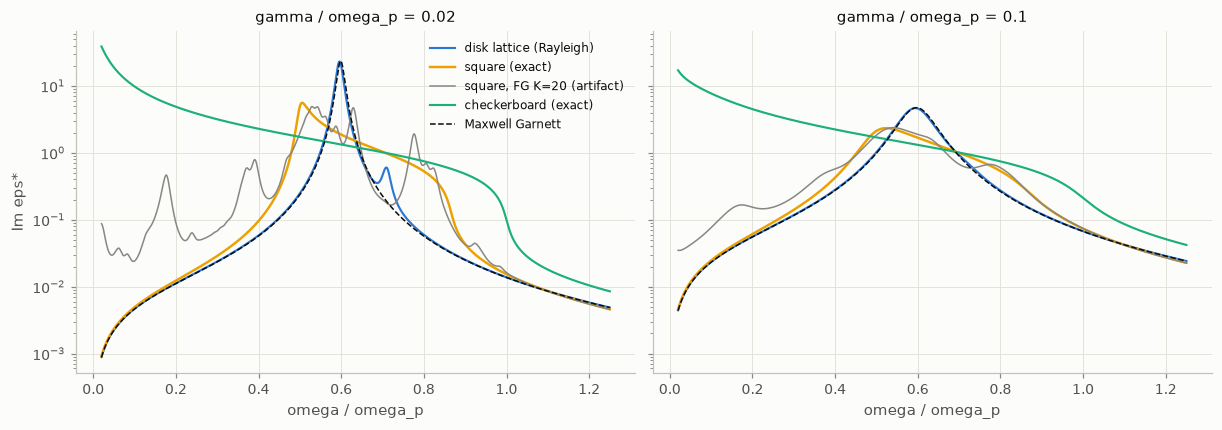

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
om = np.linspace(0.02, 1.25, 6000)
for a_, gam in zip(ax, (0.02, 0.1)):
    for (name, (f, fun)), col, ls, lw in zip(meas.items(), (CAT[0], CAT[3], MUTED, CAT[2], INK), ("-", "-", "-", "-", "--"), (1.4, 1.6, 1.0, 1.4, 1.0)):
        a_.semilogy(om, np.maximum(fun(om, gam).imag, 1e-4), color=col, lw=lw, ls=ls, label=name)
    a_.set_xlabel("omega / omega_p"); a_.set_title(f"gamma / omega_p = {gam}")
ax[0].set_ylabel("Im eps*"); ax[0].legend(fontsize=8, loc="upper right")
plt.show()

*Figure 3 caption.* $\mathrm{Im}\,\varepsilon^*$ against $\omega/\omega_p$ (log scale) for the four measures at $\gamma/\omega_p=0.02$ and $0.1$: the Maxwell Garnett peak, the disk lattice's second peak near 0.71, the exact square (orange: a continuous band with its maximum at the lower edge near 0.5), the FG square at $K=20$ (gray: its cluster of peaks, including those below 0.5, is a Rayleigh-Ritz artifact, and only the sum rule is asserted for it), and the lossless-limit absorption of the checkerboard across the band.

## 6. Lossless but absorbing: the order of limits

Checkerboard with $\varepsilon_1=-2+i\delta$, $\varepsilon_2=1$, so $s=1/(3-i\delta)\to1/3$. In the continuum $\varepsilon^*=\sqrt{-2+i\delta}\to i\sqrt2$ as $\delta\to0^+$: it absorbs with no loss, since the density at $z=1/3$ is $\rho=\sqrt2/\pi$. A finite discretization is a finite sum, and $\mathrm{Im}\,\varepsilon^*_h=\sum_kw_k\,\mathrm{Im}\,s/|s-z_k|^2$ with $\mathrm{Im}\,s=\delta/(9+\delta^2)$ is proportional to $\delta$ as $\delta\to0$ unless an atom with weight lies within about $\delta/9$ of $1/3$. The limits $h\to0$ (resolution) and $\delta\to0$ (loss) therefore do not commute: at fixed resolution $\mathrm{Im}\,\varepsilon^*_h\to0$, while for the continuum it tends to $\sqrt2$.

*Computations.* Exact discrete measures (not Lanczos): Q1 at $N=16,24,32,48$ (those of Section 3) and FG at $K=8,12,16,20$, $\delta\in\{10^{-1},\dots,10^{-4}\}$, with $d_{\min}=\min|z_k-1/3|$ over atoms with weight above $10^{-12}f$ printed, and $W_1$ of each measure to the exact checkerboard measure (the 1000-point Gauss rule), to be set beside the error at $\delta=0.1$. The smoothing scale of the Stieltjes transform at $\delta=0.1$ is $\mathrm{Im}\,s=\delta/(9+\delta^2)=0.0111$.

In [15]:
# 6. lossless but absorbing: eps1 = -2 + i delta, eps2 = 1 on the checkerboard
deltas = [1e-1, 1e-2, 1e-3, 1e-4]
cases6 = {}
for N in (16, 24, 32, 48):
    cases6[f"Q1 N={N}"] = q1chk[N]                   # the measures of section 3
for K in (8, 12, 16, 20):
    cases6[f"FG K={K}"] = sp.fg_measure("checkerboard", K)
ref = {d: np.sqrt(complex(-2, d)) for d in deltas}
print(f"continuum: eps*(delta) = sqrt(-2 + i delta) -> i sqrt(2) = {np.sqrt(2):.6f} i as delta -> 0+;  s = 1/(1-h) -> 1/3")
print(f"\n{'':9s} {'d_min':>9s} {'W1 to exact':>11s} {'error at 0.1':>13s} | {'Im eps* at delta =':^45s} | {'(Im eps*)/delta at':^25s} {'ratio':>7s}")
print(f"{'':9s} {'':>9s} {'':>11s} {'':>13s} | " + " ".join(f"{d:>10.0e}" for d in deltas) + f" | {'1e-3':>12s} {'1e-4':>12s} {'':>7s}")
res6 = {}
for lab, (z, w) in cases6.items():
    f = np.sum(w)
    dmin = np.min(np.abs(z[w > 1e-12 * f] - 1 / 3))
    eps_d = {d: sp.eps_ratio_from_measure(z, w, complex(-2, d)) for d in deltas}
    err = abs(eps_d[1e-1] - ref[1e-1])
    ratio = (eps_d[1e-4].imag / 1e-4) / (eps_d[1e-3].imag / 1e-3)
    w1_ = sp.wasserstein1(z, w, zg_cb, wg_cb)                # W1 to the exact checkerboard measure (1000-point Gauss rule, mass 1/2)
    res6[lab] = dict(dmin=dmin, err=err, ratio=ratio, im=[eps_d[d].imag for d in deltas], w1=w1_)
    print(f"{lab:9s} {dmin:9.2e} {w1_:11.5f} {err:13.2e} | " + " ".join(f"{eps_d[d].imag:10.3e}" for d in deltas) + f" | {eps_d[1e-3].imag / 1e-3:12.5f} {eps_d[1e-4].imag / 1e-4:12.5f} {ratio:7.4f}")
print(f"{'continuum':9s} {'':>9s} {'':>11s} {'':>13s} | " + " ".join(f"{ref[d].imag:10.3e}" for d in deltas))
check_in("delta = 0.1: Q1 error at N = 48 is below the error at N = 16", res6["Q1 N=48"]["err"] - res6["Q1 N=16"]["err"], -100.0, -1e-12)
check_in("delta = 0.1: the Q1 error is not monotone in N (found, not expected): err(48) - err(32)", res6["Q1 N=48"]["err"] - res6["Q1 N=32"]["err"], 1e-3, 100.0)
check_in("delta = 0.1: FG error at K = 20 is below the error at K = 8", res6["FG K=20"]["err"] - res6["FG K=8"]["err"], -100.0, -1e-12)
print(f"smoothing scale of the Stieltjes transform at delta = 0.1: Im s = delta/(9 + delta^2) = {0.1 / 9.01:.4f}")
for lab in res6:
    check(f"consistency check (a Taylor identity of a finite sum, not a finding): {lab}: Im eps*/delta at 1e-4 over Im eps*/delta at 1e-3 is 1", res6[lab]["ratio"], 1e-2, 1.0)

continuum: eps*(delta) = sqrt(-2 + i delta) -> i sqrt(2) = 1.414214 i as delta -> 0+;  s = 1/(1-h) -> 1/3

              d_min W1 to exact  error at 0.1 |              Im eps* at delta =               |    (Im eps*)/delta at       ratio
                                              |      1e-01      1e-02      1e-03      1e-04 |         1e-3         1e-4        
Q1 N=16    8.22e-02     0.02647      1.55e+00 |  3.433e-01  3.467e-02  3.468e-03  3.468e-04 |      3.46780      3.46780  1.0000
Q1 N=24    9.39e-02     0.02388      1.22e+00 |  2.384e-01  2.403e-02  2.404e-03  2.404e-04 |      2.40353      2.40353  1.0000
Q1 N=32    7.61e-02     0.02235      1.18e+00 |  2.373e-01  2.406e-02  2.406e-03  2.406e-04 |      2.40601      2.40601  1.0000
Q1 N=48    5.13e-02     0.02051      1.35e+00 |  3.414e-01  3.555e-02  3.556e-03  3.556e-04 |      3.55622      3.55623  1.0000
FG K=8     8.51e-03     0.02512      5.88e+00 |  5.282e+00  1.334e+00  1.355e-01  1.355e-02 |    135.49780    135.51922  1.

At fixed resolution the imaginary part is proportional to $\delta$: the ratio of $(\mathrm{Im}\,\varepsilon^*_h)/\delta$ at $10^{-4}$ and $10^{-3}$ is between 1.0000 and 1.0003 for all eight cases (tolerance $10^{-2}$, a priori, asserted for all eight; this is a consistency check, a Taylor identity of a finite sum once $\delta/9$ is small against the distance to the nearest atom, which passes whatever the physics, and not a finding). The values at $\delta=10^{-4}$ are 3.468e-04, 2.404e-04, 2.406e-04, 3.556e-04 for Q1 and 1.355e-02, 2.061e-03, 2.377e-03, 6.136e-03 for FG, against the continuum 1.414; so a discretization at any of these resolutions would report a nearly lossless medium as transparent. The slopes $\mathrm{Im}\,\varepsilon^*_h/\delta$ (3.47, 2.40, 2.41, 3.56 for Q1; 136, 20.6, 23.8, 61.4 for FG) are set by the weight near $s=1/3$ and are not monotone in the resolution.

The expectation recorded before the computation, that at fixed $\delta=0.1$ the discretizations approach the continuum, holds only in the weakest sense. The error $|\varepsilon^*_h-\sqrt{-2+0.1i}|$ at the finest resolution is below the coarsest for both families (Q1 $N=48$ against $N=16$: 1.35 against 1.55; FG $K=20$ against $K=8$: 0.951 against 5.88, asserted), but it is not monotone: Q1 gives 1.55, 1.22, 1.18, 1.35 and FG 5.88, 1.62, 0.0453, 0.951 for $N=16,24,32,48$ and $K=8,12,16,20$. Even the best case, FG at $K=16$ (error 0.0453, nearest atom $d_{\min}=1.07\times10^{-2}$ from $1/3$), is followed by a larger error at $K=20$ (0.951, $d_{\min}=6.19\times10^{-3}$). The weak-sense distance does not explain it: $W_1$ of the measure to the exact checkerboard measure decreases monotonically with resolution for both families (Q1 0.02647, 0.02388, 0.02235, 0.02051; FG 0.02512, 0.01963, 0.01618, 0.01460) while the errors above do not, and the $W_1$ values are 1.3 to 2.4 times the smoothing scale 0.0111, so the error at $\delta=0.1$ is governed by where individual atoms sit relative to $z=1/3$ at that scale ($d_{\min}$ is 8.2e-2, 9.4e-2, 7.6e-2, 5.1e-2 for Q1 and 8.5e-3, 2.1e-2, 1.1e-2, 6.2e-3 for FG), not by a convergence in $W_1$. A connection with Section 4, where the four-tile fields at negative contrast oscillate in $\ln r$ and have infinite energy, is a possible explanation that was not tested, and so are other atom-spacing explanations.

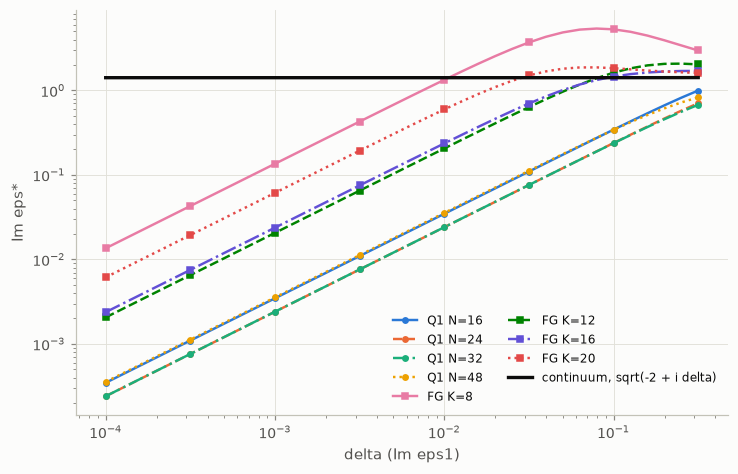

In [16]:
dd = np.logspace(-4, -0.5, 36)
fig, ax = plt.subplots(figsize=(6.6, 4.2))
for (lab, (z, w)), i in zip(cases6.items(), range(len(cases6))):
    im = np.array([sp.eps_ratio_from_measure(z, w, complex(-2, d)).imag for d in dd])
    ax.loglog(dd, im, ("-", "--", "-.", ":")[i % 4], marker=("o", "s")[i // 4], ms=3.5, markevery=5, color=CAT[i], label=lab)
ax.loglog(dd, [np.sqrt(complex(-2, d)).imag for d in dd], "-", color=INK, lw=2.2, label="continuum, sqrt(-2 + i delta)")
ax.set_xlabel("delta (Im eps1)"); ax.set_ylabel("Im eps*"); ax.legend(fontsize=8, ncol=2)
plt.show()

*Figure 4 caption.* $\mathrm{Im}\,\varepsilon^*$ against $\delta$ on log axes for the discretizations (Q1 $N=16,24,32,48$ and FG $K=8,12,16,20$ in colors, line styles and markers as in the legend) and the continuum (black): straight lines of slope one for the finite sums, a constant $\sqrt2$ for the continuum.

## 7. Bounds at complex contrast

Fix $s$ outside $[0,1]$. The set of values $\{F(s):\mu\ge0\text{ on }[0,1],\,m_0=f\}$ is convex, and so is the smaller set that also fixes $m_1=f(1-f)/2$ (isotropy, from the $C_4$ symmetry of Section 1). These are the Bergman-Milton bounds (Bergman 1980; Milton 1980, 1981; Golden and Papanicolaou 1983). The support function of the $f$-only set is $h_f(\phi)=f\max_{z\in[0,1]}\mathrm{Re}(e^{-i\phi}/(s-z))$, an exact one-dimensional maximization; that of the isotropic set is a linear program over a grid $z_j=j/4000$. A basic solution has at most two atoms, and the extremal families are Maxwell Garnett (one atom at $(1-f)/2$), the $\{0,1\}$ measure, and arcs with atoms $\{0,z\}$ or $\{z,1\}$. The Hashin-Shtrikman point with phase 1 as host is the measure $\{0:f_1/(1+f_2),\ (1+f_2)/2:f_1f_2/(1+f_2)\}$, on the $\{0,z\}$ arc at $z=(1+f_2)/2$ (and Maxwell Garnett, with phase 2 as host, is the single atom).

*Computations.* $f=1/2$; contrasts $h\in\{0.2+0.5i,\,-2+i,\,-0.5+0.2i\}$, all at least 0.087 from $[0,1]$ in $s$; 720 directions $\phi$. The isotropic support by the vectorized dual method (`method='dual'`: same discrete problem as the LP, atoms returned as a basic two-atom measure), cross-checked against the LP (HiGHS dual simplex) on a 60-direction subset. Points tested: the checkerboard ($F=1-\sqrt h$), the disk lattice at $f=1/2$ (Rayleigh, $L=40$), Maxwell Garnett, the $\{0,1\}$ measure and the phase-1-host HS measure (the last three live on the grid). A continuum measure is tested against the grid support function with a bound that follows from interpolation: splitting each atom between its two grid neighbors keeps $m_0$ and $m_1$ and changes $1/(s-z)$ by at most $\Delta z^2/(4\,\mathrm{dist}^3)$ (linear interpolation of a function with $|f''|\le2/\mathrm{dist}^3$), so a continuum value can exceed the discrete support function by at most $f\,\Delta z^2/(4\,\mathrm{dist}(s,[0,1])^3)$ with $\Delta z=2.5\times10^{-4}$, printed per contrast; it applies only to the two continuum measures. Three of the checks are theorems or algebra and test the code, not the physics: that the exact values lie inside the regions (a theorem for any positive measure with the right $m_0$, and $m_1$ for the isotropic region), that every extremal measure has at most two atoms (a basic solution of a program with two equality constraints), and the agreement of LP and dual. The corner claims are tested by counting the directions in which a measure attains the support and by checking that those directions form one contiguous arc (which a corner of a convex set must).

In [17]:
# 7. Bergman-Milton bounds at complex contrast, f = 1/2
f7, NZ = 0.5, 4001
DZ = 1.0 / (NZ - 1)
phis = np.linspace(0, 2 * np.pi, 720, endpoint=False)
contrasts = [0.2 + 0.5j, -2 + 1j, -0.5 + 0.2j]
z_hs = np.array([0.0, (1 + (1 - f7)) / 2])            # phase-1-host Hashin-Shtrikman measure: atoms 0 and (1 + f2)/2
w_hs = np.array([f7 / (1 + (1 - f7)), f7 * (1 - f7) / (1 + (1 - f7))])
cand = {"checkerboard": lambda h, s: 1 - np.sqrt(h),
        "disk lattice (Rayleigh)": lambda h, s: 1 - ry.sigma_eff(f7, h, 40),
        "Maxwell Garnett": lambda h, s: sp.stieltjes(np.array([(1 - f7) / 2]), np.array([f7]), s),
        "{0, 1} measure": lambda h, s: sp.stieltjes(np.array([0.0, 1.0]), np.array([f7 - f7 * (1 - f7) / 2, f7 * (1 - f7) / 2]), s),
        "HS, phase 1 host": lambda h, s: sp.stieltjes(z_hs, w_hs, s)}
print(f"HS (phase 1 host) measure: atoms {z_hs[0]:.2f} (weight {w_hs[0]:.4f}) and {z_hs[1]:.2f} (weight {w_hs[1]:.4f}); m0 = {w_hs.sum():.4f}, m1 = {np.sum(w_hs * z_hs):.4f} = f(1-f)/2 = {f7 * (1 - f7) / 2:.4f}")
check("HS measure has m1 = f(1-f)/2", np.sum(w_hs * z_hs), 1e-15, f7 * (1 - f7) / 2)
reg = {}
t0 = time.perf_counter()
for h in contrasts:
    s = 1 / (1 - h)
    dist = abs(s - np.clip(s.real, 0, 1))
    hf = bd.bm_support_f(s, f7, phis)
    hi, wts = bd.bm_support_iso(s, f7, phis, nz=NZ, method="dual")
    sub = np.arange(0, 720, 12)
    hlp, _ = bd.bm_support_iso(s, f7, phis[sub], nz=NZ, method="lp")
    tol = f7 * DZ ** 2 / (4 * dist ** 3)             # interpolation bound: splitting an atom between its two grid neighbors keeps m0 and m1 and moves 1/(s - z) by at most Dz^2/(4 dist^3)
    reg[h] = dict(s=s, hf=hf, hi=hi, wts=wts)
    print(f"\nh = {h}: s = {s.real:.4f}{s.imag:+.4f}i, distance from [0,1] {dist:.3f}; grid bound f Dz^2/(4 dist^3) = {tol:.2e}; LP (60 directions) vs dual: max difference {np.max(np.abs(hlp - hi[sub])):.1e}")
    check_in(f"h = {h}: distance from s to [0, 1] is at least 0.087", dist, 0.087, 10.0)
    check(f"h = {h}: LP and dual agree on 60 directions", np.max(np.abs(hlp - hi[sub])), 1e-7)
    print(f"   {'measure':24s} {'max (Re - h_f)':>15s} {'max (Re - h_iso)':>17s} {'min (h_f - Re)':>15s} {'min (h_iso - Re)':>17s} {'directions on support (f-only / iso)':>38s}")
    for name, fun in cand.items():
        F = fun(h, s)
        proj = (np.exp(-1j * phis) * F).real
        row = dict(F=F, mf=np.max(proj - hf), mi=np.max(proj - hi), gf=np.min(hf - proj), gi=np.min(hi - proj),
                   nf=int(np.sum(hf - proj < 1e-8)), ni=int(np.sum(np.abs(hi - proj) < 1e-8)))
        reg[h][name] = row
        print(f"   {name:24s} {row['mf']:15.2e} {row['mi']:17.2e} {row['gf']:15.2e} {row['gi']:17.2e} {row['nf']:>17d} {row['ni']:>17d}")
        if name != "HS, phase 1 host":
            pass
    for name in ("checkerboard", "disk lattice (Rayleigh)", "Maxwell Garnett"):
        check_in(f"solver test (a theorem for any positive measure with the right m0; it tests the support solver and the branch of 1 - sqrt(h)), h = {h}: {name} lies inside the f-only region (max of Re(e^-i phi F) - h_f)", reg[h][name]["mf"], -10.0, 1e-9)
    for name in ("checkerboard", "disk lattice (Rayleigh)"):
        check_in(f"solver test (a theorem given m0 and m1; the bound is the interpolation error): h = {h}: {name} lies inside the isotropic region up to the grid bound {tol:.1e}", reg[h][name]["mi"], -10.0, tol)
    for name in ("Maxwell Garnett", "{0, 1} measure", "HS, phase 1 host"):
        check_in(f"h = {h}: {name} (on the grid) lies inside the isotropic region to 1e-8", reg[h][name]["mi"], -10.0, 1e-8)
print(f"\nregions computed in {time.perf_counter() - t0:.1f} s")

HS (phase 1 host) measure: atoms 0.00 (weight 0.3333) and 0.75 (weight 0.1667); m0 = 0.5000, m1 = 0.1250 = f(1-f)/2 = 0.1250
PASS  HS measure has m1 = f(1-f)/2: got 0.125, target 0.125, |diff| 0.00e+00 <= 1e-15



h = (0.2+0.5j): s = 0.8989+0.5618i, distance from [0,1] 0.562; grid bound f Dz^2/(4 dist^3) = 4.41e-08; LP (60 directions) vs dual: max difference 1.6e-08
PASS  h = (0.2+0.5j): distance from s to [0, 1] is at least 0.087: got 0.561798, required in [0.087, 10]
PASS  h = (0.2+0.5j): LP and dual agree on 60 directions: got 1.61365e-08, target 0, |diff| 1.61e-08 <= 1e-07
   measure                   max (Re - h_f)  max (Re - h_iso)  min (h_f - Re)  min (h_iso - Re)   directions on support (f-only / iso)
   checkerboard                   -5.12e-02         -1.81e-02        5.12e-02          1.81e-02                 0                 0
   disk lattice (Rayleigh)        -3.86e-03         -1.77e-03        3.86e-03          1.77e-03                 0                 0
   Maxwell Garnett                -3.52e-06          1.11e-16        3.52e-06         -1.11e-16                 0               224
   {0, 1} measure                 -1.05e-03          1.11e-16        1.05e-03         -1.11e-16   


h = (-2+1j): s = 0.3000+0.1000i, distance from [0,1] 0.100; grid bound f Dz^2/(4 dist^3) = 7.81e-06; LP (60 directions) vs dual: max difference 1.5e-08
PASS  h = (-2+1j): distance from s to [0, 1] is at least 0.087: got 0.1, required in [0.087, 10]
PASS  h = (-2+1j): LP and dual agree on 60 directions: got 1.53059e-08, target 0, |diff| 1.53e-08 <= 1e-07
   measure                   max (Re - h_f)  max (Re - h_iso)  min (h_f - Re)  min (h_iso - Re)   directions on support (f-only / iso)
   checkerboard                   -1.09e+00         -1.03e+00        1.09e+00          1.03e+00                 0                 0
   disk lattice (Rayleigh)        -3.22e-01         -2.24e-01        3.22e-01          2.24e-01                 0                 0
   Maxwell Garnett                -6.45e-06          0.00e+00        6.45e-06          0.00e+00                 0                53
   {0, 1} measure                 -1.90e-03          0.00e+00        1.90e-03          0.00e+00                 


h = (-0.5+0.2j): s = 0.6550+0.0873i, distance from [0,1] 0.087; grid bound f Dz^2/(4 dist^3) = 1.17e-05; LP (60 directions) vs dual: max difference 8.7e-09
PASS  h = (-0.5+0.2j): distance from s to [0, 1] is at least 0.087: got 0.0873362, required in [0.087, 10]
PASS  h = (-0.5+0.2j): LP and dual agree on 60 directions: got 8.65225e-09, target 0, |diff| 8.65e-09 <= 1e-07
   measure                   max (Re - h_f)  max (Re - h_iso)  min (h_f - Re)  min (h_iso - Re)   directions on support (f-only / iso)
   checkerboard                   -5.54e-01         -5.10e-01        5.54e-01          5.10e-01                 0                 0
   disk lattice (Rayleigh)        -4.68e-02         -3.53e-02        4.68e-02          3.53e-02                 0                 0
   Maxwell Garnett                -1.16e-05          6.94e-18        1.16e-05         -6.94e-18                 0                43
   {0, 1} measure                 -1.04e-03          2.78e-17        1.04e-03         -2.78e-1

In [18]:
# 7(b). which measures attain the support: classification of the 720 extremal measures per contrast
j_mg = int(round((1 - f7) / 2 * (NZ - 1)))
print(f"{'h':>10s} {'single (MG)':>12s} {'{0, 1}':>8s} {'{0, z}':>8s} {'{z, 1}':>8s} {'other':>6s} {'max atoms':>10s}")
for h in contrasts:
    W = reg[h]["wts"]
    cls = dict(single=0, zero_one=0, zero_z=0, z_one=0, other=0)
    natoms = []
    for row in W:
        nz = np.flatnonzero(row > 1e-10)
        natoms.append(len(nz))
        if len(nz) == 1 and nz[0] == j_mg:
            cls["single"] += 1
        elif len(nz) == 2 and nz[0] == 0 and nz[1] == NZ - 1:
            cls["zero_one"] += 1
        elif len(nz) == 2 and nz[0] == 0:
            cls["zero_z"] += 1
        elif len(nz) == 2 and nz[1] == NZ - 1:
            cls["z_one"] += 1
        else:
            cls["other"] += 1
    reg[h]["cls"] = cls
    print(f"{h!s:>10s} {cls['single']:12d} {cls['zero_one']:8d} {cls['zero_z']:8d} {cls['z_one']:8d} {cls['other']:6d} {max(natoms):10d}")
    check_in(f"solver unit test (a basic solution of a program with two equality constraints has at most two atoms), h = {h}: every extremal measure has at most two atoms", max(natoms), 1, 2)
    check(f"h = {h}: every extremal measure is a single MG atom, {{0, 1}}, {{0, z}} or {{z, 1}} (number of other)", cls["other"], 0)
    # the corner test: MG attains the support, and in more than one direction
    gap = np.max((np.exp(-1j * phis) * reg[h]["Maxwell Garnett"]["F"]).real - reg[h]["hi"])
    check_in(f"h = {h}: MG attains the isotropic support (max of Re(e^-i phi F_MG) - h_iso)", gap, -1e-8, 1e-8)
    check_in(f"h = {h}: MG attains the support in more than one of the 720 directions", reg[h]["Maxwell Garnett"]["ni"], 2, 720)
    for nm_ in ("Maxwell Garnett", "{0, 1} measure"):
        mask_ = np.abs(reg[h]["hi"] - (np.exp(-1j * phis) * reg[h][nm_]["F"]).real) < 1e-8
        runs_ = int(np.sum(mask_ & ~np.roll(mask_, 1)))      # number of cyclic runs of consecutive attaining directions
        check(f"h = {h}: the directions attained by {nm_} form one contiguous arc (a corner of a convex set; number of runs)", runs_, 0, 1)
    check_in(f"h = {h}: the {{0, 1}} measure attains it in as many directions as MG", reg[h]["{0, 1} measure"]["ni"] - reg[h]["Maxwell Garnett"]["ni"], 0, 0)

# the phase-1-host HS point touches the support between two of the sampled directions: refine
print("\nHS point with phase 1 as host: refinement of the touching direction")
for h in contrasts:
    s = reg[h]["s"]
    F = reg[h]["HS, phase 1 host"]["F"]
    g = reg[h]["hi"] - (np.exp(-1j * phis) * F).real
    k = int(np.argmin(g))
    fine = phis[k] + np.linspace(-0.01, 0.01, 401)
    hfine, _ = bd.bm_support_iso(s, f7, fine, nz=NZ, method="dual")
    gfine = hfine - (np.exp(-1j * fine) * F).real
    print(f"h = {h!s:>10s}: smallest gap on the 720 directions {g[k]:.2e} (at phi = {phis[k]:.4f}); on 401 directions within 0.01 rad: {gfine.min():.2e}; directions within 1e-8 of the support: {int(np.sum(gfine < 1e-8))}")
    check_in(f"h = {h}: HS (phase 1 host) touches the isotropic support (smallest gap on the fine grid below 1e-8)", gfine.min(), -1e-8, 1e-8)
    # a smooth boundary point has a quadratic gap in the direction (ratio 4 on doubling the offset); a corner has a linear one (ratio 2)
    phi0 = fine[int(np.argmin(gfine))]
    offs = np.array([0.01, 0.02, 0.04])
    gp = []
    for sgn in (+1, -1):
        hh, _ = bd.bm_support_iso(s, f7, phi0 + sgn * offs, nz=NZ, method="dual")
        gp.append(hh - (np.exp(-1j * (phi0 + sgn * offs)) * F).real)
    r1, r2 = gp[0][1] / gp[0][0], gp[0][2] / gp[0][1]
    r3, r4 = gp[1][1] / gp[1][0], gp[1][2] / gp[1][1]
    print(f"              gap at offsets 0.01, 0.02, 0.04: {gp[0][0]:.2e}, {gp[0][1]:.2e}, {gp[0][2]:.2e} (ratios {r1:.2f}, {r2:.2f}); other side ratios {r3:.2f}, {r4:.2f}")
    check_in(f"h = {h}: HS (phase 1 host): the gap grows quadratically in the offset (smallest ratio on doubling the offset; 2 would be a corner)", min(r1, r2, r3, r4), 3.3, 4.7)
    check_in(f"h = {h}: ... and the largest ratio", max(r1, r2, r3, r4), 3.3, 4.7)

         h  single (MG)   {0, 1}   {0, z}   {z, 1}  other  max atoms
(0.2+0.5j)          224      224      237       35      0          2
PASS  solver unit test (a basic solution of a program with two equality constraints has at most two atoms), h = (0.2+0.5j): every extremal measure has at most two atoms: got 2, required in [1, 2]
PASS  h = (0.2+0.5j): every extremal measure is a single MG atom, {0, 1}, {0, z} or {z, 1} (number of other): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  h = (0.2+0.5j): MG attains the isotropic support (max of Re(e^-i phi F_MG) - h_iso): got 1.11022e-16, required in [-1e-08, 1e-08]
PASS  h = (0.2+0.5j): MG attains the support in more than one of the 720 directions: got 224, required in [2, 720]
PASS  h = (0.2+0.5j): the directions attained by Maxwell Garnett form one contiguous arc (a corner of a convex set; number of runs): got 1, target 1, |diff| 0.00e+00 <= 0e+00
PASS  h = (0.2+0.5j): the directions attained by {0, 1} measure form one contiguous arc 

h =    (-2+1j): smallest gap on the 720 directions 4.53e-06 (at phi = 1.6842); on 401 directions within 0.01 rad: -1.11e-16; directions within 1e-8 of the support: 5
PASS  h = (-2+1j): HS (phase 1 host) touches the isotropic support (smallest gap on the fine grid below 1e-8): got -1.11022e-16, required in [-1e-08, 1e-08]
              gap at offsets 0.01, 0.02, 0.04: 9.70e-05, 3.92e-04, 1.57e-03 (ratios 4.04, 4.02); other side ratios 3.96, 3.98
PASS  h = (-2+1j): HS (phase 1 host): the gap grows quadratically in the offset (smallest ratio on doubling the offset; 2 would be a corner): got 3.96388, required in [3.3, 4.7]
PASS  h = (-2+1j): ... and the largest ratio: got 4.03679, required in [3.3, 4.7]
h = (-0.5+0.2j): smallest gap on the 720 directions 1.48e-06 (at phi = 2.9234); on 401 directions within 0.01 rad: -2.78e-16; directions within 1e-8 of the support: 52
PASS  h = (-0.5+0.2j): HS (phase 1 host) touches the isotropic support (smallest gap on the fine grid below 1e-8): got -2.7

All the exact values lie inside both regions. For the continuum measures the smallest margin to the isotropic boundary is 1.81e-02 (checkerboard) and 1.77e-03 (disk lattice) at $h=0.2+0.5i$, 1.03 and 0.224 at $-2+i$, and 0.510 and 3.53e-02 at $-0.5+0.2i$, and the interpolation bounds are 4.41e-08, 7.81e-06, 1.17e-05 (an unproved heuristic $f\Delta z/\mathrm{dist}^2$ would give 3.96e-04, 1.25e-02, 1.64e-02 and is not used), so the margins exceed the bounds by a wide factor in every case. The LP and dual agree to 1.6e-08, 1.5e-08 and 8.7e-09 on the 60-direction subset, within the $10^{-7}$ the module quotes.

Every one of the 720 extremal measures per contrast is one of four types (a single Maxwell Garnett atom, $\{0,1\}$, $\{0,z\}$, $\{z,1\}$), none has more than two atoms, and none is of another kind. The counts are 224, 53, 43 for the single Maxwell Garnett atom, the same numbers for the $\{0,1\}$ measure, and 237, 434, 615 and 35, 180, 19 for $\{0,z\}$ and $\{z,1\}$ at the three contrasts. This differs from the expectation recorded before the computation that Maxwell Garnett is the corner of the lens: Maxwell Garnett is a corner of the lens (it attains the support, to $10^{-8}$, in more than one direction: 224, 53, 43 of 720), where the $\{0,z\}$ and $\{z,1\}$ arcs meet, but so is the $\{0,1\}$ measure, which attains it in exactly as many directions, and which is not a microstructure. The second Hashin-Shtrikman point (phase 1 as host) is not a corner: it touches the region with a gap that grows quadratically with the offset in direction (ratios 3.63 to 4.56 on doubling the offset; a corner would give 2), and the smallest gap on the 720 sampled directions (5.10e-07, 4.53e-06, 1.48e-06) comes from the angular sampling (the touching direction lies between two sampled directions) and falls to rounding (below $3\times10^{-16}$) on a fine grid. The second corner of the lens is therefore the $\{0,1\}$ measure, not the Hashin-Shtrikman point, which is a smooth boundary point (it is the measure $\{0:f_1/(1+f_2),\ (1+f_2)/2:f_1f_2/(1+f_2)\}$, which reproduces the two-dimensional Hashin-Shtrikman formula of Hashin and Shtrikman 1962 for phase 1 as host). The directions attained by Maxwell Garnett and by the $\{0,1\}$ measure each form one contiguous arc (one run of consecutive directions at each contrast). The $m_0/m_1$ region is a valid region but is not claimed to be the sharp two-dimensional isotropic one: the sharp region also needs the measure of the phase-swapped medium (Milton 1981), which was not intersected.

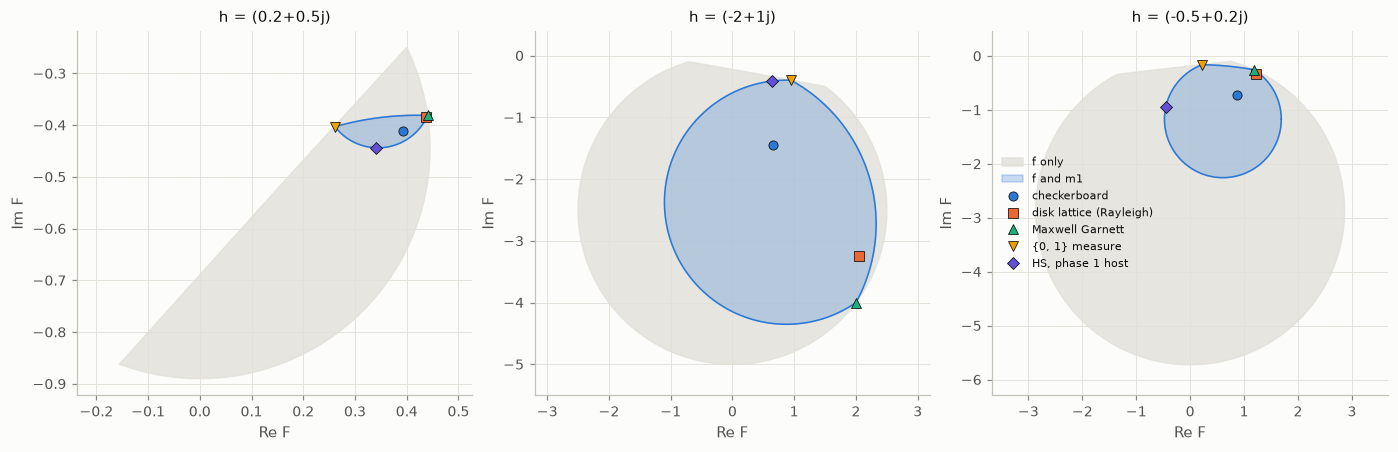

In [19]:
def polygon(phis_, h_):
    nxt = np.roll(np.arange(len(phis_)), -1)
    A = np.stack([np.stack([np.cos(phis_), np.sin(phis_)], 1), np.stack([np.cos(phis_[nxt]), np.sin(phis_[nxt])], 1)], 1)   # (n, 2, 2)
    b = np.stack([h_, h_[nxt]], 1)
    return np.linalg.solve(A, b[..., None])[..., 0]


fig, ax = plt.subplots(1, 3, figsize=(12.6, 4.0))
mk = {"checkerboard": ("o", CAT[0]), "disk lattice (Rayleigh)": ("s", CAT[1]), "Maxwell Garnett": ("^", CAT[2]), "{0, 1} measure": ("v", CAT[3]), "HS, phase 1 host": ("D", CAT[6])}
for a_, h in zip(ax, contrasts):
    Pf, Pi = polygon(phis, reg[h]["hf"]), polygon(phis, reg[h]["hi"])
    a_.fill(Pf[:, 0], Pf[:, 1], color=GRID, alpha=0.8, label="f only")
    a_.fill(Pi[:, 0], Pi[:, 1], color=CAT[0], alpha=0.25, label="f and m1")
    a_.plot(Pi[:, 0], Pi[:, 1], color=CAT[0], lw=1.0)
    for name, (m, col) in mk.items():
        F = reg[h][name]["F"]
        a_.plot(F.real, F.imag, m, color=col, ms=6, label=name, mec=INK, mew=0.5)
    a_.set_title(f"h = {h}"); a_.set_xlabel("Re F"); a_.set_aspect("equal", adjustable="datalim")
for a_ in ax:
    a_.set_ylabel("Im F")
ax[2].legend(fontsize=7, loc="best")
plt.show()

*Figure 5 caption.* The Bergman-Milton regions of $F$ at the three contrasts: gray, $m_0=f$ only; blue, also $m_1=f(1-f)/2$. Markers: checkerboard, disk lattice, Maxwell Garnett (a corner, with the $\{0,1\}$ measure at the other end of the same arc) and the HS point with phase 1 as host (a smooth boundary point).

## 8. How many numbers does a spectrum carry?

The map from a density on 400 points $z_i=(i+1/2)/400$ to the data $F(s_j)=\sum_i\rho_i\,\Delta z/(s_j-z_i)$ is linear, with a Cauchy kernel, and its singular values give an information count. Real-valued designs use the real matrix; complex designs stack real and imaginary parts, so "120 real numbers" means 120 real contrasts or 60 complex frequencies. Designs: (a) lossless contrasts $h\in[1.5,1000]$, geometrically spaced, $s<0$, on one side of the support; (a2) real contrasts on both sides, the same $h$ (60 values) and their reciprocals $1/h$ (so $s<0$ and $s>1$, probing both ends of the support); (a3) the same with $h$ up to $10^4$; (b) Drude spectra at $\omega/\omega_p\in[0.2,1.2]$ with $\gamma=0.20$; (c) the same with $\gamma=0.05$. Both 120 and 60 real numbers per design are shown (comparing 60 real numbers in (a) with 120 in (b) and (c) would mix the data count with the design). The count is the number of singular values above a fraction of the design's own largest singular value $\sigma_1$, so it is relative to each design and not an absolute number of recoverable parameters; every design is also run row-normalized (each datum scaled to unit norm, a proxy for relative noise, since the contrast-1000 rows dominate the unnormalized matrix). The threshold: the testbed's 30 dB is a power ratio, so the amplitude threshold is $10^{-1.5}$; $10^{-3}$ (60 dB amplitude) is also printed, and $10^{-2}$. This is the imaging-theory reading: static or real-contrast data meet the exponential ill-posedness of the Stieltjes moment problem, while lossy plasmonic spectra probe $s$ near the support and resolve the measure locally. As a control, Drude data far from the support ($1.3<\omega/\omega_p<3$, $\mathrm{Re}\,s>1$) are included.

In [20]:
# 8. how many numbers does a spectrum carry?  Linear map from a density on 400 z-points to the data F(s_j)
NZ8 = 400
z8 = (np.arange(NZ8) + 0.5) / NZ8


def design_matrix(s, normalize=False):
    """Stacked real/imaginary Cauchy kernel; with normalize, each datum (one real row, or a real/imaginary pair) is scaled to unit norm (a relative-noise proxy)."""
    A = (1.0 / NZ8) / (np.asarray(s)[:, None] - z8[None, :])
    if normalize:
        A = A / np.sqrt(np.sum(np.abs(A) ** 2, axis=1, keepdims=True))
    return np.vstack([A.real, A.imag]) if np.iscomplexobj(A) else A


def designs(n_real, normalize=False):
    """Designs with n_real real numbers each: real contrasts on one side of the support (s < 0), real contrasts on both sides (h and 1/h, s < 0 and s > 1),
    the same with the range extended to 1e4, and Drude spectra with two loss levels."""
    nc, nf = n_real, n_real // 2
    h = np.geomspace(1.5, 1000.0, nc)                    # geometrically spaced contrasts
    h2 = np.geomspace(1.5, 1000.0, nc // 2)
    h3 = np.geomspace(1.5, 1.0e4, nc // 2)
    om = np.linspace(0.2, 1.2, nf)
    dm = lambda s_: design_matrix(s_, normalize)
    return {"(a) real contrasts, h > 1": (dm(1 / (1 - h)), 1 / (1 - h)),
            "(a2) real, h and 1/h": (dm(1 / (1 - np.concatenate([h2, 1 / h2]))), 1 / (1 - np.concatenate([h2, 1 / h2]))),
            "(a3) real, h and 1/h to 1e4": (dm(1 / (1 - np.concatenate([h3, 1 / h3]))), 1 / (1 - np.concatenate([h3, 1 / h3]))),
            "(b) Drude, gamma = 0.20": (dm(sp.drude_s(om, 1.0, 0.20)), sp.drude_s(om, 1.0, 0.20)),
            "(c) Drude, gamma = 0.05": (dm(sp.drude_s(om, 1.0, 0.05)), sp.drude_s(om, 1.0, 0.05))}


thr = {"10^-1.5 (30 dB power)": 10 ** -1.5, "1e-2": 1e-2, "1e-3 (60 dB amplitude)": 1e-3}
sv8, cnt8 = {}, {}
print("counts are numbers of singular values above the threshold times the design's own largest singular value")
print(f"{'design':30s} {'data (real)':>12s} {'min dist(s,[0,1])':>18s} | " + " ".join(f"{k:>22s}" for k in thr))
for normalize in (False, True):
    print("row-normalized (each datum scaled to unit norm)" if normalize else "unnormalized")
    for nreal in (120, 60):
        for name, (A, s_) in designs(nreal, normalize).items():
            sv = np.linalg.svd(A, compute_uv=False)
            dist = np.min(np.abs(s_ - np.clip(np.real(s_), 0, 1)))
            cnt8[(nreal, name, normalize)] = [int(np.sum(sv > t * sv[0])) for t in thr.values()]
            sv8[(nreal, name, normalize)] = sv
            print(f"{name:30s} {A.shape[0]:12d} {dist:18.3f} | " + " ".join(f"{c:22d}" for c in cnt8[(nreal, name, normalize)]))
        print()
# a control: Drude data far from the support (omega > omega_p)
om_far = np.linspace(1.3, 3.0, 60)
sv_far = np.linalg.svd(design_matrix(sp.drude_s(om_far, 1.0, 0.20)), compute_uv=False)
c_far = [int(np.sum(sv_far > t * sv_far[0])) for t in thr.values()]
print(f"{'control: Drude 0.20, 1.3 < omega < 3':30s} {120:12d} {np.min(np.abs(sp.drude_s(om_far, 1.0, 0.2) - 1)):18.3f} | " + " ".join(f"{c:22d}" for c in c_far))
names8 = ("(a) real contrasts, h > 1", "(a2) real, h and 1/h", "(b) Drude, gamma = 0.20", "(c) Drude, gamma = 0.05")
for normalize in (False, True):
    cc = [cnt8[(120, k, normalize)] for k in names8]
    for i, t in enumerate(thr):
        check_in(f"{'row-normalized, ' if normalize else ''}threshold {t}: count(a) < count(a2) < count(b) < count(c) at 120 real numbers each", float(cc[0][i] < cc[1][i] < cc[2][i] < cc[3][i]), 1.0, 1.0)
a, a2, b, c = (cnt8[(120, k, False)] for k in names8)
check_in("one-sided real contrasts carry few numbers: count(a) at 30 dB power is at most 10 (120 contrasts)", a[0], 1, 10)
check_in("one-sided real contrasts carry few numbers: count(a) at 1e-3 is at most 10 (120 contrasts)", a[2], 1, 10)
check_in("two-sided real contrasts at 1e-3: count(a2) is at most twice count(a) plus one (both signs roughly double it; bound set after the run)", a2[2] - 2 * a[2], -100, 1)
for k in names8[:2]:
    check_in(f"{k}: the count does not grow with the number of contrasts (120 against 60, at 1e-3)", cnt8[(120, k, False)][2] - cnt8[(60, k, False)][2], 0, 1)
check_in("the control (omega > omega_p) carries fewer numbers than design (b) at 30 dB power", c_far[0] - b[0], -1000, -1)

counts are numbers of singular values above the threshold times the design's own largest singular value
design                          data (real)  min dist(s,[0,1]) |  10^-1.5 (30 dB power)                   1e-2 1e-3 (60 dB amplitude)
unnormalized
(a) real contrasts, h > 1               120              0.001 |                      3                      4                      6
(a2) real, h and 1/h                    120              0.001 |                      6                      8                     11
(a3) real, h and 1/h to 1e4             120              0.000 |                      6                      7                     10
(b) Drude, gamma = 0.20                 120              0.040 |                     12                     15                     22
(c) Drude, gamma = 0.05                 120              0.010 |                     38                     50                     75

(a) real contrasts, h > 1                60              0.001 |              

At the amplitude threshold $10^{-1.5}$ the designs (a), (b), (c) carry 3, 12 and 38 numbers with 120 real data each (at $10^{-2}$: 4, 15, 50; at $10^{-3}$: 6, 22, 75), and real contrasts on both sides of the support (a2) carry 6, 8, 11 (a3, range to $10^4$: 6, 7, 10). The order (a) < (a2) < (b) < (c) holds at every threshold, unnormalized and row-normalized. Row-normalizing changes the counts by at most 3: (a) 4, 5, 7; (a2) 7, 8, 12; (a3) 7, 9, 12; (b) 11, 15, 22; (c) 35, 47, 72. With half the data (60 real numbers) the counts of (a), (a2), (a3) and (b) do not change and those of (c) are limited by the data: 38, 48, 50 at the three thresholds. Real contrasts of one sign therefore carry 3 to 6 numbers of the measure over the three thresholds (7 at most when row-normalized), real contrasts of both signs 6 to 11 (12 row-normalized), and both are far fewer than lossy plasmonic spectra (12 to 22 for $\gamma=0.20$, 38 to 75 for $\gamma=0.05$). Within the same range more contrasts do not help (60 and 120 give the same counts), and extending the range to $10^4$ does not either (6, 7, 10).

Distance alone does not decide it. Design (a) has the smallest distance of all, 0.001 (the contrast 1000 sits next to the endpoint $z=0$), against 0.040 and 0.010 for (b) and (c), and (a2) has the same distance, but twice the count: the reciprocal contrasts probe the other endpoint, $z=1$. What matters is where along the support the probe samples. Real contrasts $s\in(-2,-0.001)$ touch the support only at its endpoint $z=0$ and see a smooth kernel elsewhere, about three numbers at 30 dB per endpoint, whereas $s=\omega^2+i\gamma\omega$ sweeps the real part across $[0,1.44]$ and resolves a window of width of order $\gamma\omega$ around each $\mathrm{Re}\,s\in[0,1]$. The two-sided design confirms the endpoint reading and, by reaching only 6 to 11 against (b)'s 12 to 22 at the same distance, supports the sweeping reading. The control agrees: Drude data with $\mathrm{Re}\,s>1$ (distance 0.737 from the support) carry 2, 2, 3 numbers at the three thresholds, fewer than (b) in each case, although they are complex and plentiful.

The singular values of each design fall approximately exponentially, which is the shape of the ill-posedness: the count is the index at which the curve crosses the threshold (Figure 6), and a lower noise floor buys a number of extra coefficients proportional to the change in $\ln(1/\text{floor})$ divided by the slope. For design (c) the curve is shallow, and with 60 real data the count is limited by the data (50 of 60 at $10^{-3}$). Figure 6 shows the one-sided, two-sided, and Drude curves; counts are relative to each curve's own largest singular value.

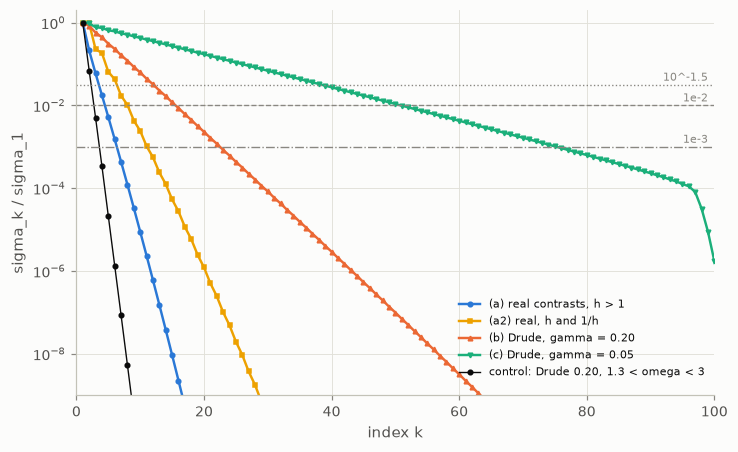

In [21]:
fig, ax = plt.subplots(figsize=(6.6, 4.0))
for (name, col, mk_) in zip(names8, (CAT[0], CAT[3], CAT[1], CAT[2]), ("o", "s", "^", "v")):
    sv = sv8[(120, name, False)]
    ax.semilogy(np.arange(1, len(sv) + 1), sv / sv[0], mk_ + "-", ms=3, color=col, label=name)
ax.semilogy(np.arange(1, len(sv_far) + 1), sv_far / sv_far[0], "o-", ms=3, color=INK, lw=0.9, label="control: Drude 0.20, 1.3 < omega < 3")
for t, ls in zip(thr.values(), (":", "--", "-.")):
    ax.axhline(t, color=MUTED, ls=ls, lw=0.9)
ax.set_ylim(1e-9, 2); ax.set_xlim(0, 100)
ax.set_xlabel("index k"); ax.set_ylabel("sigma_k / sigma_1"); ax.legend(fontsize=7, loc="lower right", bbox_to_anchor=(1.0, 0.02))
for t, lab in zip(thr.values(), ("10^-1.5", "1e-2", "1e-3")):
    ax.text(99, t * 1.25, lab, ha="right", fontsize=7, color=MUTED)
plt.show()

*Figure 6 caption.* Singular values of the four designs (a), (a2), (b), (c) (120 real numbers each, unnormalized) and of the control, normalized by the largest, against index; the horizontal lines are the thresholds $10^{-1.5}$ (dotted), $10^{-2}$ (dashed) and $10^{-3}$ (dash-dotted).

In [22]:
print(f"total run time of the notebook (from the second cell): {time.perf_counter() - T_START:.1f} s; budget 150 s with 4 threads")

total run time of the notebook (from the second cell): 35.8 s; budget 150 s with 4 threads


## Caveats and open ends

- **What was not done.** No inversion was attempted in Section 8: the counts are singular values of one linearization (a 400-point density, Cauchy kernel, no prior), relative to each design's own largest singular value, and they depend on the threshold, the grid, the spacing of contrasts (geometric) and frequencies (linear), the range of contrasts and the noise model (row-normalized and unnormalized counts differ by up to 3). "Six numbers at 60 dB amplitude, three at 30 dB power" describes one-sided real-contrast data of this kind, and "eleven and six" two-sided data; neither says what a prior or a regularizer could extract. That design (c) is limited by its data count is confirmed (50 numbers from 60 real data at $10^{-3}$).
- **Rayleigh-Ritz atoms.** FG and Q1 measures are compressions, so no statement about individual atoms (positions, counts, the "dominant" atom) converges; the notebook describes them by moments, $W_1$, cluster weights and variances. The FG weight below $z=1/4$ for the square (exact: zero) is leakage that is not monotone in $K$. The weight in $(0,0.05]$ for FG decreases slowly and is not an atom at zero; the FG weight at zero falls like about $e^{-2.6K}$ over $K=4$ to 8 only (three points) and sits at a round-off floor of order $10^{-11}$ from $K=10$ on, whose values depend on the eigensolver and the thread count; only $K=4,6,8$ enter the fit. A direct $\sigma_1\to\infty$ solve did not converge and was not used.
- **Pre-asymptotic.** The Q1 checkerboard atom at zero has been followed over $N=16$ to 256; its slope in $\ln N$ is derived by a leading-logarithm spreading-resistance argument and agrees with $4/\pi$ to 8e-6 in the free-slope fit, but the argument does not give $c=1.5308$ or the $d/N^2$ correction, which are fitted. The sampled Jacobi coefficients are converged only for $k\le4$ or so. Dilute and near-touching Rayleigh measures need more multipoles near $f=\pi/4$ (the $f=0.7$ rows use $L=60$ and 100).
- **The corner band.** The exact solution of Section 2(d) settles the $f=1/4$ square: the measure has a density on exactly $[1/4,3/4]$ and variance 1/64, and the Q1 atom at $1/4$ is the relabeled checkerboard percolation atom. What remains: (i) the formula is a published result (the case $f=1/4$ of the Mortola-Steffe formula, conjectured in 1985 and proved in 2001 by Craster and Obnosov and, independently, by Milton) that this notebook certifies numerically to the bracket widths (Q1 $N=128$: half-widths 1.1e-4 to 6.8e-4; FG $K=64$: 2.0e-3 to 1.3e-2), not a derivation, and the proofs were not read; (ii) it is one cell, so it does not test the Perfekt-Putinar theorem for other polygons or angles, and the side scan shows that the Q1 behavior at $f=1/4$ does not transfer to other squares or to the rectangle; (iii) the Perfekt-Putinar formula $[-\tfrac12|1-\alpha/\pi|,\tfrac12|1-\alpha/\pi|]$ was taken from the literature (Perfekt-Putinar, Bonnetier-Zhang) as recorded in PLAN.md, not re-read here; (iv) the $H^1$-Fredholm consequence of imaginary exponents is from memory. The FG counting statistics (atom counts, weight outside $[0.23,0.77]$) still cannot see the band at $K\le24$.
- **Tolerances set after seeing results.** The Lanczos-versus-`spectral_sampled` tolerance ($10^{-10}$; $10^{-8}$ was set beforehand), the absorption sum rule ($10^{-9}$; $10^{-3}$ beforehand), the log-linear fit residual (0.1) and step factor (50) for the FG atom at zero, the tolerance 1e-4 on the free slope and on the stability of $c$ in the Q1 checkerboard fit (the bound 2e-3 on local slopes is set from the derivation, not fitted), the tolerance $10^{-11}$ of the discrete identities of Section 2(d), the ratio bounds on the Jacobi trends (0.999), the variance and quantile thresholds of Section 4 (ratio at least 3 at $K=24$, $q_{10}\le0.27$ and $\ge0.30$), the staircase weight below $1/4$ at least 0.01, the side-scan thresholds (0.5 for the weight below $1/4$, margin 1e-3 above $1/4$), the quadratic-gap bounds 3.3 to 4.7 of Section 7, and the count bounds of Section 8 (at most 10 for one-sided real contrasts; the two-sided count at most twice the one-sided plus one). Tolerances stated a priori are marked as such in the text. Several checks are unit tests or consistency checks and are labeled so in their names (the three measure-reproduces-solver identities, the sums of weights, the Rayleigh measure against its own `sigma_eff`, the linearity of $\mathrm{Im}\,\varepsilon^*$ in $\delta$, the containment of exact values in the Bergman-Milton regions, the two-atom property of extremal measures): they test the code, not the physics.
- **Where the computation differs from the expectations recorded beforehand.** PLAN.md records the design, the expectations written before the computations, and the corrections made after an independent review. The reference values for the rod lattice are those at $f=\pi\,0.3^2$; the dilute targets and the $f=0.7$ truncation settings are those set after the independent review; the FG atom at zero is tested at $K=4,6,8,10,12,14$ as a floor-limited exponential, not as $1/K$; the monotone FG checks and the "99%-atom count at most 5" are dropped; the MG-corner check also counts directions and the extremal measures include $\{0,1\}$; the Drude sum rule integrates from $\omega=0$; the lossless check goes through the density; the exact square of Section 2(d), the percolation-atom derivation and extension to $N=256$, the side scan and the two-sided information design are additions.
- **Not intersected.** The sharp two-dimensional isotropic region (the intersection with the region of the phase-swapped measure, Milton 1981) was not computed; the $m_0/m_1$ region of Section 7 is valid but not sharp.

## References

Entries marked "checked" were verified against publisher or library records ("Literature (verified)" in `PLAN.md`); that confirms the bibliographic details, not that the content was read beyond what the text says.

- (checked) D. J. Bergman, The dielectric constant of a composite material - a problem in classical physics, Physics Reports 43 (1978), 377-407 (Stieltjes representation, Section 1).
- (checked) D. J. Bergman, Exactly solvable microscopic geometries and rigorous bounds for the complex dielectric constant of a two-component composite material, Phys. Rev. Lett. 44 (1980), 1285-1287.
- (checked) G. W. Milton, Bounds on the complex dielectric constant of a composite material, Appl. Phys. Lett. 37 (1980), 300-302.
- (checked) G. W. Milton, Bounds on the complex permittivity of a two-component composite material, J. Appl. Phys. 52 (1981), 5286-5293.
- (checked) K. Golden, G. Papanicolaou, Bounds for effective parameters of heterogeneous media by analytic continuation, Commun. Math. Phys. 90 (1983), 473-491.
- (checked) G. W. Milton, The Theory of Composites, Cambridge University Press, 2002 (cited for the Bergman-Milton representation of Section 1).
- (checked, bibliographic record only) R. V. Craster, Yu. V. Obnosov, Four-phase checkerboard composites, SIAM J. Appl. Math. 61 (2001), 1839, DOI 10.1137/S0036139900371825 (proof of the Mortola-Steffe formula; its case $f=1/4$ of the square array, $\sqrt{(1+3h)/(3+h)}$, is certified numerically in Section 2(d)).
- (checked, bibliographic record only) G. W. Milton, Proof of a conjecture on the conductivity of checkerboards, J. Math. Phys. 42 (2001), 4873-4882 (independent proof).
- (from memory; the original record was not found) S. Mortola, S. Steffe, A two-dimensional homogenization problem, Atti Accad. Naz. Lincei Rend. Cl. Sci. Fis. Mat. Natur. (8) 78 (1985) (the conjecture).
- (checked, bibliographic record only; content not read) Yu. V. Obnosov, Periodic heterogeneous structures: new explicit solutions and effective characteristics of refraction of an imposed field, SIAM J. Appl. Math. 59 (1999), 1267-1287, DOI 10.1137/S0036139997314770 (related work).
- (checked) K.-M. Perfekt, M. Putinar, The essential spectrum of the Neumann-Poincare operator on a domain with corners, Arch. Ration. Mech. Anal. 223 (2017), 1019-1033.
- (checked) E. Bonnetier, H. Zhang, Characterization of the essential spectrum of the Neumann-Poincare operator in 2D domains with corner via Weyl sequences, Rev. Mat. Iberoam. 35 (2019), 925-948.
- (checked) Lord Rayleigh, On the influence of obstacles arranged in rectangular order upon the properties of a medium, Phil. Mag. (5) 34 (1892), 481-502.
- (checked) J. B. Keller, A theorem on the conductivity of a composite medium, J. Math. Phys. 5 (1964), 548-549; A. M. Dykhne, Conductivity of a two-dimensional two-phase system, Sov. Phys. JETP 32 (1971), 63-65; K. S. Mendelson, J. Appl. Phys. 46 (1975), 4740-4741 (the checkerboard value $\sqrt{\varepsilon_1\varepsilon_2}$).
- (checked) Z. Hashin, S. Shtrikman, A variational approach to the theory of the effective magnetic permeability of multiphase materials, J. Appl. Phys. 33 (1962), 3125-3131 (the two-dimensional formula the HS measure of Section 7 reproduces).
- (checked in `PLAN.md`) J. Vondrejc, J. Zeman, I. Marek, Guaranteed upper-lower bounds on homogenized properties by FFT-based Galerkin method, Comput. Methods Appl. Mech. Engrg. 297 (2015), 258-291; and J. Vondrejc, Improved guaranteed computable bounds on homogenized properties of periodic media by the Fourier-Galerkin method with exact integration, Int. J. Numer. Methods Eng. 107 (2016), 1106-1135 (the Fourier-Galerkin method of Section 1; the second was not read).
- (checked) H. Moulinec, P. Suquet, A numerical method for computing the overall response of nonlinear composites with complex microstructure, Comput. Methods Appl. Mech. Engrg. 157 (1998), 69-94.
- (checked) R. B. Kellogg, Singularities in interface problems, in Numerical Solution of Partial Differential Equations II (SYNSPADE 1970), Academic Press, 1971, 351-400 (the four-tile exponent). The matching relations are in R. B. Kellogg, On the Poisson equation with intersecting interfaces, Applicable Analysis 4 (1974/75), 101-129, which was added after the independent review and is not independently checked.
- From memory: the Lanczos/Gauss-quadrature identification of the m-step Ritz rule with the first $2m$ moments (Golub and Welsch; Gautschi); Chebyshev polynomials of the fourth kind and the Catalan generating function (Mason and Handscomb); the T-coercivity and critical-interval literature on sign-changing transmission problems (Bonnet-Ben Dhia, Chesnel, Ciarlet) behind the remark on $H^1$ in Section 4.